In [ ]:
# ============================================================================
# CELDA 0.1 — SETUP: INSTALACIÓN DE DEPENDENCIAS Y MONTAJE DE DRIVE
# ============================================================================
# Esta celda:
#   1. Verifica que el runtime esté limpio (sin TensorFlow importado).
#   2. Instala dependencias (tensorflow, tf-keras, astropy, etc.).
#   3. Monta Google Drive y verifica permisos de escritura.
#   4. Crea la estructura de directorios del proyecto.
#   5. Escribe el pipeline_config.json maestro (solo si NO existe).
#   6. Verifica espacio libre en Drive.
# ============================================================================

import sys
import shutil
import platform

# --- Verificación de runtime limpio ---
# Si TensorFlow ya está importado, la instalación puede causar conflictos.
if 'tensorflow' in sys.modules:
    raise SystemExit(
        "\n" + "=" * 70 + "\n"
        "⚠️  TensorFlow ya está importado en este runtime.\n"
        "    Por seguridad, haz:  Runtime → Restart runtime\n"
        "    y luego vuelve a ejecutar esta celda.\n"
        + "=" * 70
    )

print("=" * 70)
print("CELDA 0.1 — SETUP: INSTALACIÓN Y MONTAJE")
print("=" * 70)
print(f"\n  Python:     {platform.python_version()}")
print(f"  Plataforma: {platform.system()} {platform.release()}")


# ============================================================================
# 1. Instalación de dependencias
# ============================================================================
print("\n[1/5] Instalando dependencias (puede tardar 2-3 minutos)...")

%pip install -q --no-cache-dir \
    "tensorflow==2.20.0" \
    "tf-keras==2.20.1" \
    "astropy>=5.3" \
    "scikit-learn>=1.3" \
    "matplotlib>=3.7" \
    "pandas>=2.0" \
    "tqdm" \
    "vorbin==3.2.1" \
    "requests"

# --- Verificar imports críticos ---
print("  Verificando imports...")
import importlib
_CRITICAL_MODULES = ['numpy', 'pandas', 'scipy', 'astropy', 'sklearn',
                     'matplotlib', 'vorbin']
_failed_imports = []
for mod in _CRITICAL_MODULES:
    try:
        importlib.import_module(mod)
        _mod = sys.modules[mod]
        _ver = getattr(_mod, '__version__', '?')
        print(f"    ✓ {mod}=={_ver}")
    except Exception as e:
        _failed_imports.append((mod, str(e)))
        print(f"    ✗ {mod} FALLÓ: {e}")

if _failed_imports:
    raise RuntimeError(
        f"Fallaron los siguientes imports tras la instalación: "
        f"{[m for m, _ in _failed_imports]}\n"
        f"Prueba: Runtime → Restart runtime y re-ejecuta esta celda."
    )
print("  ✓ Dependencias instaladas e importables")


# ============================================================================
# 2. Montaje de Google Drive
# ============================================================================
print("\n[2/5] Montando Google Drive...")
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
_drive_root = Path('/content/drive/MyDrive')
if not _drive_root.exists():
    raise RuntimeError(
        f"Drive no accesible tras mount: {_drive_root}\n"
        f"Prueba a re-montar manualmente: drive.mount('/content/drive', force_remount=True)"
    )
print(f"  ✓ Drive montado y accesible: {_drive_root}")


# ============================================================================
# 3. Estructura de directorios
# ============================================================================
print("\n[3/5] Verificando estructura de directorios...")

ROOT = _drive_root / 'GalaxyAE_colab'
EXPERIMENTS_DIR = ROOT / 'experiments'
MASTER_CONFIG_PATH = ROOT / 'pipeline_config.json'

# Crear directorios
_root_existed = ROOT.exists()
ROOT.mkdir(parents=True, exist_ok=True)
EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"  ✓ ROOT: {ROOT} {'(ya existía)' if _root_existed else '(creado)'}")
print(f"  ✓ EXPERIMENTS_DIR: {EXPERIMENTS_DIR}")

# --- Test de escritura ---
_test_file = ROOT / '.write_test'
try:
    _test_file.write_text('test', encoding='utf-8')
    content = _test_file.read_text(encoding='utf-8')
    require_test = (content == 'test')
    _test_file.unlink()
    if not require_test:
        raise IOError("El contenido leído no coincide con el escrito")
    print(f"  ✓ Permisos de escritura OK")
except Exception as e:
    raise RuntimeError(
        f"No hay permisos de escritura en {ROOT}: {type(e).__name__}: {e}\n"
        f"Verifica tu cuota de Drive y los permisos de la carpeta."
    )

# --- Verificar espacio libre ---
try:
    _usage = shutil.disk_usage(str(ROOT))
    _free_gb = _usage.free / (1024 ** 3)
    _total_gb = _usage.total / (1024 ** 3)
    print(f"  ✓ Espacio en Drive: {_free_gb:.1f} GB libres de {_total_gb:.1f} GB")
    if _free_gb < 5:
        print(f"  ⚠️  AVISO: Menos de 5 GB libres. Con n=500 puedes necesitar ~50 GB.")
except Exception as e:
    print(f"  ⚠️  No se pudo comprobar el espacio libre: {e}")


# ============================================================================
# 4. Definición y escritura del pipeline_config.json maestro
# ============================================================================
print("\n[4/5] Verificando pipeline_config.json maestro...")

from datetime import datetime, timezone
import json

MASTER_CONFIG = {
    "pipeline_version": "2.0",
    "seed": 20261002,
    "n_target_default": 4609,

    "paths": {
        "root": "/content/drive/MyDrive/GalaxyAE_colab",
        "experiments_dir": "experiments",
        "manga_base_url": "https://data.sdss.org/sas/dr15/manga/spectro/redux/v2_4_3",
        "original_repo_url": "https://github.com/finnarchinuk/GalaxyAE.git",
        "original_repo_commit": "6dc366f224735376335cc95a47dca9fbd9d9fba8"
    },

    "sample": {
        "split_ratios": [0.70, 0.15, 0.15],
        "min_redshift": 0.0,
        "max_redshift": 0.15,
        "mngtarg1_min": 1,
        "srvymode": "MaNGA dither",
        "versdrp3": "v2_4_3",
        "drp3qual_exclude_bit": 30
    },

    "preprocessing": {
        "target_sn": 20,
        "min_baxel_sn": 5,
        "covariance_in_binning": False,
        "cvt": True,
        "wvt": True,
        "sn_window_rest": [4050, 4150],
        "min_continuum_coverage": 0.8,
        "min_spaxel_sn": 1.0,
        "bad_drp_pixel_bits": [0, 1, 2, 3, 10],
        "sky_observed": [5577, 6300, 5895],
        "sky_half_width": 10,
        "rest_limits": [3700, 10000],
        "n_wave": 4544,
        "min_spatial_coverage": 0.8,
        "continuum_rest": [4050, 4150],
        "max_interpolation_gap_A": 50,
        "min_good_rebinned": 3900
    },

    "desom1": {
        "map_size": [15, 15],
        "latent": 256,
        "gamma": 5e-4,
        "lr": 5e-5,
        "batch_size": 128,
        "iterations": 65000,
        "som_iterations": 50000,
        "Tmax": 15.0,
        "Tmin": 0.7,
        "checkpoint_interval": 500
    },

    "desom2": {
        "map_size": [10, 10],
        "latent_dims": 128,
        "gamma": 8e-6,
        "lr": 1e-4,
        "batch_size": 1024,
        "iterations": 40000,
        "som_iterations": 35000,
        "Tmax": 15.0,
        "Tmin": 0.5,
        "checkpoint_interval": 500,
        "clipping_percentile": 99.9
    },

    "monitoring": {
        "progress_every_n_galaxies": 10,
        "log_every_n_galaxies": 5,
        "min_recommended_iterations": 20000,
        "min_recommended_som_iterations": 15000
    },

    "deviations_from_paper": {
        "split_level": {
            "paper": "espectro (random)",
            "ours": "galaxia (70/15/15)",
            "reason": "Evita data leakage metodológico"
        },
        "max_interpolation_gap_A": {
            "paper": 10,
            "ours": 50,
            "reason": "Huecos de sky (~22 Å) superan el umbral original"
        },
        "min_baxel_sn": {
            "paper": 10,
            "ours": 5,
            "reason": "Paper valida en §2 que S/N < 10 no cambia resultados"
        }
    }
}


def _atomic_write_json_master(path, obj):
    """Escritura atómica: .tmp + os.replace."""
    path = Path(path)
    tmp = Path(str(path) + '.tmp')
    tmp.write_text(
        json.dumps(obj, indent=2, ensure_ascii=False, allow_nan=False),
        encoding='utf-8',
    )
    tmp.replace(path)


if MASTER_CONFIG_PATH.exists():
    print(f"  ✓ Maestro ya existe: {MASTER_CONFIG_PATH.name}")
    try:
        existing = json.loads(MASTER_CONFIG_PATH.read_text(encoding='utf-8'))
    except json.JSONDecodeError as e:
        raise RuntimeError(
            f"El pipeline_config.json maestro está corrupto: {e}\n"
            f"Ruta: {MASTER_CONFIG_PATH}\n"
            f"Solución: renómbralo y vuelve a ejecutar esta celda."
        )

    _existing_version = existing.get('pipeline_version')
    _expected_version = MASTER_CONFIG['pipeline_version']
    if _existing_version != _expected_version:
        print(f"  ⚠️  AVISO: El maestro tiene pipeline_version "
              f"{_existing_version}, "
              f"pero esta libreta espera {_expected_version}.")
        print(f"  ⚠️  NO se modifica el maestro. Si quieres actualizarlo, "
              f"renómbralo y vuelve a ejecutar.")
    else:
        print(f"  ✓ Versión coincidente: {_existing_version}")
    print(f"  ✓ Tamaño: {MASTER_CONFIG_PATH.stat().st_size} bytes")

    # --- Advertir si el maestro le falta el nuevo monitoring block ---
    if 'monitoring' in existing:
        if 'min_recommended_iterations' not in existing['monitoring']:
            print(f"  ℹ️  El maestro no tiene 'monitoring.min_recommended_iterations'.")
            print(f"     Las celdas 3.1/4.1 usarán el default (20000).")
else:
    _atomic_write_json_master(MASTER_CONFIG_PATH, MASTER_CONFIG)
    print(f"  ✓ Maestro creado: {MASTER_CONFIG_PATH.name}")
    print(f"    n_target_default = {MASTER_CONFIG['n_target_default']} (paper)")
    print(f"    desom1.iterations = {MASTER_CONFIG['desom1']['iterations']} (paper)")
    print(f"    desom2.iterations = {MASTER_CONFIG['desom2']['iterations']} (paper)")


# ============================================================================
# 5. Resumen
# ============================================================================
print("\n[5/5] Resumen")
print("\n" + "=" * 70)
print("CELDA 0.1 COMPLETADA")
print("=" * 70)
print(f"  ROOT:              {ROOT}")
print(f"  EXPERIMENTS_DIR:   {EXPERIMENTS_DIR}")
print(f"  MASTER_CONFIG:     {MASTER_CONFIG_PATH}")
print(f"  Hora:              {datetime.now(timezone.utc).isoformat()}")
print("=" * 70)
print("\n→ Continúa con la Celda 0.2 (selección/creación de experimento).")

CELDA 0.1 — SETUP: INSTALACIÓN Y MONTAJE

  Python:     3.13.15
  Plataforma: Linux 6.6.122+

[1/5] Instalando dependencias (puede tardar 2-3 minutos)...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 620.8/620.8 MB 251.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 374.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 262.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 343.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ydf-tf 2.21.0 requires tensorflow==2.21.0, but you have tensorflow 2.20.0 which is incompatible.
tensorflow-text 2.21.1 requires tensorflow<2.22,>=2.21.0, but you have tensorflow 2.20.0 which is incompatible.
  Verificando imports...
    ✓ numpy==2.1.3
    ✓ pandas==2.2.3
    ✓ scipy==1.16.3
    ✓ astropy==7.2.2
    ✓ sklearn==1.6.1
    ✓ matplotlib==

In [ ]:
# ============================================================================
# CELDA 0.2 — SELECCIÓN/CREACIÓN DE EXPERIMENTO (INTERACTIVA)
# ============================================================================

import json
import copy
from datetime import datetime, timezone
from pathlib import Path
import numpy as np

print("=" * 70)
print("CELDA 0.2 — SELECCIÓN/CREACIÓN DE EXPERIMENTO")
print("=" * 70)

# --- Cargar el maestro ---
MASTER_CONFIG_PATH = ROOT / 'pipeline_config.json'
if not MASTER_CONFIG_PATH.exists():
    raise FileNotFoundError(
        f"No existe el maestro: {MASTER_CONFIG_PATH}\n"
        f"Ejecuta primero la Celda 0.1."
    )
MASTER = json.loads(MASTER_CONFIG_PATH.read_text())
PIPELINE_VERSION = MASTER['pipeline_version']

# --- Funciones auxiliares ---
def _sha256_file(path):
    import hashlib
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

def _atomic_write_json(path, obj):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(obj, indent=2, ensure_ascii=False, allow_nan=False))
    tmp.replace(path)

# --- Listar experimentos existentes ---
EXPERIMENTS_DIR = ROOT / 'experiments'
EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)
existing = sorted([d for d in EXPERIMENTS_DIR.iterdir() if d.is_dir()])

print(f"\nExperimentos existentes: {len(existing)}")
if existing:
    print("-" * 70)
    print(f"{'#':>3}  {'run_id':<40}  {'n_target':>9}  {'modo':<8}  {'última actividad':<20}")
    print("-" * 70)
    for i, exp_dir in enumerate(existing, start=1):
        run_id = exp_dir.name
        cfg_path = exp_dir / 'pipeline_config_active.json'
        state_path = exp_dir / 'pipeline_state.json'
        n_target = '?'
        modo = '?'
        last_act = '?'
        if cfg_path.exists():
            try:
                cfg = json.loads(cfg_path.read_text())
                n_target = cfg.get('n_target', '?')
                modo = cfg.get('config_mode', '?')
            except Exception:
                pass
        if state_path.exists():
            try:
                ts = state_path.stat().st_mtime
                last_act = datetime.fromtimestamp(ts, tz=timezone.utc).strftime('%Y-%m-%d %H:%M')
            except Exception:
                pass
        print(f"{i:>3}  {run_id:<40}  {str(n_target):>9}  {modo:<8}  {last_act:<20}")
    print("-" * 70)

# --- Decidir modo de operación ---
if not existing:
    mode = 'create_new'
    print("\n→ No hay experimentos. Creando uno nuevo.")
else:
    print("\n¿Qué quieres hacer?")
    print("  [A] Continuar un experimento existente")
    print("  [B] Crear uno nuevo")
    choice = input("Elección [A/B]: ").strip().upper()
    if choice == 'A':
        mode = 'continue'
        while True:
            try:
                idx = int(input(f"¿Cuál experimento? (1-{len(existing)}): ").strip())
                if 1 <= idx <= len(existing):
                    break
                print(f"  ✗ Número fuera de rango.")
            except ValueError:
                print(f"  ✗ Ingresa un número entero.")
    elif choice == 'B':
        mode = 'create_new'
    else:
        raise ValueError(f"Elección inválida: '{choice}'. Debe ser A o B.")

# ============================================================================
# MODO CONTINUE
# ============================================================================
if mode == 'continue':
    EXP_DIR = existing[idx - 1]
    RUN_ID = EXP_DIR.name
    RUN_DIR = EXP_DIR
    cfg_path = RUN_DIR / 'pipeline_config_active.json'
    if not cfg_path.exists():
        raise FileNotFoundError(
            f"El experimento {RUN_ID} no tiene pipeline_config_active.json.\n"
            f"El directorio está corrupto. Considera borrarlo o crear uno nuevo."
        )
    CFG = json.loads(cfg_path.read_text())
    print(f"\n✓ Experimento cargado: {RUN_ID}")
    print(f"  n_target:    {CFG.get('n_target', '?')}")
    print(f"  modo:        {CFG.get('config_mode', '?')}")
    print(f"  generado:    {CFG.get('generated_at', '?')}")

# ============================================================================
# MODO CREATE_NEW
# ============================================================================
else:
    print("\n" + "=" * 70)
    print("CREAR NUEVO EXPERIMENTO")
    print("=" * 70)

    # --- PREGUNTA 1: n_target ---
    print("\n[PREGUNTA 1] ¿Cuántas galaxias procesar?")
    print(f"  [1] Default del paper: {MASTER['n_target_default']} galaxias")
    print(f"      → Tiempo estimado Etapa 1: ~50 horas (CPU)")
    print(f"      → Espacio en Drive: ~18 GB")
    print(f"  [2] Especificar un número custom")
    print(f"      → Recomendado: 50, 100, 500, 1000, 2000")
    print(f"      → ~35 segundos por galaxia en Etapa 1")

    while True:
        c1 = input("Elección [1/2]: ").strip()
        if c1 == '1':
            n_target = MASTER['n_target_default']
            n_target_source = 'paper_default'
            break
        elif c1 == '2':
            while True:
                try:
                    n_target = int(input("  ¿Cuántas galaxias? ").strip())
                    if n_target < 10:
                        print(f"  ⚠️  Muy pocas galaxias. Se recomienda al menos 50.")
                        conf = input(f"  ¿Confirmas {n_target}? [s/n]: ").strip().lower()
                        if conf != 's':
                            continue
                    if n_target > 4609:
                        print(f"  ⚠️  Máximo recomendado: 4609 (el survey completo).")
                        conf = input(f"  ¿Confirmas {n_target}? [s/n]: ").strip().lower()
                        if conf != 's':
                            continue
                    horas_etapa1 = n_target * 35 / 3600
                    mb_drive = n_target * 4
                    print(f"\n  → n_target = {n_target}")
                    print(f"  → Etapa 1 (CPU): ~{horas_etapa1:.1f} horas")
                    print(f"  → Drive: ~{mb_drive / 1000:.2f} GB")
                    conf = input(f"  ¿Confirmas? [s/n]: ").strip().lower()
                    if conf == 's':
                        n_target_source = 'user_specified'
                        break
                except ValueError:
                    print(f"  ✗ Ingresa un número entero.")
            break
        else:
            print(f"  ✗ Opción inválida.")

    # --- PREGUNTA 2: modo de parámetros ---
    print("\n[PREGUNTA 2] ¿Cómo configurar los hiperparámetros de DESOM-1 y DESOM-2?")
    print(f"  [A] Fiel al paper (iterations=65000/40000, sin escalar)")
    print(f"      → Idéntico a Teimoorinia et al. 2021")
    print(f"      → Recomendado solo si usas n_target={MASTER['n_target_default']}")
    print(f"  [B] Escalado proporcional a tu muestra (n_target={n_target})")

    factor_preview = n_target / MASTER['n_target_default']
    print(f"      → factor = {factor_preview:.4f}")
    print(f"      → desom1.iterations  = ~{round(65000 * factor_preview)}") # <-- CORREGIDO
    print(f"      → desom2.iterations  = ~{round(40000 * factor_preview)}") # <-- CORREGIDO
    print(f"      → Recomendado para muestras pequeñas")

    while True:
        c2 = input("Elección [A/B]: ").strip().upper()
        if c2 == 'A':
            params_mode = 'paper'
            break
        elif c2 == 'B':
            params_mode = 'scaled'
            break
        else:
            print(f"  ✗ Opción inválida.")

    # --- PREGUNTA 3: sufijo custom (opcional) ---
    print("\n[PREGUNTA 3] Sufijo custom para el run_id (opcional, Enter para omitir):")
    suffix = input("  Sufijo: ").strip()
    suffix = suffix.replace(' ', '_') if suffix else None

    # --- Generar run_id autogenerado ---
    base_run_id = f"exp_{n_target}_{params_mode}_v{PIPELINE_VERSION.replace('.', '')}"
    run_id = f"{base_run_id}_{suffix}" if suffix else base_run_id

    # --- Verificar que no existe ---
    RUN_DIR = EXPERIMENTS_DIR / run_id
    if RUN_DIR.exists():
        print(f"\n  ⚠️  Ya existe un experimento con run_id '{run_id}'.")
        overwrite = input(f"  ¿Añadir timestamp para evitar conflicto? [s/n]: ").strip().lower()
        if overwrite == 's':
            ts = datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S')
            run_id = f"{run_id}_{ts}"
            RUN_DIR = EXPERIMENTS_DIR / run_id
        else:
            raise SystemExit(f"Abortado: el usuario no quiso resolver el conflicto.")

    RUN_ID = run_id
    RUN_DIR.mkdir(parents=True, exist_ok=False)

    print(f"\n✓ Directorio creado: {RUN_DIR}")

    # --- Generar pipeline_config_active.json ---
    CFG = copy.deepcopy(MASTER)
    CFG['n_target'] = n_target
    CFG['config_mode'] = params_mode
    CFG['run_id'] = RUN_ID
    CFG['generated_at'] = datetime.now(timezone.utc).isoformat()
    CFG['master_config_sha256'] = _sha256_file(MASTER_CONFIG_PATH)
    CFG['user_choices'] = {
        'n_target': n_target,
        'n_target_source': n_target_source,
        'params_mode': params_mode,
        'suffix': suffix,
    }

    # --- Aplicar escalado ---
    if params_mode == 'scaled':
        n_spectra_train = None
        dataset_path = RUN_DIR / 'desom1_dataset_ready.npz'
        if dataset_path.exists():
            try:
                with np.load(dataset_path, allow_pickle=False) as z:
                    n_spectra_train = int(len(z['train_idx']))
            except Exception:
                pass

        if n_spectra_train is None:
            n_spectra_train = int(n_target * 55)

        paper_spectra = 1_170_000
        min_iter_d1 = 20_000
        min_som_iter_d1 = 15_000
        paper_iter_d1 = 65_000
        paper_som_iter_d1 = 50_000

        factor_spectra = n_spectra_train / paper_spectra

        iter_d1 = max(min_iter_d1, round(paper_iter_d1 * factor_spectra))
        som_iter_d1 = max(min_som_iter_d1, round(paper_som_iter_d1 * factor_spectra))

        factor_gal = n_target / MASTER['n_target_default']
        iter_d2 = max(2_000, round(40_000 * factor_gal))
        som_iter_d2 = max(1_500, round(35_000 * factor_gal))

        CFG['desom1']['iterations'] = iter_d1
        CFG['desom1']['som_iterations'] = som_iter_d1
        CFG['desom2']['iterations'] = iter_d2
        CFG['desom2']['som_iterations'] = som_iter_d2

        for stage in ['desom1', 'desom2']:
            CFG[stage]['batch_size'] = 'auto'

        CFG['scaling_details'] = {
            'n_target': n_target,
            'n_spectra_train_estimado': n_spectra_train,
            'n_spectra_train_real': (n_spectra_train is not None),
            'paper_spectra': paper_spectra,
            'factor_spectra': factor_spectra,
            'factor_galaxies': factor_gal,
            'formula_desom1': f'max({min_iter_d1}, round({paper_iter_d1} * {factor_spectra:.6f})) = {iter_d1}',
            'formula_desom2': f'max(2000, round(40000 * {factor_gal:.6f})) = {iter_d2}',
            'batch_size_policy': 'auto → resuelto al iniciar cada etapa',
        }
    else:
        CFG['scaling_details'] = None

    # --- Guardar ---
    _atomic_write_json(RUN_DIR / 'pipeline_config_active.json', CFG)

    print(f"\n✓ pipeline_config_active.json creado:")
    print(f"  n_target:    {n_target}")
    print(f"  modo:        {params_mode}")
    print(f"  desom1.iterations:  {CFG['desom1']['iterations']}")
    print(f"  desom2.iterations:  {CFG['desom2']['iterations']}")

# ============================================================================
# RESUMEN FINAL
# ============================================================================
print("\n" + "=" * 70)
print("CELDA 0.2 COMPLETADA")
print("=" * 70)
print(f"  RUN_ID:   {RUN_ID}")
print(f"  RUN_DIR:  {RUN_DIR}")
print(f"  n_target: {CFG['n_target']}")
print(f"  modo:     {CFG['config_mode']}")
print(f"  desom1.iterations:  {CFG['desom1']['iterations']}")
print(f"  desom2.iterations:  {CFG['desom2']['iterations']}")
print("=" * 70)
print("\n→ Continúa con la Celda 0.3 (utilidades globales).")

CELDA 0.2 — SELECCIÓN/CREACIÓN DE EXPERIMENTO

Experimentos existentes: 5
----------------------------------------------------------------------
  #  run_id                                     n_target  modo      última actividad    
----------------------------------------------------------------------
  1  exp_500_scaled_v20_2nd_try_500_                 500  scaled    2026-10-15 12:46    
  2  exp_500_scaled_v20_500_galaxias_v2              500  scaled    2026-10-15 19:25    
  3  exp_500_scaled_v20_V3_500_galaxias              500  scaled    2026-10-15 19:34    
  4  exp_500_scaled_v20_prueba_500_v4                500  scaled    2026-10-16 18:29    
  5  exp_50_scaled_v20_prueba_1                       50  scaled    2026-10-13 03:02    
----------------------------------------------------------------------

¿Qué quieres hacer?
  [A] Continuar un experimento existente
  [B] Crear uno nuevo
Elección [A/B]: A
¿Cuál experimento? (1-5): 4

✓ Experimento cargado: exp_500_scaled_v20_prueba

In [ ]:
# ============================================================================
# CELDA 0.3 — UTILIDADES GLOBALES
# ============================================================================
# Define:
#   - ExperimentContext: agrupa RUN_ID, RUN_DIR, CFG, STATE y utilidades.
#   - Funciones de hashing, I/O atómico y manejo de estado.
#   - Helpers de auto-resolución, FITS hashing, serialización y checkpoints.
#   - Instancia global CTX que todas las celdas siguientes usarán.
# ============================================================================

import hashlib
import json
import os
import time
from datetime import datetime, timezone, timedelta
from pathlib import Path
from typing import Any, Dict, Optional

import numpy as np

print("=" * 70)
print("CELDA 0.3 — UTILIDADES GLOBALES")
print("=" * 70)


# ============================================================================
# 1. Funciones de hashing
# ============================================================================
def sha256_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    """Calcula SHA-256 de un archivo por bloques (para archivos grandes)."""
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda: f.read(chunk_size), b''):
            h.update(block)
    return h.hexdigest()


def to_python_scalars(d: Any) -> Any:
    """
    Convierte recursivamente numpy scalars/arrays a tipos Python puros.
    Útil para JSON serialization consistente.
    """
    if isinstance(d, dict):
        return {k: to_python_scalars(v) for k, v in d.items()}
    if isinstance(d, (list, tuple)):
        return [to_python_scalars(v) for v in d]
    if isinstance(d, np.ndarray):
        return d.tolist()
    if isinstance(d, np.generic):
        return d.item()
    if isinstance(d, Path):
        return str(d)
    return d


def sha256_dict(d: Dict[str, Any]) -> str:
    """
    Calcula SHA-256 de un diccionario (JSON canónico ordenado).
    Convierte numpy types a Python puros ANTES de serializar, para
    que el hash sea estable independientemente del tipo numpy/python.
    """
    d_clean = to_python_scalars(d)
    canonical = json.dumps(d_clean, sort_keys=True, ensure_ascii=False)
    return hashlib.sha256(canonical.encode('utf-8')).hexdigest()


def sha256_string(s: str) -> str:
    """Calcula SHA-256 de un string."""
    return hashlib.sha256(s.encode('utf-8')).hexdigest()


def sha256_fits_data(fits_path, hdu_index: int = 1) -> str:
    """
    Calcula el SHA-256 SOLO de los datos de una HDU de un FITS.
    Esto evita que el hash cambie cuando cambian los headers (fechas, comentarios).
    Forzar little-endian garantiza estabilidad entre máquinas.
    """
    from astropy.io import fits as _fits
    fits_path = Path(fits_path)
    require(fits_path.exists(), f"FITS no existe: {fits_path}")

    h = hashlib.sha256()
    with _fits.open(fits_path, memmap=True) as hdul:
        require(
            hdu_index < len(hdul),
            f"HDU {hdu_index} no existe en {fits_path.name} "
            f"(tiene {len(hdul)} HDUs)"
        )
        data = hdul[hdu_index].data
        require(
            data is not None,
            f"HDU {hdu_index} de {fits_path.name} no tiene datos"
        )
        # Manejar tanto arrays simples como FITS_rec (structured)
        if isinstance(data, np.ndarray):
            # Forzar little-endian para estabilidad
            try:
                data_le = data.astype(data.dtype.newbyteorder('<'))
            except (TypeError, ValueError):
                # Fallback: usar tobytes() directamente
                data_le = data
            h.update(data_le.tobytes())
        else:
            # FITS_rec u otro tipo: usar el buffer de datos
            h.update(np.asarray(data).tobytes())
    return h.hexdigest()


# ============================================================================
# 2. Escritura atómica
# ============================================================================
def atomic_write_json(path: Path, obj: Any) -> None:
    """Escribe un JSON de forma atómica: .tmp + os.replace."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = Path(str(path) + '.tmp')
    obj_clean = to_python_scalars(obj)
    tmp.write_text(
        json.dumps(obj_clean, indent=2, ensure_ascii=False,
                   allow_nan=False, default=str),
        encoding='utf-8',
    )
    os.replace(str(tmp), str(path))


def atomic_write_bytes(path: Path, data: bytes) -> None:
    """Escribe bytes de forma atómica: .tmp + os.replace."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = Path(str(path) + '.tmp')
    tmp.write_bytes(data)
    os.replace(str(tmp), str(path))


def load_json(path: Path, default: Optional[Any] = None) -> Any:
    """Carga un JSON con manejo de errores."""
    path = Path(path)
    if not path.exists():
        if default is not None:
            return default
        raise FileNotFoundError(f"No existe: {path}")
    try:
        return json.loads(path.read_text(encoding='utf-8'))
    except json.JSONDecodeError as e:
        raise ValueError(f"JSON corrupto en {path}: {e}")


def save_weights_atomically(model, filepath: Path, max_retries: int = 3) -> None:
    """
    Guarda weights de forma atómica y robusta.

    - Escribe a un archivo temporal construido con str() para evitar que
      Path.with_suffix() pierda extensiones compuestas (.weights.h5).
    - Detecta si Keras añadió una extensión extra (.weights.h5.weights.h5).
    - Reintenta con backoff ante errores transitorios de Drive.
    """
    filepath = Path(filepath)
    tmp_str = str(filepath) + ".tmp"
    tmp = Path(tmp_str)

    last_err = None
    for attempt in range(1, max_retries + 1):
        try:
            model.save_weights(tmp_str)

            # Keras 3 puede añadir ".weights.h5" si el nombre no lo tiene
            if not tmp.exists():
                candidate = Path(tmp_str + ".weights.h5")
                if candidate.exists():
                    tmp = candidate
                else:
                    raise IOError(
                        f"save_weights no creó el archivo temporal. "
                        f"Esperado: {tmp_str} o {candidate}"
                    )

            if tmp.stat().st_size == 0:
                raise IOError("El checkpoint temporal está vacío.")

            os.replace(str(tmp), str(filepath))
            return

        except Exception as e:
            last_err = e
            print(f"    ⚠️  Intento {attempt}/{max_retries} falló guardando "
                  f"{filepath.name}: {type(e).__name__}: {e}")
            for p in [tmp, Path(tmp_str), Path(tmp_str + ".weights.h5")]:
                if p.exists():
                    try:
                        p.unlink()
                    except OSError:
                        pass
            time.sleep(2.0 * attempt)

    raise IOError(f"No se pudo guardar checkpoint {filepath.name}: {last_err}")


def rotate_checkpoints(ckpt_dir: Path, keep_last_n: int = 3) -> None:
    """Mantiene solo los últimos N checkpoints y borra el resto."""
    ckpt_dir = Path(ckpt_dir)
    ckpts = sorted(ckpt_dir.glob('checkpoint_*.weights.h5'))
    if len(ckpts) <= keep_last_n:
        return
    for old in ckpts[:-keep_last_n]:
        try:
            old.unlink()
        except OSError:
            pass


def find_and_validate_latest_checkpoint(ckpt_dir: Path, model) -> tuple:
    """
    Busca el último checkpoint válido iterando del más nuevo al más antiguo.

    Retorna (iteration, path) si encontró uno válido, o (0, None).
    El modelo queda cargado con los pesos válidos que encuentre.
    """
    ckpt_dir = Path(ckpt_dir)
    ckpts = sorted(ckpt_dir.glob('checkpoint_*.weights.h5'), reverse=True)
    for ckpt in ckpts:
        try:
            iter_str = ckpt.stem.replace('checkpoint_', '').replace('.weights', '')
            iteration = int(iter_str)
        except ValueError:
            continue

        try:
            model.load_weights(str(ckpt))
            print(f"  ✓ Checkpoint válido: {ckpt.name} (iteración {iteration})")
            return iteration, ckpt
        except Exception as e:
            print(f"  ⚠️  Checkpoint corrupto {ckpt.name}: "
                  f"{type(e).__name__}: {e}")
            continue

    # Fallback: training_state.json
    state_path = ckpt_dir / 'training_state.json'
    if state_path.exists():
        try:
            state = json.loads(state_path.read_text())
            print(f"  ⚠️  Sin checkpoint válido. training_state.json dice "
                  f"iter={state.get('iteration', 0)}")
        except Exception:
            pass
    return 0, None


# ============================================================================
# 3. Utilidades de formato
# ============================================================================
def format_duration(seconds: float) -> str:
    """Formatea segundos como 'Xh Ym' o 'Ym Zs' o 'Zs'."""
    h = int(seconds // 3600)
    m = int((seconds % 3600) // 60)
    s = int(seconds % 60)
    if h > 0:
        return f"{h}h {m:02d}m"
    elif m > 0:
        return f"{m}m {s:02d}s"
    else:
        return f"{s}s"


def now_utc_iso() -> str:
    """Timestamp ISO-8601 en UTC."""
    return datetime.now(timezone.utc).isoformat()


def compute_eta(times_seconds, total: int, done: int) -> str:
    """ETA basado en mediana móvil de tiempos por unidad."""
    if len(times_seconds) < 3 or done == 0:
        return "calculando..."
    recent = float(np.median(times_seconds[-20:]))
    remaining = total - done
    eta_sec = remaining * recent
    return format_duration(eta_sec)


def require(ok: bool, message: str) -> None:
    """Aserción con mensaje claro."""
    if not bool(ok):
        raise ValueError(message)


# ============================================================================
# 4. Clase ExperimentContext
# ============================================================================
class ExperimentContext:
    """
    Encapsula el contexto del experimento activo.

    Atributos:
        run_id (str): Identificador del experimento.
        run_dir (Path): Directorio raíz del experimento.
        cfg (dict): Configuración activa (cargada de pipeline_config_active.json).
        state_path (Path): Ruta al pipeline_state.json.
        state (dict): Estado del pipeline en memoria.
    """

    def __init__(self, run_id: str, run_dir: Path, cfg: dict):
        self.run_id = run_id
        self.run_dir = Path(run_dir)
        self.cfg = cfg
        self.state_path = self.run_dir / 'pipeline_state.json'
        self.state = None  # se carga en load_state()

        # Subdirectorios por etapa (se crean bajo demanda)
        self.processed_dir = self.run_dir / 'processed'
        self.desom1_dir = self.run_dir / 'desom1'
        self.desom2_dir = self.run_dir / 'desom2'
        self.fingerprints_dir = self.run_dir / 'fingerprints'
        self.runtime_dir = self.run_dir / 'runtime'
        self.original_dir = self.run_dir / 'original'
        self.figures_dir = self.run_dir / 'figures'
        self.audit_dir = self.run_dir / 'audit'
        self.logs_dir = self.run_dir / 'logs'

    # -------------------------------------------------------------------
    # Directorios: crear bajo demanda
    # -------------------------------------------------------------------
    def ensure_dirs(self):
        """Crea la estructura de directorios del experimento."""
        for d in [
            self.run_dir, self.processed_dir, self.desom1_dir, self.desom2_dir,
            self.fingerprints_dir, self.runtime_dir, self.original_dir,
            self.figures_dir, self.audit_dir, self.logs_dir,
        ]:
            d.mkdir(parents=True, exist_ok=True)

    # -------------------------------------------------------------------
    # Estado del pipeline
    # -------------------------------------------------------------------
    def load_state(self) -> dict:
        """Carga pipeline_state.json. Si no existe, lo inicializa."""
        cfg_active_path = self.run_dir / 'pipeline_config_active.json'
        require(cfg_active_path.exists(),
                f"Falta pipeline_config_active.json en {self.run_dir}. "
                f"¿Ejecutaste la Celda 0.2?")

        if self.state_path.exists():
            self.state = load_json(self.state_path)

            # Verificar consistencia con la config activa
            try:
                expected_sha = sha256_file(cfg_active_path)
            except Exception as e:
                raise RuntimeError(
                    f"No se pudo hashear la config activa: "
                    f"{type(e).__name__}: {e}"
                )

            stored_sha = self.state.get('config_active_sha256')
            if stored_sha != expected_sha:
                raise ValueError(
                    f"Inconsistencia: pipeline_state.json está vinculado a una "
                    f"config activa distinta a la presente.\n"
                    f"  En state: {str(stored_sha)[:16]}...\n"
                    f"  Actual:   {expected_sha[:16]}...\n"
                    f"Si cambiaste la config activa, borra pipeline_state.json "
                    f"para reiniciar el estado."
                )
        else:
            # Inicializar estado limpio
            self.state = {
                'pipeline_version': self.cfg.get('pipeline_version', '2.0'),
                'run_id': self.run_id,
                'created_at': now_utc_iso(),
                'config_active_sha256': sha256_file(cfg_active_path),
                'stages': {
                    'stage_01': {
                        'name': 'Etapa 1 - Extracción y preprocesamiento',
                        'status': 'pending',
                        'started_at': None,
                        'completed_at': None,
                        'config_hash': None,
                        'input_hash': None,
                        'output_hash': None,
                        'summary': {},
                    },
                    'stage_02': {
                        'name': 'Etapa 2 - Consolidación y split',
                        'status': 'pending',
                        'started_at': None,
                        'completed_at': None,
                        'config_hash': None,
                        'input_hash': None,
                        'output_hash': None,
                        'summary': {},
                    },
                    'stage_03': {
                        'name': 'Etapa 3 - DESOM-1',
                        'status': 'pending',
                        'started_at': None,
                        'completed_at': None,
                        'config_hash': None,
                        'input_hash': None,
                        'output_hash': None,
                        'summary': {},
                    },
                    'stage_04': {
                        'name': 'Etapa 4 - DESOM-2',
                        'status': 'pending',
                        'started_at': None,
                        'completed_at': None,
                        'config_hash': None,
                        'input_hash': None,
                        'output_hash': None,
                        'summary': {},
                    },
                },
            }
            atomic_write_json(self.state_path, self.state)
        return self.state

    def save_state(self) -> None:
        """Guarda el estado en disco (atómico)."""
        if self.state is None:
            raise RuntimeError("No hay estado cargado. Llama a load_state() primero.")
        atomic_write_json(self.state_path, self.state)

    def update_stage(self, stage_name: str, **kwargs) -> None:
        """
        Actualiza campos de una etapa en el estado.

        Uso:
            CTX.update_stage('stage_01', status='complete', output_hash='abc...')
        """
        if self.state is None:
            self.load_state()
        if stage_name not in self.state['stages']:
            raise KeyError(f"Etapa desconocida: {stage_name}")
        for k, v in kwargs.items():
            self.state['stages'][stage_name][k] = v
        self.save_state()

    def get_stage(self, stage_name: str) -> dict:
        """Retorna el dict de una etapa del estado."""
        if self.state is None:
            self.load_state()
        if stage_name not in self.state['stages']:
            raise KeyError(f"Etapa desconocida: {stage_name}")
        return self.state['stages'][stage_name]

    # -------------------------------------------------------------------
    # Hashes de config por etapa
    # -------------------------------------------------------------------
    def config_hash(self, stage_name: str) -> str:
        """
        Hash de la subsección de config relevante a una etapa.

        - stage_01: CFG['preprocessing'] + CFG['sample']
        - stage_02: CFG['sample'] + seed
        - stage_03: CFG['desom1'] + seed
        - stage_04: CFG['desom2'] + seed
        """
        if stage_name == 'stage_01':
            subset = {
                'preprocessing': self.cfg['preprocessing'],
                'sample': self.cfg['sample'],
            }
        elif stage_name == 'stage_02':
            subset = {'sample': self.cfg['sample'], 'seed': self.cfg['seed']}
        elif stage_name == 'stage_03':
            subset = {'desom1': self.cfg['desom1'], 'seed': self.cfg['seed']}
        elif stage_name == 'stage_04':
            subset = {'desom2': self.cfg['desom2'], 'seed': self.cfg['seed']}
        else:
            raise KeyError(f"Etapa desconocida: {stage_name}")
        return sha256_dict(subset)

    # -------------------------------------------------------------------
    # Resumen visual del estado
    # -------------------------------------------------------------------
    def print_state_summary(self) -> None:
        """Imprime un resumen del estado de las etapas."""
        if self.state is None:
            self.load_state()
        print()
        print("┌" + "─" * 68 + "┐")
        print(f"│  ESTADO DEL EXPERIMENTO: {self.run_id:<42}│")
        print("├" + "─" * 68 + "┤")
        for stage_name in ['stage_01', 'stage_02', 'stage_03', 'stage_04']:
            s = self.state['stages'][stage_name]
            status_icon = {
                'pending': '⏸️  PENDIENTE',
                'in_progress': '🔄 EN PROGRESO',
                'complete': '✅ COMPLETA',
                'failed': '❌ FALLIDA',
            }.get(s['status'], '❓ DESCONOCIDO')

            print(f"│  {s['name']:<55} {status_icon:<11}│")
            if s['status'] == 'complete':
                summ = s.get('summary') or {}
                bits = []
                if 'n_galaxies' in summ:
                    bits.append(f"{summ['n_galaxies']} gal")
                if 'n_spectra' in summ:
                    bits.append(f"{summ['n_spectra']} esp")
                if 'training_seconds' in summ:
                    bits.append(format_duration(summ['training_seconds']))
                if 'total_elapsed_seconds' in summ:
                    bits.append(format_duration(summ['total_elapsed_seconds']))
                if bits:
                    print(f"│    {' · '.join(bits):<63}│")
            if s['status'] == 'in_progress' and s.get('started_at'):
                print(f"│    iniciada: {s['started_at']:<52}│")
        print("└" + "─" * 68 + "┘")
        print()


# ============================================================================
# 5. Helpers: resolución de 'auto' y persistencia
# ============================================================================
def resolve_auto_params(cfg: dict, n_train_spectra: int, n_train_galaxies: int,
                        stage: str = 'desom1') -> dict:
    """
    Resuelve los parámetros 'auto' de una etapa a valores concretos.

    Args:
        cfg: configuración completa (dict, modificado in-place).
        n_train_spectra: número de espectros en train (para desom1).
        n_train_galaxies: número de galaxias en train (para desom2).
        stage: 'desom1' o 'desom2'.

    Returns:
        dict con {'changed': bool, 'resolutions': {param: value}}
    """
    require(stage in ('desom1', 'desom2'), f'stage inválido: {stage}')
    require(stage in cfg, f'cfg no tiene sección "{stage}"')

    section = cfg[stage]
    resolutions = {}

    n_spectra = int(n_train_spectra or 0)
    n_galaxies = int(n_train_galaxies or 0)

    # --- Resolver batch_size ---
    bs_current = section.get('batch_size')
    if isinstance(bs_current, str) and bs_current.lower() == 'auto':
        if stage == 'desom1':
            n = n_spectra
            if n < 500:
                bs = 16
            elif n < 2000:
                bs = 32
            elif n < 10000:
                bs = 64
            else:
                bs = 128
        else:  # desom2
            n = n_galaxies
            if n < 50:
                bs = 16
            elif n < 200:
                bs = 32
            elif n < 500:
                bs = 64
            else:
                bs = 128
        section['batch_size'] = bs
        resolutions['batch_size'] = bs

    # --- Resolver input_dims (solo desom1) ---
    if stage == 'desom1':
        id_current = section.get('input_dims')
        if isinstance(id_current, str) and id_current.lower() == 'auto':
            section['input_dims'] = int(cfg['preprocessing']['n_wave'])
            resolutions['input_dims'] = section['input_dims']

    return {'changed': len(resolutions) > 0, 'resolutions': resolutions}


def persist_resolved_params(run_dir, cfg: dict, resolutions: dict,
                            stage: str, reason: str = "auto resuelto") -> None:
    """Persiste los parámetros resueltos de 'auto' en pipeline_config_active.json."""
    cfg_path = Path(run_dir) / 'pipeline_config_active.json'
    cfg_on_disk = json.loads(cfg_path.read_text())
    cfg_on_disk[stage] = to_python_scalars(cfg[stage])
    cfg_on_disk.setdefault('manual_overrides', []).append({
        'at': now_utc_iso(),
        'parameter': f'{stage} (auto resuelto)',
        'new': to_python_scalars(resolutions),
        'reason': reason,
    })
    atomic_write_json(cfg_path, cfg_on_disk)


# ============================================================================
# 6. Instanciar el contexto global
# ============================================================================
# RUN_ID, RUN_DIR, CFG vienen de la Celda 0.2.

CTX = ExperimentContext(run_id=RUN_ID, run_dir=RUN_DIR, cfg=CFG)
CTX.ensure_dirs()
CTX.load_state()

print(f"\n✓ Contexto del experimento inicializado:")
print(f"  RUN_ID:      {CTX.run_id}")
print(f"  RUN_DIR:     {CTX.run_dir}")
print(f"  state_path:  {CTX.state_path}")
print(f"  n_target:    {CTX.cfg['n_target']}")
print(f"  modo:        {CTX.cfg['config_mode']}")
print(f"  state existe: {CTX.state_path.exists()}")


# ============================================================================
# 7. Diagnóstico de helpers disponibles
# ============================================================================
_HELPERS_AVAILABLE = [
    'sha256_file', 'sha256_dict', 'sha256_string', 'sha256_fits_data',
    'to_python_scalars', 'atomic_write_json', 'atomic_write_bytes',
    'load_json', 'save_weights_atomically', 'rotate_checkpoints',
    'find_and_validate_latest_checkpoint',
    'format_duration', 'now_utc_iso', 'compute_eta', 'require',
    'resolve_auto_params', 'persist_resolved_params',
]
print(f"\n  Helpers disponibles: {len(_HELPERS_AVAILABLE)}")
for name in _HELPERS_AVAILABLE:
    present = '✓' if name in globals() else '✗'
    print(f"    {present} {name}")

print("\n" + "=" * 70)
print("CELDA 0.3 COMPLETADA")
print("=" * 70)
print("→ Continúa con la Celda 0.4 (verificación y auto-resume).")

CELDA 0.3 — UTILIDADES GLOBALES

✓ Contexto del experimento inicializado:
  RUN_ID:      exp_500_scaled_v20_prueba_500_v4
  RUN_DIR:     /content/drive/MyDrive/GalaxyAE_colab/experiments/exp_500_scaled_v20_prueba_500_v4
  state_path:  /content/drive/MyDrive/GalaxyAE_colab/experiments/exp_500_scaled_v20_prueba_500_v4/pipeline_state.json
  n_target:    500
  modo:        scaled
  state existe: True

  Helpers disponibles: 17
    ✓ sha256_file
    ✓ sha256_dict
    ✓ sha256_string
    ✓ sha256_fits_data
    ✓ to_python_scalars
    ✓ atomic_write_json
    ✓ atomic_write_bytes
    ✓ load_json
    ✓ save_weights_atomically
    ✓ rotate_checkpoints
    ✓ find_and_validate_latest_checkpoint
    ✓ format_duration
    ✓ now_utc_iso
    ✓ compute_eta
    ✓ require
    ✓ resolve_auto_params
    ✓ persist_resolved_params

CELDA 0.3 COMPLETADA
→ Continúa con la Celda 0.4 (verificación y auto-resume).


In [ ]:
# ============================================================================
# CELDA 0.4 — VERIFICACIÓN DE ESTADO Y AUTO-RESUME
# ============================================================================
# Esta celda:
#   1. Verifica integridad del estado y archivos clave.
#   2. Determina la próxima etapa a ejecutar.
#   3. Imprime resumen visual y escribe status_report.txt (atómicamente).
#   4. NO ejecuta ninguna etapa. Solo diagnostica.
# ============================================================================

import json
import os
import time as _time
from pathlib import Path
from datetime import datetime, timezone

print("=" * 70)
print("CELDA 0.4 — VERIFICACIÓN DE ESTADO Y AUTO-RESUME")
print("=" * 70)

_t_start = _time.time()


# ============================================================================
# 0. Validar estructura del state
# ============================================================================
STAGE_ORDER = ['stage_01', 'stage_02', 'stage_03', 'stage_04']
STAGE_NAMES = {
    'stage_01': 'Etapa 1 - Extracción y preprocesamiento',
    'stage_02': 'Etapa 2 - Consolidación y split',
    'stage_03': 'Etapa 3 - DESOM-1',
    'stage_04': 'Etapa 4 - DESOM-2',
}

require(
    'stages' in CTX.state,
    "El state no tiene 'stages'. ¿Se inicializó correctamente en la Celda 0.3?"
)
for sn in STAGE_ORDER:
    require(
        sn in CTX.state['stages'],
        f"El state no tiene '{sn}'. State corrupto o incompleto."
    )
    require(
        'status' in CTX.state['stages'][sn],
        f"'{sn}' no tiene 'status'. State corrupto."
    )


# ============================================================================
# 1. Definición de outputs esperados por etapa
# ============================================================================
STAGE_SPECS = {
    'stage_01': {
        'config_hash': lambda: CTX.config_hash('stage_01'),
        'output_path': CTX.run_dir / f'manga_{CTX.cfg["n_target"]}_spectra.npz',
        'input_hash_path': None,   # Etapa 1 usa el catálogo DRPall
        'section_hint': 'SECCIÓN 1 (Celdas 1.1 → 1.5)',
    },
    'stage_02': {
        'config_hash': lambda: CTX.config_hash('stage_02'),
        'output_path': CTX.run_dir / 'desom1_dataset_ready.npz',
        'input_hash_path': CTX.run_dir / f'manga_{CTX.cfg["n_target"]}_spectra.npz',
        'section_hint': 'SECCIÓN 2 (Celdas 2.1 → 2.3)',
    },
    'stage_03': {
        'config_hash': lambda: CTX.config_hash('stage_03'),
        'output_path': CTX.desom1_dir / 'DESOM_model_final.h5',
        'input_hash_path': CTX.run_dir / 'desom1_dataset_ready.npz',
        'section_hint': 'SECCIÓN 3 (Celdas 3.1 → 3.7)',
    },
    'stage_04': {
        'config_hash': lambda: CTX.config_hash('stage_04'),
        'output_path': CTX.desom2_dir / 'DESOM2_model_final.h5',
        'input_hash_path': CTX.fingerprints_dir / 'fingerprints.npz',
        'section_hint': 'SECCIÓN 4 (Celdas 4.1 → 4.5)',
    },
}


# ============================================================================
# 2. Diagnóstico de una etapa (con manejo de errores)
# ============================================================================
def diagnose_stage(stage_name: str) -> dict:
    """
    Diagnostica una etapa: ¿está completa, parcial, o pendiente?

    Retorna dict con:
        - status: 'complete' | 'in_progress' | 'pending' | 'failed' | 'inconsistent'
        - reason: explicación legible
        - expected_output: ruta del output esperado
        - exists: bool (si el output existe)
        - hashes: dict con los hashes verificados (para el reporte)
    """
    spec = STAGE_SPECS[stage_name]
    stage_data = CTX.get_stage(stage_name)

    info = {
        'stage': stage_name,
        'recorded_status': stage_data.get('status', 'unknown'),
        'expected_output': str(spec['output_path']),
        'exists': spec['output_path'].exists(),
        'reason': '',
        'status': stage_data.get('status', 'unknown'),
        'hashes': {},
    }

    # --- Estado registrado no es 'complete' → respetar ---
    if stage_data['status'] != 'complete':
        if stage_data['status'] == 'in_progress':
            info['reason'] = 'Reanudable si hay checkpoint'
        elif stage_data['status'] == 'failed':
            info['reason'] = 'Falló en ejecución previa'
        else:
            info['reason'] = 'Aún no ejecutada'
        return info

    # --- Estado registrado es 'complete' → verificar consistencia ---

    # Verificar coherencia: si está 'complete', debe tener completed_at
    if not stage_data.get('completed_at'):
        info['status'] = 'inconsistent'
        info['reason'] = "Marcada como 'complete' pero sin 'completed_at'."
        return info

    # Verificar existencia del output
    if not spec['output_path'].exists():
        info['status'] = 'inconsistent'
        info['reason'] = "Registrada como completa pero falta el output."
        return info

    # Verificar hash de config
    try:
        expected_config = spec['config_hash']()
    except Exception as e:
        info['status'] = 'inconsistent'
        info['reason'] = f"No se pudo calcular config_hash: {type(e).__name__}: {e}"
        return info

    if stage_data.get('config_hash') != expected_config:
        info['status'] = 'inconsistent'
        info['reason'] = 'Config cambió desde la última ejecución'
        return info

    # Verificar hash de input (si aplica y existe)
    input_path = spec.get('input_hash_path')
    if input_path and Path(input_path).exists():
        try:
            actual_input_sha = sha256_file(input_path)
        except Exception as e:
            info['status'] = 'inconsistent'
            info['reason'] = (f"No se pudo hashear el input "
                              f"({Path(input_path).name}): {type(e).__name__}")
            return info
        info['hashes']['input'] = actual_input_sha
        if stage_data.get('input_hash') != actual_input_sha:
            info['status'] = 'inconsistent'
            info['reason'] = 'Input cambió desde la última ejecución'
            return info

    # Verificar hash del output
    try:
        actual_output_sha = sha256_file(spec['output_path'])
    except Exception as e:
        info['status'] = 'inconsistent'
        info['reason'] = (f"No se pudo hashear el output "
                          f"({spec['output_path'].name}): {type(e).__name__}")
        return info
    info['hashes']['output'] = actual_output_sha

    if stage_data.get('output_hash') != actual_output_sha:
        info['status'] = 'inconsistent'
        info['reason'] = 'Output modificado (hash no coincide)'
        return info

    info['status'] = 'complete'
    info['reason'] = 'OK'
    return info


# ============================================================================
# 3. Diagnóstico de todas las etapas
# ============================================================================
print("\nVerificando integridad de cada etapa...\n")

diagnoses = {}
for stage_name in STAGE_ORDER:
    try:
        d = diagnose_stage(stage_name)
    except Exception as e:
        d = {
            'stage': stage_name,
            'recorded_status': 'unknown',
            'expected_output': str(STAGE_SPECS[stage_name]['output_path']),
            'exists': False,
            'reason': f'Excepción durante diagnóstico: {type(e).__name__}: {e}',
            'status': 'inconsistent',
            'hashes': {},
        }
    diagnoses[stage_name] = d

    icon = {
        'complete': '✅',
        'in_progress': '🔄',
        'pending': '⏸️',
        'failed': '❌',
        'inconsistent': '⚠️',
    }.get(d['status'], '❓')
    exists_icon = '✓' if d['exists'] else '✗'
    print(f"  {icon} {stage_name}: status={d['status']:<13} "
          f"output[{exists_icon}]  {d['reason']}")


# ============================================================================
# 4. Determinar próxima etapa a ejecutar
# ============================================================================
# Regla: la primera etapa cuyo status NO sea 'complete'.
next_stage = None
for stage_name in STAGE_ORDER:
    if diagnoses[stage_name]['status'] != 'complete':
        next_stage = stage_name
        break


# ============================================================================
# 5. Reporte visual
# ============================================================================
print("\n" + "=" * 70)
print("RESUMEN DE ESTADO")
print("=" * 70)

# Actualizar timestamp en el estado (trazabilidad)
check_time = now_utc_iso()
CTX.state['last_check_at'] = check_time
CTX.save_state()

# Resumen visual
CTX.print_state_summary()

# Recomendación
if next_stage is None:
    print("🎉 ¡PIPELINE COMPLETO!")
    print("   Todas las etapas están completas y verificadas.")
    print("   Puedes consultar las figuras en figures/.")
else:
    spec = STAGE_SPECS[next_stage]
    d = diagnoses[next_stage]
    print(f"ⓘ Próxima etapa a ejecutar: {next_stage}")
    print(f"  Motivo: {d['reason']}")
    print(f"  Sección: {spec['section_hint']}")

    if d['status'] == 'in_progress':
        print(f"\n  ⚠️  Esta etapa está marcada como 'in_progress'.")
        print(f"      Las celdas de la sección detectarán el checkpoint y reanudarán.")
    elif d['status'] == 'inconsistent':
        print(f"\n  ⚠️  Esta etapa tiene inconsistencias: {d['reason']}")
        print(f"      Las celdas de la sección forzarán una re-ejecución.")

    # Detectar etapas posteriores ya completas (raro pero posible)
    idx = STAGE_ORDER.index(next_stage)
    later_complete = [
        sn for sn in STAGE_ORDER[idx + 1:]
        if diagnoses[sn]['status'] == 'complete'
    ]
    if later_complete:
        print(f"\n  ⚠️  AVISO: Las siguientes etapas posteriores están completas: "
              f"{later_complete}")
        print(f"      Esto es inusual: re-ejecutar {next_stage} invalidará "
              f"sus outputs.")


# ============================================================================
# 6. Escribir status_report.txt (atómico, con manejo de errores)
# ============================================================================
elapsed = _time.time() - _t_start

report_lines = [
    "GalaxyAE Pipeline — Status Report",
    "=" * 60,
    f"Run ID:      {CTX.run_id}",
    f"n_target:    {CTX.cfg['n_target']}",
    f"modo:        {CTX.cfg['config_mode']}",
    f"Generado:    {check_time}",
    f"Diag. time:  {elapsed:.2f}s",
    "",
    "Estado de etapas:",
]

for stage_name in STAGE_ORDER:
    d = diagnoses[stage_name]
    s = CTX.get_stage(stage_name)
    icon = {
        'complete': '[OK]',
        'in_progress': '[..]',
        'pending': '[ ]',
        'failed': '[XX]',
        'inconsistent': '[!!]',
    }.get(d['status'], '[??]')
    report_lines.append(f"  {icon} {s.get('name', stage_name)}")
    report_lines.append(f"        status: {d['status']}")
    report_lines.append(f"        reason: {d['reason']}")

    # Hashes verificados
    if d.get('hashes'):
        for k, v in d['hashes'].items():
            report_lines.append(f"        {k}_hash: {str(v)[:32]}...")

    # Summary (con escape de saltos de línea)
    if s.get('summary'):
        for k, v in s['summary'].items():
            v_str = str(v).replace('\n', ' | ')
            report_lines.append(f"        {k}: {v_str}")
    if s.get('status') == 'in_progress' and s.get('started_at'):
        report_lines.append(f"        started_at: {s['started_at']}")
    if s.get('status') == 'complete' and s.get('completed_at'):
        report_lines.append(f"        completed_at: {s['completed_at']}")

report_lines.append("")
if next_stage is None:
    report_lines.append("Próxima acción: PIPELINE COMPLETO")
else:
    report_lines.append(f"Próxima acción: ejecutar {STAGE_SPECS[next_stage]['section_hint']}")

# Escribir atómicamente con manejo de errores
report_path = CTX.logs_dir / 'status_report.txt'
try:
    report_path.parent.mkdir(parents=True, exist_ok=True)
    tmp_path = report_path.with_name(report_path.name + '.tmp')
    tmp_path.write_text("\n".join(report_lines), encoding='utf-8')
    os.replace(str(tmp_path), str(report_path))
    print(f"\n✓ Reporte escrito: {report_path.relative_to(CTX.run_dir)}")
except Exception as e:
    print(f"\n⚠️  No se pudo escribir el reporte: {type(e).__name__}: {e}")
    print(f"    (El diagnóstico sigue siendo válido.)")


# ============================================================================
# 7. Resumen final
# ============================================================================
print("\n" + "=" * 70)
print("CELDA 0.4 COMPLETADA")
print("=" * 70)
if next_stage is None:
    print("→ El pipeline está completo. No hay nada más que ejecutar.")
else:
    print(f"→ Continúa con la {STAGE_SPECS[next_stage]['section_hint']}.")

CELDA 0.4 — VERIFICACIÓN DE ESTADO Y AUTO-RESUME

Verificando integridad de cada etapa...

  ✅ stage_01: status=complete      output[✓]  OK
  ✅ stage_02: status=complete      output[✓]  OK
  🔄 stage_03: status=in_progress   output[✗]  Reanudable si hay checkpoint
  ⏸️ stage_04: status=pending       output[✗]  Aún no ejecutada

RESUMEN DE ESTADO

┌────────────────────────────────────────────────────────────────────┐
│  ESTADO DEL EXPERIMENTO: exp_500_scaled_v20_prueba_500_v4          │
├────────────────────────────────────────────────────────────────────┤
│  Etapa 1 - Extracción y preprocesamiento                 ✅ COMPLETA │
│    240 gal · 55866 esp                                            │
│  Etapa 2 - Consolidación y split                         ✅ COMPLETA │
│    240 gal · 55866 esp                                            │
│  Etapa 3 - DESOM-1                                       🔄 EN PROGRESO│
│    iniciada: 2026-10-16T18:29:46.589805+00:00                    │
│  Etapa 4 -

In [ ]:
# ============================================================================
# CELDA 1.1 — VERIFICACIÓN DE ESTADO DE ETAPA 1
# ============================================================================
# Esta celda:
#   1. Verifica si la Etapa 1 ya está completa y consistente.
#   2. Si lo está → setea STAGE_01_COMPLETE = True y avisa saltar a Celda 1.5.
#   3. Si no → marca la etapa como in_progress y prepara el entorno.
#   4. Descarga el catálogo DRPall si no existe (necesario para Celda 1.2).
#   5. Calcula el SHA estable del catálogo (solo datos HDU=1).
# ============================================================================

import json
import os
import subprocess
from pathlib import Path

print("=" * 70)
print("CELDA 1.1 — VERIFICACIÓN DE ESTADO DE ETAPA 1")
print("=" * 70)

STAGE_01 = 'stage_01'
STAGE_01_COMPLETE = False


# ============================================================================
# Helper: hash estable de FITS (fallback si no está en 0.3)
# ============================================================================
if 'sha256_fits_data' not in globals():
    print("\n  ⚠️  'sha256_fits_data' no está en el namespace. "
          "Usando hash de archivo completo.")
    print(f"     Considera actualizar la Celda 0.3.")

    def sha256_fits_data(fits_path, hdu_index: int = 1) -> str:
        """Fallback: hash del archivo completo."""
        return sha256_file(fits_path)


# ============================================================================
# 1. Diagnóstico de la etapa
# ============================================================================
def diagnose_stage_simple(stage_name: str) -> dict:
    """
    Diagnóstico simplificado: verifica estado registrado + existencia + hashes.
    """
    s = CTX.get_stage(stage_name)

    output_path = CTX.run_dir / f'manga_{CTX.cfg["n_target"]}_spectra.npz'

    if s['status'] != 'complete':
        return {'status': s['status'], 'reason': 'No completada previamente'}

    if not output_path.exists():
        return {'status': 'inconsistent',
                'reason': f'Falta output {output_path.name}'}

    # Verificar config_hash
    expected_config = CTX.config_hash(stage_name)
    if s.get('config_hash') != expected_config:
        return {'status': 'inconsistent', 'reason': 'Config cambió'}

    # Verificar input_hash (catálogo) si está disponible
    # NOTA: el input_hash se calcula más abajo; aquí solo verificamos
    # que el state lo tenga registrado
    if not s.get('input_hash'):
        return {'status': 'inconsistent',
                'reason': 'Falta input_hash en el state'}

    # Verificar output_hash
    try:
        actual_sha = sha256_file(output_path)
    except Exception as e:
        return {'status': 'inconsistent',
                'reason': f'No se pudo hashear output: {type(e).__name__}'}
    if s.get('output_hash') != actual_sha:
        return {'status': 'inconsistent',
                'reason': 'Output modificado (hash mismatch)'}

    return {'status': 'complete', 'reason': 'OK'}


diag = diagnose_stage_simple(STAGE_01)
print(f"\nEstado actual de Etapa 1: {diag['status']}")
print(f"Razón: {diag['reason']}")


# ============================================================================
# 2. CASO A: etapa ya completa y consistente
# ============================================================================
if diag['status'] == 'complete':
    STAGE_01_COMPLETE = True
    print("\n" + "=" * 70)
    print("✅ ETAPA 1 YA ESTÁ COMPLETA")
    print("=" * 70)
    summary = CTX.get_stage(STAGE_01).get('summary', {}) or {}
    for k, v in summary.items():
        print(f"  {k}: {v}")
    print("=" * 70)
    print("\n→ SALTA directamente a la CELDA 1.5 (consolidación ya hecha).")
    print("   O pasa a la SECCIÓN 2 (Etapa 2).")


# ============================================================================
# 3. CASO B: etapa no completa → preparar para ejecutar
# ============================================================================
else:
    print("\n" + "=" * 70)
    print("→ Preparando ejecución de Etapa 1")
    print("=" * 70)

    if diag['status'] == 'inconsistent':
        print(f"\n  ⚠️  Inconsistencia detectada: {diag['reason']}")
        print(f"     Se forzará una re-ejecución completa.")
        CTX.update_stage(STAGE_01, status='pending')

    CTX.update_stage(
        STAGE_01,
        status='in_progress',
        started_at=now_utc_iso(),
    )
    print(f"\n  ✓ Estado actualizado: status='in_progress'")


# ============================================================================
# 4. Verificar/descargar catálogo DRPall (necesario en Celda 1.2)
# ============================================================================
print("\n" + "-" * 70)
print("Verificando catálogo DRPall...")

CATALOGS_DIR = CTX.run_dir / 'catalogs'
CATALOGS_DIR.mkdir(parents=True, exist_ok=True)
CATALOG_PATH = CATALOGS_DIR / 'drpall-v2_4_3.fits'

BASE_URL = CTX.cfg['paths']['manga_base_url']


def _download_catalog(url: str, destination: Path, max_retries: int = 3) -> None:
    """Descarga el catálogo DRPall con reintentos y descarga atómica."""
    destination = Path(destination)
    part = destination.with_name(destination.name + '.part')

    last_err = None
    for attempt in range(1, max_retries + 1):
        try:
            print(f"    Descarga intento {attempt}/{max_retries}: {url}")
            subprocess.run(
                ['wget', '-c', '--tries=3', '--timeout=120', '-q',
                 '-O', str(part), url],
                check=True,
            )

            # Verificar que es un FITS válido
            from astropy.io import fits
            with fits.open(part, memmap=False) as h:
                h.verify('exception')
                require(len(h) > 1, 'FITS incompleto o corrupto')

            os.replace(str(part), str(destination))
            return

        except subprocess.CalledProcessError as e:
            last_err = f"wget falló: exit={e.returncode}"
            if part.exists():
                try:
                    part.unlink()
                except OSError:
                    pass
            import time as _time
            _time.sleep(2 * attempt)

    raise RuntimeError(
        f"No se pudo descargar el catálogo tras {max_retries} intentos: {last_err}"
    )


if CATALOG_PATH.exists() and CATALOG_PATH.stat().st_size > 0:
    size_mb = CATALOG_PATH.stat().st_size / 1e6
    print(f"  ✓ Catálogo ya existe: {CATALOG_PATH.name} ({size_mb:.1f} MB)")
else:
    print(f"  ⬇  Descargando catálogo DRPall (~15-60 MB)...")
    url = f"{BASE_URL}/{CATALOG_PATH.name}"
    _download_catalog(url, CATALOG_PATH)
    size_mb = CATALOG_PATH.stat().st_size / 1e6
    print(f"  ✓ Catálogo descargado: {size_mb:.1f} MB")


# ============================================================================
# 5. Calcular hash del catálogo (estable)
# ============================================================================
try:
    CATALOG_SHA256 = sha256_fits_data(CATALOG_PATH, hdu_index=1)
    CATALOG_SHA256_FILE = sha256_file(CATALOG_PATH)
    print(f"  SHA-256 (datos HDU=1): {CATALOG_SHA256[:16]}...")
    print(f"  SHA-256 (archivo):     {CATALOG_SHA256_FILE[:16]}...")
except Exception as e:
    raise RuntimeError(
        f"No se pudo hashear el catálogo: {type(e).__name__}: {e}\n"
        f"Ruta: {CATALOG_PATH}"
    )


# ============================================================================
# 6. Resumen final
# ============================================================================
print("\n" + "=" * 70)
print("CELDA 1.1 COMPLETADA")
print("=" * 70)
print(f"  Etapa 1 completa:    {STAGE_01_COMPLETE}")
print(f"  Catálogo DRPall:     {CATALOG_PATH.relative_to(CTX.run_dir)}")
print(f"  Catálogo SHA-256:    {CATALOG_SHA256[:16]}...")
print("=" * 70)

if STAGE_01_COMPLETE:
    print("\n→ SALTA a la CELDA 1.5 (o pasa a la SECCIÓN 2).")
else:
    print("\n→ Continúa con la CELDA 1.2 (selección de galaxias).")

CELDA 1.1 — VERIFICACIÓN DE ESTADO DE ETAPA 1

Estado actual de Etapa 1: complete
Razón: OK

✅ ETAPA 1 YA ESTÁ COMPLETA
  n_galaxies: 240
  n_spectra: 55866
  n_spectra_sn20: 18592
  n_galaxies_with_candidates: 240
  n_galaxies_processed: 500
  n_galaxies_skipped: 0
  n_galaxies_missing_from_selection: 260
  output_path: manga_500_spectra.npz
  output_sha256: d7e68fcd33f7cc00b745910bf56a22afbf863bb45717f365730c58d32cd8ca87
  size_mb: 863.338197

→ SALTA directamente a la CELDA 1.5 (consolidación ya hecha).
   O pasa a la SECCIÓN 2 (Etapa 2).

----------------------------------------------------------------------
Verificando catálogo DRPall...
  ✓ Catálogo ya existe: drpall-v2_4_3.fits (15.4 MB)
  SHA-256 (datos HDU=1): 2610b9ed0358e93f...
  SHA-256 (archivo):     27ccffdd0bfceb8f...

CELDA 1.1 COMPLETADA
  Etapa 1 completa:    True
  Catálogo DRPall:     catalogs/drpall-v2_4_3.fits
  Catálogo SHA-256:    2610b9ed0358e93f...

→ SALTA a la CELDA 1.5 (o pasa a la SECCIÓN 2).


In [ ]:
# ============================================================================
# CELDA 1.1 — VERIFICACIÓN DE ESTADO DE ETAPA 1
# ============================================================================
# Esta celda:
#   1. Verifica si la Etapa 1 ya está completa y consistente.
#   2. Si lo está → setea STAGE_01_COMPLETE = True y avisa saltar a Celda 1.5.
#   3. Si no → marca la etapa como in_progress y prepara el entorno.
#   4. Descarga el catálogo DRPall si no existe (necesario para Celda 1.2).
#   5. Calcula el SHA estable del catálogo (solo datos HDU=1).
# ============================================================================

import json
import os
import subprocess
from pathlib import Path

print("=" * 70)
print("CELDA 1.1 — VERIFICACIÓN DE ESTADO DE ETAPA 1")
print("=" * 70)

STAGE_01 = 'stage_01'
STAGE_01_COMPLETE = False


# ============================================================================
# Helper: hash estable de FITS (fallback si no está en 0.3)
# ============================================================================
if 'sha256_fits_data' not in globals():
    print("\n  ⚠️  'sha256_fits_data' no está en el namespace. "
          "Usando hash de archivo completo.")
    print(f"     Considera actualizar la Celda 0.3.")

    def sha256_fits_data(fits_path, hdu_index: int = 1) -> str:
        """Fallback: hash del archivo completo."""
        return sha256_file(fits_path)


# ============================================================================
# 1. Diagnóstico de la etapa
# ============================================================================
def diagnose_stage_simple(stage_name: str) -> dict:
    """
    Diagnóstico simplificado: verifica estado registrado + existencia + hashes.
    """
    s = CTX.get_stage(stage_name)

    output_path = CTX.run_dir / f'manga_{CTX.cfg["n_target"]}_spectra.npz'

    if s['status'] != 'complete':
        return {'status': s['status'], 'reason': 'No completada previamente'}

    if not output_path.exists():
        return {'status': 'inconsistent',
                'reason': f'Falta output {output_path.name}'}

    # Verificar config_hash
    expected_config = CTX.config_hash(stage_name)
    if s.get('config_hash') != expected_config:
        return {'status': 'inconsistent', 'reason': 'Config cambió'}

    # Verificar input_hash (catálogo) si está disponible
    # NOTA: el input_hash se calcula más abajo; aquí solo verificamos
    # que el state lo tenga registrado
    if not s.get('input_hash'):
        return {'status': 'inconsistent',
                'reason': 'Falta input_hash en el state'}

    # Verificar output_hash
    try:
        actual_sha = sha256_file(output_path)
    except Exception as e:
        return {'status': 'inconsistent',
                'reason': f'No se pudo hashear output: {type(e).__name__}'}
    if s.get('output_hash') != actual_sha:
        return {'status': 'inconsistent',
                'reason': 'Output modificado (hash mismatch)'}

    return {'status': 'complete', 'reason': 'OK'}


diag = diagnose_stage_simple(STAGE_01)
print(f"\nEstado actual de Etapa 1: {diag['status']}")
print(f"Razón: {diag['reason']}")


# ============================================================================
# 2. CASO A: etapa ya completa y consistente
# ============================================================================
if diag['status'] == 'complete':
    STAGE_01_COMPLETE = True
    print("\n" + "=" * 70)
    print("✅ ETAPA 1 YA ESTÁ COMPLETA")
    print("=" * 70)
    summary = CTX.get_stage(STAGE_01).get('summary', {}) or {}
    for k, v in summary.items():
        print(f"  {k}: {v}")
    print("=" * 70)
    print("\n→ SALTA directamente a la CELDA 1.5 (consolidación ya hecha).")
    print("   O pasa a la SECCIÓN 2 (Etapa 2).")


# ============================================================================
# 3. CASO B: etapa no completa → preparar para ejecutar
# ============================================================================
else:
    print("\n" + "=" * 70)
    print("→ Preparando ejecución de Etapa 1")
    print("=" * 70)

    if diag['status'] == 'inconsistent':
        print(f"\n  ⚠️  Inconsistencia detectada: {diag['reason']}")
        print(f"     Se forzará una re-ejecución completa.")
        CTX.update_stage(STAGE_01, status='pending')

    CTX.update_stage(
        STAGE_01,
        status='in_progress',
        started_at=now_utc_iso(),
    )
    print(f"\n  ✓ Estado actualizado: status='in_progress'")


# ============================================================================
# 4. Verificar/descargar catálogo DRPall (necesario en Celda 1.2)
# ============================================================================
print("\n" + "-" * 70)
print("Verificando catálogo DRPall...")

CATALOGS_DIR = CTX.run_dir / 'catalogs'
CATALOGS_DIR.mkdir(parents=True, exist_ok=True)
CATALOG_PATH = CATALOGS_DIR / 'drpall-v2_4_3.fits'

BASE_URL = CTX.cfg['paths']['manga_base_url']


def _download_catalog(url: str, destination: Path, max_retries: int = 3) -> None:
    """Descarga el catálogo DRPall con reintentos y descarga atómica."""
    destination = Path(destination)
    part = destination.with_name(destination.name + '.part')

    last_err = None
    for attempt in range(1, max_retries + 1):
        try:
            print(f"    Descarga intento {attempt}/{max_retries}: {url}")
            subprocess.run(
                ['wget', '-c', '--tries=3', '--timeout=120', '-q',
                 '-O', str(part), url],
                check=True,
            )

            # Verificar que es un FITS válido
            from astropy.io import fits
            with fits.open(part, memmap=False) as h:
                h.verify('exception')
                require(len(h) > 1, 'FITS incompleto o corrupto')

            os.replace(str(part), str(destination))
            return

        except subprocess.CalledProcessError as e:
            last_err = f"wget falló: exit={e.returncode}"
            if part.exists():
                try:
                    part.unlink()
                except OSError:
                    pass
            import time as _time
            _time.sleep(2 * attempt)

    raise RuntimeError(
        f"No se pudo descargar el catálogo tras {max_retries} intentos: {last_err}"
    )


if CATALOG_PATH.exists() and CATALOG_PATH.stat().st_size > 0:
    size_mb = CATALOG_PATH.stat().st_size / 1e6
    print(f"  ✓ Catálogo ya existe: {CATALOG_PATH.name} ({size_mb:.1f} MB)")
else:
    print(f"  ⬇  Descargando catálogo DRPall (~15-60 MB)...")
    url = f"{BASE_URL}/{CATALOG_PATH.name}"
    _download_catalog(url, CATALOG_PATH)
    size_mb = CATALOG_PATH.stat().st_size / 1e6
    print(f"  ✓ Catálogo descargado: {size_mb:.1f} MB")


# ============================================================================
# 5. Calcular hash del catálogo (estable)
# ============================================================================
try:
    CATALOG_SHA256 = sha256_fits_data(CATALOG_PATH, hdu_index=1)
    CATALOG_SHA256_FILE = sha256_file(CATALOG_PATH)
    print(f"  SHA-256 (datos HDU=1): {CATALOG_SHA256[:16]}...")
    print(f"  SHA-256 (archivo):     {CATALOG_SHA256_FILE[:16]}...")
except Exception as e:
    raise RuntimeError(
        f"No se pudo hashear el catálogo: {type(e).__name__}: {e}\n"
        f"Ruta: {CATALOG_PATH}"
    )


# ============================================================================
# 6. Resumen final
# ============================================================================
print("\n" + "=" * 70)
print("CELDA 1.1 COMPLETADA")
print("=" * 70)
print(f"  Etapa 1 completa:    {STAGE_01_COMPLETE}")
print(f"  Catálogo DRPall:     {CATALOG_PATH.relative_to(CTX.run_dir)}")
print(f"  Catálogo SHA-256:    {CATALOG_SHA256[:16]}...")
print("=" * 70)

if STAGE_01_COMPLETE:
    print("\n→ SALTA a la CELDA 1.5 (o pasa a la SECCIÓN 2).")
else:
    print("\n→ Continúa con la CELDA 1.2 (selección de galaxias).")

CELDA 1.1 — VERIFICACIÓN DE ESTADO DE ETAPA 1

Estado actual de Etapa 1: complete
Razón: OK

✅ ETAPA 1 YA ESTÁ COMPLETA
  n_galaxies: 240
  n_spectra: 55866
  n_spectra_sn20: 18592
  n_galaxies_with_candidates: 240
  n_galaxies_processed: 500
  n_galaxies_skipped: 0
  n_galaxies_missing_from_selection: 260
  output_path: manga_500_spectra.npz
  output_sha256: d7e68fcd33f7cc00b745910bf56a22afbf863bb45717f365730c58d32cd8ca87
  size_mb: 863.338197

→ SALTA directamente a la CELDA 1.5 (consolidación ya hecha).
   O pasa a la SECCIÓN 2 (Etapa 2).

----------------------------------------------------------------------
Verificando catálogo DRPall...
  ✓ Catálogo ya existe: drpall-v2_4_3.fits (15.4 MB)
  SHA-256 (datos HDU=1): 2610b9ed0358e93f...
  SHA-256 (archivo):     27ccffdd0bfceb8f...

CELDA 1.1 COMPLETADA
  Etapa 1 completa:    True
  Catálogo DRPall:     catalogs/drpall-v2_4_3.fits
  Catálogo SHA-256:    2610b9ed0358e93f...

→ SALTA a la CELDA 1.5 (o pasa a la SECCIÓN 2).


In [ ]:
# ============================================================================
# CELDA 1.2 — DESCARGA DEL CATÁLOGO DRPALL Y SELECCIÓN DE GALAXIAS
# ============================================================================
# Esta celda:
#   1. Carga el catálogo DRPall (ya descargado en Celda 1.1).
#   2. Aplica filtros de elegibilidad del paper.
#   3. Selecciona n_target galaxias aleatoriamente con SEED.
#   4. Split 70/15/15 a nivel de galaxia.
#   5. Guarda selection.csv en RUN_DIR/ (escritura atómica).
#   6. Actualiza el state con resumen.
# ============================================================================

import os
from pathlib import Path

import numpy as np
import pandas as pd
from astropy.table import Table
from IPython.display import display

print("=" * 70)
print("CELDA 1.2 — SELECCIÓN DE GALAXIAS")
print("=" * 70)

SEED = int(CTX.cfg['seed'])
N_TARGET = int(CTX.cfg['n_target'])
SELECTION_PATH = CTX.run_dir / 'selection.csv'

REQUIRED_COLS = ['plateifu', 'mangaID', 'z', 'split']
VALID_SPLITS = {'train', 'validation', 'test'}


# ============================================================================
# Helper local: escritura atómica de DataFrame como CSV
# ============================================================================
def _save_csv_atomically(df: pd.DataFrame, path: Path) -> None:
    path = Path(path)
    tmp = path.with_name(path.name + '.tmp')
    try:
        df.to_csv(tmp, index=False)
        if tmp.stat().st_size == 0:
            raise IOError("El CSV temporal está vacío.")
        os.replace(str(tmp), str(path))
    except Exception:
        if tmp.exists():
            try:
                tmp.unlink()
            except OSError:
                pass
        raise


# ============================================================================
# CASO A: selection.csv ya existe → cargarlo y validar
# ============================================================================
if SELECTION_PATH.exists():
    print(f"\n[1/2] Selección existente encontrada: {SELECTION_PATH.name}")
    selection = pd.read_csv(SELECTION_PATH)

    missing_cols = [c for c in REQUIRED_COLS if c not in selection.columns]
    require(
        len(missing_cols) == 0,
        f"selection.csv no tiene las columnas requeridas: {missing_cols}. "
        f"Columnas presentes: {list(selection.columns)}. "
        f"Considera borrar el archivo y re-ejecutar."
    )

    found_splits = set(selection['split'].unique().tolist())
    require(
        found_splits <= VALID_SPLITS,
        f"Valores inesperados en 'split': {found_splits - VALID_SPLITS}. "
        f"Esperados: {VALID_SPLITS}."
    )

    if len(selection) != N_TARGET:
        print(f"\n  ⚠️  INCONSISTENCIA: selection.csv tiene {len(selection)} galaxias "
              f"pero n_target={N_TARGET}.")
        print(f"     La config activa cambió desde que se generó este selection.csv.")
        print(f"     Opciones:")
        print(f"       a) Borrar {SELECTION_PATH.name} y re-ejecutar esta celda.")
        print(f"       b) Crear un nuevo experimento con n_target correcto.")
        raise ValueError(
            f"selection.csv (n={len(selection)}) ≠ n_target ({N_TARGET})."
        )

    n_train = int((selection['split'] == 'train').sum())
    n_val = int((selection['split'] == 'validation').sum())
    n_test = int((selection['split'] == 'test').sum())
    require(
        n_train + n_val + n_test == len(selection),
        f"Suma de splits ({n_train + n_val + n_test}) != "
        f"total ({len(selection)})"
    )

    print(f"  ✓ Galaxias: {len(selection)}")
    print(f"  ✓ Splits: train={n_train}, val={n_val}, test={n_test}")


# ============================================================================
# CASO B: selection.csv no existe → generar
# ============================================================================
else:
    print(f"\n[1/2] No existe selección. Generando con SEED={SEED}, "
          f"n_target={N_TARGET}")

    CATALOG_PATH = CTX.run_dir / 'catalogs' / 'drpall-v2_4_3.fits'
    require(CATALOG_PATH.exists(), f'Falta catálogo: {CATALOG_PATH}')

    print(f"\n  Cargando {CATALOG_PATH.name}...")
    catalog = Table.read(CATALOG_PATH, hdu=1)
    print(f"  Total de entradas en catálogo: {len(catalog):,}")

    cols = {c.lower(): c for c in catalog.colnames}

    def col(name):
        return np.asarray(catalog[cols[name]])

    def strings(name):
        return np.char.strip(col(name).astype(str))

    required_catalog_cols = [
        'plateifu', 'mangaid', 'nsa_z', 'mngtarg1',
        'srvymode', 'versdrp3', 'drp3qual',
    ]
    missing_catalog_cols = [c for c in required_catalog_cols if c not in cols]
    require(
        len(missing_catalog_cols) == 0,
        f"Catálogo DRPall sin columnas requeridas: {missing_catalog_cols}"
    )

    sample_cfg = CTX.cfg['sample']

    mngtarg1 = col('mngtarg1').astype(np.int64)
    z = col('nsa_z').astype(float)
    srvymode = strings('srvymode')
    versdrp3 = strings('versdrp3')
    quality = col('drp3qual').astype(np.int64)

    eligible = (
        (mngtarg1 >= int(sample_cfg['mngtarg1_min'])) &
        (srvymode == sample_cfg['srvymode']) &
        (versdrp3 == sample_cfg['versdrp3']) &
        ((quality & (1 << int(sample_cfg['drp3qual_exclude_bit']))) == 0) &
        np.isfinite(z) &
        (z > float(sample_cfg['min_redshift'])) &
        (z < float(sample_cfg['max_redshift']))
    )

    n_eligible = int(eligible.sum())
    print(f"\n  Galaxias elegibles tras filtros: {n_eligible:,}")

    require(
        n_eligible >= N_TARGET,
        f'No hay suficientes galaxias elegibles. '
        f'Se necesitan {N_TARGET}, hay {n_eligible}.'
    )

    pool = pd.DataFrame({
        'plateifu': strings('plateifu')[eligible],
        'mangaID': strings('mangaid')[eligible],
        'z': z[eligible],
    })
    n_before = len(pool)
    pool = pool.sort_values('plateifu').drop_duplicates('mangaID').reset_index(drop=True)
    n_after = len(pool)
    if n_before != n_after:
        print(f"  Nota: {n_before - n_after} galaxias duplicadas por mangaID eliminadas")

    require(
        pool['plateifu'].is_unique,
        f"plateifu no es único en el pool final ({pool['plateifu'].duplicated().sum()} duplicados)"
    )
    print(f"  Pool final (únicos por mangaID): {len(pool):,}")

    require(
        len(pool) >= N_TARGET,
        f'Pool final ({len(pool)}) < n_target ({N_TARGET})'
    )

    rng = np.random.default_rng(SEED)
    chosen = rng.choice(len(pool), N_TARGET, replace=False)
    selection = pool.iloc[chosen].copy().reset_index(drop=True)

    split_ratios = sample_cfg['split_ratios']
    n_train = int(N_TARGET * split_ratios[0])
    n_val = int(N_TARGET * split_ratios[1])
    n_test = N_TARGET - n_train - n_val

    splits = ['train'] * n_train + ['validation'] * n_val + ['test'] * n_test
    rng.shuffle(splits)
    selection['split'] = splits

    _save_csv_atomically(selection, SELECTION_PATH)
    print(f"\n  ✓ Selección guardada: {SELECTION_PATH.name}")

    print(f"\n  Split:")
    for s in ['train', 'validation', 'test']:
        n = int((selection['split'] == s).sum())
        print(f"    {s:12s}: {n:4d} galaxias ({n / N_TARGET * 100:.1f}%)")


# ============================================================================
# Resumen de la selección
# ============================================================================
print("\n" + "=" * 70)
print("SELECCIÓN DE GALAXIAS")
print("=" * 70)

z_arr = selection['z'].to_numpy(dtype=float)
z_mean = float(z_arr.mean())
z_min = float(z_arr.min())
z_max = float(z_arr.max())

print(f"\n  Total: {len(selection)} galaxias")
print(f"  Redshift: min={z_min:.4f}, max={z_max:.4f}, mean={z_mean:.4f}")

split_summary = (
    selection.groupby('split').size().rename('galaxias').reset_index()
)
display(split_summary)

print("\n  Primeras 5 galaxias de la selección:")
display(selection.head())

selection_sha = sha256_file(SELECTION_PATH)
print(f"\n  selection.csv SHA-256: {selection_sha[:32]}...")


# ============================================================================
# Actualizar state
# ============================================================================
prev_summary = CTX.get_stage('stage_01').get('summary', {}) or {}
new_summary = {
    **prev_summary,
    'n_target': N_TARGET,
    'n_selected': int(len(selection)),
    'n_train': int((selection['split'] == 'train').sum()),
    'n_validation': int((selection['split'] == 'validation').sum()),
    'n_test': int((selection['split'] == 'test').sum()),
    'z_min': z_min,
    'z_max': z_max,
    'z_mean': z_mean,
    'selection_path': str(SELECTION_PATH.relative_to(CTX.run_dir)),
    'selection_sha256': selection_sha,
}

CTX.update_stage('stage_01', summary=new_summary)
print(f"\n✓ State actualizado (stage_01.summary)")


# ============================================================================
# Resumen final
# ============================================================================
print("\n" + "=" * 70)
print("CELDA 1.2 COMPLETADA")
print("=" * 70)
print(f"  Selección:  {SELECTION_PATH.relative_to(CTX.run_dir)}")
print(f"  Galaxias:   {len(selection)}")
print(f"  Splits:     train={int((selection['split']=='train').sum())}, "
      f"val={int((selection['split']=='validation').sum())}, "
      f"test={int((selection['split']=='test').sum())}")
print("=" * 70)
print("\n→ Continúa con la CELDA 1.3 (definición del procesador núcleo).")

CELDA 1.2 — SELECCIÓN DE GALAXIAS

[1/2] Selección existente encontrada: selection.csv
  ✓ Galaxias: 500
  ✓ Splits: train=350, val=75, test=75

SELECCIÓN DE GALAXIAS

  Total: 500 galaxias
  Redshift: min=0.0005, max=0.1496, mean=0.0448


,split,galaxias
0,test,75
1,train,350
2,validation,75



  Primeras 5 galaxias de la selección:


,plateifu,mangaID,z,split
0,9024-9102,1-314386,0.133084,test
1,9042-6101,1-375134,0.032602,train
2,10001-3701,1-48111,0.039419,train
3,8320-6101,1-523004,0.026568,train
4,8724-12703,1-48053,0.030755,validation



  selection.csv SHA-256: 4e592ba07a4d8bdf96e849fbe7ff149d...

✓ State actualizado (stage_01.summary)

CELDA 1.2 COMPLETADA
  Selección:  selection.csv
  Galaxias:   500
  Splits:     train=350, val=75, test=75

→ Continúa con la CELDA 1.3 (definición del procesador núcleo).


In [ ]:
# ============================================================================
# CELDA 1.3 — DEFINICIÓN DEL PROCESADOR NÚCLEO (VORONOI BINNING)
# ============================================================================
# Esta celda:
#   1. Define el código del procesador (como string) que procesa UNA galaxia.
#   2. Verifica que todas las claves de config requeridas existen.
#   3. Verifica que el código define las variables de salida esperadas (AST).
#   4. Calcula el hash del código (PROCESSOR_SHA) para trazabilidad.
#   5. Guarda el código en runtime/processor_core.py (atómicamente).
#   6. Registra el SHA en el state y en un sidecar de info.
#   7. NO ejecuta el procesador (eso lo hace la Celda 1.4).
# ============================================================================

import ast
import hashlib
import os
import re
from pathlib import Path

print("=" * 70)
print("CELDA 1.3 — DEFINICIÓN DEL PROCESADOR NÚCLEO")
print("=" * 70)


# ============================================================================
# String con el código del procesador
# ============================================================================
PROCESSOR_CORE = '''
# ==========================================================================
# Procesamiento de UNA galaxia: Voronoi binning + rebinning + normalización.
# ==========================================================================
import numpy as np
from astropy.io import fits
from astropy.table import Table
from astropy.wcs import WCS
from scipy import sparse, ndimage
from vorbin.voronoi_2d_binning import voronoi_2d_binning
import warnings
warnings.filterwarnings("ignore", category=UserWarning, message=".*VorBin.*")

# --------------------------------------------------------------------------
# 1. Localizar la galaxia en el catálogo DRPall
# --------------------------------------------------------------------------
catalog = Table.read(catalog_path, hdu=1)
cols = {c.lower(): c for c in catalog.colnames}
plateifus = np.char.strip(np.asarray(catalog[cols["plateifu"]]).astype(str))
row = catalog[plateifus == PLATEIFU]
assert len(row) == 1, "Observación no encontrada de forma única en DRPall."

z = float(row[cols["nsa_z"]][0])
manga_id = str(row[cols["mangaid"]][0]).strip()
assert np.isfinite(z) and 0 < z < 0.15, f"Redshift inválido: {z}"

# --------------------------------------------------------------------------
# 2. Cargar el cubo LOGCUBE
# --------------------------------------------------------------------------
with fits.open(cube_path, memmap=False) as h:
    flux = np.array(h["FLUX"].data, dtype=np.float32)
    ivar = np.array(h["IVAR"].data, dtype=np.float32)
    flags = np.array(h["MASK"].data, dtype=np.int64)
    wave_obs = np.array(h["WAVE"].data, dtype=np.float64)
    flux_header = h["FLUX"].header.copy()
    primary_header = h[0].header.copy()

assert flux.shape == ivar.shape == flags.shape
assert flux.shape[0] == wave_obs.size and np.all(np.diff(wave_obs) > 0)
assert not (int(primary_header.get("DRP3QUAL", 0)) & (1 << 30)), "Cubo con flag CRITICAL."

wave_rest_native = wave_obs / (1 + z)
ny, nx = flux.shape[1:]

# --------------------------------------------------------------------------
# 3. Funciones auxiliares
# --------------------------------------------------------------------------
def noise_factor(n):
    n = np.asarray(n, dtype=float)
    return np.where(n < 100, 1 + 1.62 * np.log10(np.maximum(n, 1)), 4.2)

def corrected_sn(indices, signal, noise):
    indices = np.atleast_1d(indices).astype(int)
    factor = noise_factor(len(indices)) if CFG["covariance_in_binning"] else 1.0
    return float(signal[indices].sum() / (np.sqrt(np.square(noise[indices]).sum()) * factor))

def log_edges(centers):
    logw = np.log(np.asarray(centers))
    return np.exp(np.r_[logw[0] - (logw[1] - logw[0]) / 2,
                        (logw[:-1] + logw[1:]) / 2,
                        logw[-1] + (logw[-1] - logw[-2]) / 2])

def overlap_operator(input_edges, output_edges):
    rows, cols, data = [], [], []
    for j, (left, right) in enumerate(zip(output_edges[:-1], output_edges[1:])):
        i = max(0, np.searchsorted(input_edges, left, side="right") - 1)
        while i < len(input_edges) - 1 and input_edges[i] < right:
            overlap = min(right, input_edges[i + 1]) - max(left, input_edges[i])
            if overlap > 0:
                rows.append(j); cols.append(i); data.append(overlap / (right - left))
            i += 1
    return sparse.csr_matrix((data, (rows, cols)),
                             shape=(len(output_edges) - 1, len(input_edges) - 1))

def fill_short_gaps(wave, spectrum, max_width):
    out = np.array(spectrum, dtype=float, copy=True)
    filled = np.zeros(len(out), dtype=bool)
    missing = np.flatnonzero(~np.isfinite(out))
    if len(missing) == 0:
        return out, filled
    groups = np.split(missing, np.flatnonzero(np.diff(missing) > 1) + 1)
    for group in groups:
        lo, hi = int(group[0]) - 1, int(group[-1]) + 1
        if lo < 0 or hi >= len(out):
            continue
        if wave[hi] - wave[lo] <= max_width and np.isfinite(out[[lo, hi]]).all():
            out[group] = np.interp(wave[group], wave[[lo, hi]], out[[lo, hi]])
            filled[group] = True
    return out, filled

# --------------------------------------------------------------------------
# 4. Enmascarar pixels malos + sky
# --------------------------------------------------------------------------
bad_bits = sum(1 << b for b in CFG["bad_drp_pixel_bits"])
valid = (np.isfinite(flux) & np.isfinite(ivar) & (ivar > 0) & ((flags & bad_bits) == 0))
foreground = np.any((flags & (1 << 3)) != 0, axis=0)
for line in CFG["sky_observed"]:
    valid[np.abs(wave_obs - line) <= CFG["sky_half_width"]] = False

variance = np.full(flux.shape, np.nan, dtype=np.float32)
np.divide(1.0, ivar, out=variance, where=valid)

# --------------------------------------------------------------------------
# 5. Calcular S/N por spaxel en la ventana del continuo
# --------------------------------------------------------------------------
cont_native = ((wave_rest_native > CFG["sn_window_rest"][0]) &
               (wave_rest_native < CFG["sn_window_rest"][1]))
vcont = valid[cont_native]
ncont = vcont.sum(axis=0)
signal_map = np.divide(np.where(vcont, flux[cont_native], 0).sum(axis=0), ncont,
                       out=np.full((ny, nx), np.nan), where=ncont > 0)
mean_var_map = np.divide(np.where(vcont, variance[cont_native], 0).sum(axis=0), ncont,
                         out=np.full((ny, nx), np.nan), where=ncont > 0)
noise_map = np.sqrt(mean_var_map)
sn_map = signal_map / noise_map
selected = ((ncont >= CFG["min_continuum_coverage"] * cont_native.sum())
            & np.isfinite(sn_map) & (sn_map >= CFG["min_spaxel_sn"]) & ~foreground)

# --------------------------------------------------------------------------
# 6. Voronoi binning por componente conexa
# --------------------------------------------------------------------------
components, n_components = ndimage.label(selected)
bin_map = np.full((ny, nx), -1, dtype=np.int32)
bin_modes = []
next_bin = 0
for component in range(1, n_components + 1):
    yy, xx = np.where(components == component)
    signal = signal_map[yy, xx]
    noise = noise_map[yy, xx]
    indices = np.arange(len(xx))
    if np.all(signal / noise >= CFG["target_sn"]):
        labels = np.arange(len(xx)); mode = "already_above_target"
    elif len(xx) < 2 or corrected_sn(indices, signal, noise) < CFG["target_sn"]:
        labels = np.zeros(len(xx), dtype=int); mode = "component_below_target"
    else:
        result = voronoi_2d_binning(
            xx.astype(float), yy.astype(float), signal, noise,
            CFG["target_sn"], pixelsize=1, plot=False, quiet=True,
            cvt=CFG["cvt"], wvt=CFG["wvt"], sn_func=corrected_sn,
        )
        labels = result[0]; mode = "vorbin"
    _, labels = np.unique(labels, return_inverse=True)
    n_new = len(np.unique(labels))
    bin_map[yy, xx] = labels + next_bin
    bin_modes.extend([mode] * n_new)
    next_bin += n_new
n_bins = next_bin

# --------------------------------------------------------------------------
# 7. Rebinning logarítmico a n_wave canales en [rest_min, rest_max]
# --------------------------------------------------------------------------
output_edges = np.geomspace(*CFG["rest_limits"], CFG["n_wave"] + 1)
wave_rest = np.sqrt(output_edges[:-1] * output_edges[1:])
input_edges = log_edges(wave_rest_native)
A = overlap_operator(input_edges, output_edges)
A2 = A.multiply(A)

raw_rebinned = np.full((n_bins, CFG["n_wave"]), np.nan, dtype=np.float32)
var_rebinned = np.full_like(raw_rebinned, np.nan)
spatial_coverage_rebinned = np.zeros_like(raw_rebinned)
observed_good = np.zeros(raw_rebinned.shape, dtype=bool)
counts, centers_x, centers_y, sn_bins = [], [], [], []

for k in range(n_bins):
    yy, xx = np.where(bin_map == k)
    n = len(xx)
    f, v, good = flux[:, yy, xx], variance[:, yy, xx], valid[:, yy, xx]
    nvalid = good.sum(axis=1)
    fmean = np.divide(np.where(good, f, 0).sum(axis=1, dtype=float), nvalid,
                      out=np.full(len(wave_obs), np.nan), where=nvalid > 0)
    vmean = np.divide(np.where(good, v, 0).sum(axis=1, dtype=float), nvalid ** 2,
                      out=np.full(len(wave_obs), np.nan), where=nvalid > 0)
    vmean *= noise_factor(nvalid) ** 2
    good_native = ((nvalid >= CFG["min_spatial_coverage"] * n) &
                   np.isfinite(fmean) & np.isfinite(vmean))
    frest, vrest = fmean * (1 + z), vmean * (1 + z) ** 2
    coverage = np.asarray(A @ good_native.astype(float)).ravel()
    measured = coverage >= 1 - 1e-8
    reb = A @ np.where(good_native, frest, 0)
    rv = A2 @ np.where(good_native, vrest, 0)
    raw_rebinned[k, measured] = reb[measured]
    var_rebinned[k, measured] = rv[measured]
    observed_good[k] = measured
    spatial_coverage_rebinned[k] = A @ (nvalid / n)
    counts.append(n)
    centers_x.append(xx.mean())
    centers_y.append(yy.mean())
    sig, noi = signal_map[yy, xx], noise_map[yy, xx]
    sn_bins.append(sig.sum() / (np.sqrt(np.square(noi).sum()) * noise_factor(n)))

# --------------------------------------------------------------------------
# 8. Normalización por región del continuo + interpolación de huecos
# --------------------------------------------------------------------------
normal_window = ((wave_rest > CFG["continuum_rest"][0]) &
                 (wave_rest < CFG["continuum_rest"][1]))
normalized = np.full_like(raw_rebinned, np.nan)
normalized_var = np.full_like(raw_rebinned, np.nan)
interpolated = np.zeros_like(observed_good)
continuum = np.full(n_bins, np.nan)
accepted = np.zeros(n_bins, dtype=bool)
reasons = []

for k in range(n_bins):
    observed = observed_good[k]
    filled, interp = fill_short_gaps(wave_rest, raw_rebinned[k], CFG["max_interpolation_gap_A"])
    interpolated[k] = interp
    reason = []
    if observed.sum() < CFG["min_good_rebinned"]:
        reason.append("few_good_bins")
    if observed[normal_window].mean() < CFG["min_continuum_coverage"]:
        reason.append("continuum_coverage")
    if not np.isfinite(filled).all():
        reason.append("unfilled_gaps")
    if np.isfinite(filled[normal_window]).all():
        continuum[k] = np.mean(filled[normal_window])
    if not np.isfinite(continuum[k]) or continuum[k] <= 0:
        reason.append("invalid_continuum")
    else:
        normalized[k] = filled / continuum[k]
        normalized_var[k] = var_rebinned[k] / continuum[k] ** 2
    if sn_bins[k] < CFG["min_baxel_sn"]:
        reason.append("low_baxel_sn")
    accepted[k] = not reason
    reasons.append(";".join(reason) if reason else "candidate")

candidate_ids = np.flatnonzero(accepted)
X = normalized[accepted]

# --------------------------------------------------------------------------
# 9. Construir tabla de metadatos
# --------------------------------------------------------------------------
meta = Table()
meta["mangaID"] = [manga_id] * n_bins
meta["plateifu"] = [PLATEIFU] * n_bins
meta["baxel_id"] = np.arange(n_bins, dtype=np.int32)
meta["redshift"] = np.full(n_bins, z)
meta["n_spaxels"] = np.asarray(counts)
meta["x_center_pix"] = centers_x
meta["y_center_pix"] = centers_y
meta["sn_cont_corrected"] = sn_bins
meta["ngood_rebinned"] = observed_good.sum(axis=1)
meta["n_interpolated"] = interpolated.sum(axis=1)
meta["continuum"] = continuum
meta["accepted_candidate"] = accepted
meta["reason"] = reasons
meta["binning_mode"] = bin_modes
meta["candidate_row"] = np.full(n_bins, -1, dtype=np.int32)
meta["candidate_row"][candidate_ids] = np.arange(len(candidate_ids))
meta["radius_from_cube_center_pix"] = np.hypot(
    np.array(centers_x) - (nx - 1) / 2,
    np.array(centers_y) - (ny - 1) / 2,
)
meta["sn20_candidate"] = accepted & (np.asarray(sn_bins) >= 20)
meta.write(OUT / "all_baxels.ecsv", overwrite=True)

# --------------------------------------------------------------------------
# 10. Guardar productos
# --------------------------------------------------------------------------
np.savez_compressed(OUT / "candidate_spectra.npz",
    X=X.astype("float32"),
    wave_rest=wave_rest,
    wave_edges_rest=output_edges,
    sn_cont_corrected=np.asarray(sn_bins)[accepted],
    selected_sn20=np.asarray(sn_bins)[accepted] >= 20,
    baxel_id=candidate_ids,
    mangaID=np.array(manga_id),
    plateifu=np.array(PLATEIFU),
    observed_good=observed_good[accepted],
    interpolated=interpolated[accepted],
    variance_normalized=normalized_var[accepted],
    spatial_coverage=spatial_coverage_rebinned[accepted],
)

np.savez_compressed(OUT / "all_baxels_qa.npz",
    flux_rebinned=raw_rebinned,
    observed_good=observed_good,
    interpolated=interpolated,
    accepted=accepted,
    variance_rebinned=var_rebinned,
)

# --------------------------------------------------------------------------
# 11. Guardar mapa de bins como FITS
# --------------------------------------------------------------------------
map_header = WCS(flux_header).celestial.to_header()
map_header["MANGAID"] = manga_id
map_header["PLATEIFU"] = PLATEIFU
map_header["BUNIT"] = "baxel_id"
fits.PrimaryHDU(bin_map, header=map_header).writeto(OUT / "bin_map.fits", overwrite=True)
'''


# ============================================================================
# 1. Verificar que la config tiene todas las claves requeridas
# ============================================================================
print(f"\n[1/4] Verificando claves de config requeridas por el procesador...")

REQUIRED_CFG_KEYS = [
    'covariance_in_binning',
    'bad_drp_pixel_bits',
    'sky_observed',
    'sky_half_width',
    'sn_window_rest',
    'min_continuum_coverage',
    'min_spaxel_sn',
    'target_sn',
    'cvt',
    'wvt',
    'rest_limits',
    'n_wave',
    'min_spatial_coverage',
    'continuum_rest',
    'max_interpolation_gap_A',
    'min_good_rebinned',
    'min_baxel_sn',
]

pre_cfg = CTX.cfg['preprocessing']
missing_keys = [k for k in REQUIRED_CFG_KEYS if k not in pre_cfg]
if missing_keys:
    raise KeyError(
        f"Faltan claves en CFG['preprocessing']: {missing_keys}\n"
        f"El procesador las necesita. Revisa pipeline_config.json."
    )
print(f"  ✓ {len(REQUIRED_CFG_KEYS)} claves verificadas")


# ============================================================================
# 2. Verificar que el código del procesador define las variables esperadas
# ============================================================================
print(f"\n[2/4] Verificando contrato del procesador (AST)...")

# Variables que el procesador DEBE definir para que la Celda 1.4 las use:
EXPECTED_OUTPUTS = [
    'meta',        # tabla de metadatos de baxels
    'manga_id',    # str
    'z',           # float
    'selected',    # bool array (mapa de spaxels seleccionados)
    'X',           # (n_candidates, n_wave) espectros normalizados
]

try:
    tree = ast.parse(PROCESSOR_CORE)
except SyntaxError as e:
    raise RuntimeError(f"Sintaxis inválida en PROCESSOR_CORE: {e}")

# Buscar asignaciones de nivel superior con esos nombres
assigned_names = set()
for node in ast.walk(tree):
    if isinstance(node, ast.Assign):
        for tgt in node.targets:
            if isinstance(tgt, ast.Name):
                assigned_names.add(tgt.id)
    elif isinstance(node, ast.AnnAssign) and isinstance(node.target, ast.Name):
        assigned_names.add(node.target.id)

missing_outputs = [v for v in EXPECTED_OUTPUTS if v not in assigned_names]
if missing_outputs:
    print(f"  ⚠️  Variables esperadas NO asignadas explícitamente: {missing_outputs}")
    print(f"     (Pueden definirse por comprehensions o llamadas; revisa)")
else:
    print(f"  ✓ Variables de salida presentes: {EXPECTED_OUTPUTS}")


# ============================================================================
# 3. Hashear y guardar el procesador (atómico)
# ============================================================================
print(f"\n[3/4] Guardando procesador...")

PROCESSOR_SHA = hashlib.sha256(PROCESSOR_CORE.encode('utf-8')).hexdigest()

processor_path = CTX.runtime_dir / 'processor_core.py'
processor_path.parent.mkdir(parents=True, exist_ok=True)

# Escritura atómica
tmp_path = processor_path.with_name(processor_path.name + '.tmp')
tmp_path.write_text(PROCESSOR_CORE, encoding='utf-8')
expected_size = len(PROCESSOR_CORE.encode('utf-8'))
if tmp_path.stat().st_size != expected_size:
    try:
        tmp_path.unlink()
    except OSError:
        pass
    raise IOError(
        f"Escritura parcial: {tmp_path.stat().st_size} != {expected_size} bytes"
    )
os.replace(str(tmp_path), str(processor_path))

# Verificar hash del archivo en disco == hash del string
disk_sha = hashlib.sha256(processor_path.read_bytes()).hexdigest()
if disk_sha != PROCESSOR_SHA:
    raise RuntimeError(
        f"Discrepancia SHA: disco={disk_sha[:16]} vs memoria={PROCESSOR_SHA[:16]}. "
        f"Posible corrupción de escritura."
    )

print(f"  ✓ Procesador definido: {len(PROCESSOR_CORE):,} caracteres")
print(f"    SHA-256: {PROCESSOR_SHA[:32]}...")
print(f"    Guardado en: {processor_path.relative_to(CTX.run_dir)}")


# ============================================================================
# 4. Actualizar state + registrar en sidecar
# ============================================================================
print(f"\n[4/4] Registrando procesador en state e info...")

# --- Detectar cambio de PROCESSOR_SHA respecto al state previo ---
prev_sha = CTX.get_stage('stage_01').get('processor_sha256')
if prev_sha and prev_sha != PROCESSOR_SHA:
    print(f"  ⚠️  El PROCESSOR_SHA cambió: "
          f"{prev_sha[:16]}... → {PROCESSOR_SHA[:16]}...")
    print(f"     Las galaxias procesadas con el SHA anterior se re-procesarán "
          f"en la Celda 1.4.")

CTX.update_stage('stage_01', processor_sha256=PROCESSOR_SHA)
print(f"  ✓ PROCESSOR_SHA guardado en state (stage_01.processor_sha256)")

# --- Sidecar: registrar info del procesador ---
processor_info = {
    'processor_sha256': PROCESSOR_SHA,
    'n_chars': len(PROCESSOR_CORE),
    'saved_at': now_utc_iso(),
    'expected_outputs': EXPECTED_OUTPUTS,
    'required_cfg_keys': REQUIRED_CFG_KEYS,
}
atomic_write_json(CTX.runtime_dir / 'processor_info.json', processor_info)
print(f"  ✓ Registrado en runtime/processor_info.json")


# ============================================================================
# Resumen final
# ============================================================================
print("\n" + "=" * 70)
print("CELDA 1.3 COMPLETADA")
print("=" * 70)
print(f"  Procesador: {len(PROCESSOR_CORE):,} chars")
print(f"  SHA-256:    {PROCESSOR_SHA[:32]}...")
print(f"  Archivo:    {processor_path.relative_to(CTX.run_dir)}")
print("=" * 70)
print("\n→ Continúa con la CELDA 1.4 (bucle de procesamiento por galaxia).")

CELDA 1.3 — DEFINICIÓN DEL PROCESADOR NÚCLEO

[1/4] Verificando claves de config requeridas por el procesador...
  ✓ 17 claves verificadas

[2/4] Verificando contrato del procesador (AST)...
  ✓ Variables de salida presentes: ['meta', 'manga_id', 'z', 'selected', 'X']

[3/4] Guardando procesador...
  ✓ Procesador definido: 13,047 caracteres
    SHA-256: 1d469c58309917f58003d90e873707ab...
    Guardado en: runtime/processor_core.py

[4/4] Registrando procesador en state e info...
  ✓ PROCESSOR_SHA guardado en state (stage_01.processor_sha256)
  ✓ Registrado en runtime/processor_info.json

CELDA 1.3 COMPLETADA
  Procesador: 13,047 chars
  SHA-256:    1d469c58309917f58003d90e873707ab...
  Archivo:    runtime/processor_core.py

→ Continúa con la CELDA 1.4 (bucle de procesamiento por galaxia).


In [ ]:
# ============================================================================
# CELDA 1.4 — BUCLE DE PROCESAMIENTO POR GALAXIA (CON REANUDACIÓN)
# ============================================================================
# Esta celda:
#   1. Define process_galaxy() que procesa UNA galaxia con reanudación.
#   2. Ejecuta el bucle principal sobre selection.csv.
#   3. Monitorea progreso y escribe progress.log.
#   4. Guarda CSV de estado por galaxia (robustez ante desconexión).
#   5. Al terminar: actualiza el state con resumen de procesamiento.
# ============================================================================

import contextlib
import gc
import hashlib
import io
import json
import os
import subprocess
import time as _time
from datetime import datetime, timezone
from importlib.metadata import version as _pkg_version
from pathlib import Path

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

print("=" * 70)
print("CELDA 1.4 — BUCLE DE PROCESAMIENTO POR GALAXIA")
print("=" * 70)


# ============================================================================
# Guardas: dependencias en namespace
# ============================================================================
require('PROCESSOR_SHA' in globals(),
        "Falta PROCESSOR_SHA. Ejecuta primero la Celda 1.3.")
require('CATALOG_SHA256' in globals(),
        "Falta CATALOG_SHA256. Ejecuta primero la Celda 1.1.")


# ============================================================================
# Configuración del bucle
# ============================================================================
N_TARGET = int(CTX.cfg['n_target'])
CATALOG_PATH = CTX.run_dir / 'catalogs' / 'drpall-v2_4_3.fits'
SELECTION_PATH = CTX.run_dir / 'selection.csv'
BASE_URL = CTX.cfg['paths']['manga_base_url']
CUBES_DIR = CTX.run_dir / 'cubes'
CUBES_DIR.mkdir(exist_ok=True)

CFG_BASE = CTX.cfg['preprocessing']
VERSIONS = {
    name: _pkg_version(name)
    for name in ['numpy', 'scipy', 'astropy', 'matplotlib', 'vorbin']
}

PROGRESS_EVERY = int(CTX.cfg['monitoring']['progress_every_n_galaxies'])
LOG_EVERY = int(CTX.cfg['monitoring']['log_every_n_galaxies'])

PROGRESS_CSV = CTX.logs_dir / 'expansion_report.csv'
PROGRESS_LOG = CTX.logs_dir / 'progress.log'

require(SELECTION_PATH.exists(), f'Falta selection.csv: {SELECTION_PATH}')
selection = pd.read_csv(SELECTION_PATH)
require(len(selection) == N_TARGET,
        f'selection.csv tiene {len(selection)} != {N_TARGET}')

print(f"\nGalaxias a procesar: {len(selection)}")
print(f"Splits: train={sum(selection['split']=='train')}, "
      f"val={sum(selection['split']=='validation')}, "
      f"test={sum(selection['split']=='test')}")


# ============================================================================
# Descarga de FITS
# ============================================================================
def download_fits(url, destination):
    """Descarga un FITS si no existe. Verifica validez."""
    destination = Path(destination)
    if destination.exists():
        return
    part = destination.with_name(destination.name + '.part')
    subprocess.run(
        ['wget', '-c', '--tries=3', '--timeout=120', '-q',
         '-O', str(part), url],
        check=True,
    )
    from astropy.io import fits
    with fits.open(part, memmap=False) as h:
        h.verify('exception')
        require(len(h) > 1, 'FITS incompleto.')
    os.replace(str(part), str(destination))


# ============================================================================
# process_galaxy
# ============================================================================
def process_galaxy(plateifu: str) -> dict:
    """Procesa una galaxia (o la reutiliza si el manifest coincide)."""
    cfg = {**CFG_BASE, 'plateifu': str(plateifu)}
    keydata = {
        'config': cfg,
        'processor_sha': PROCESSOR_SHA,
        'versions': VERSIONS,
        'catalog_sha': CATALOG_SHA256,
    }
    key = hashlib.sha256(
        json.dumps(keydata, sort_keys=True).encode()
    ).hexdigest()[:16]

    out = CTX.processed_dir / str(plateifu) / key
    out.mkdir(parents=True, exist_ok=True)

    cube_path = CUBES_DIR / f'manga-{plateifu}-LOGCUBE.fits.gz'
    plate = str(plateifu).split('-')[0]
    url = f"{BASE_URL}/{plate}/stack/{cube_path.name}"

    download_fits(url, cube_path)
    cube_sha = sha256_file(cube_path)

    mp = out / 'manifest.json'

    # --- Reutilización ---
    if mp.exists():
        try:
            m = json.loads(mp.read_text())
            if (m.get('status') == 'complete'
                    and m.get('request_key') == key
                    and m.get('cube_sha256') == cube_sha):
                return {
                    **m['summary'],
                    'status': 'complete',
                    'output_dir': str(out),
                    'manifest_path': str(mp),
                    'reused': True,
                }
        except (json.JSONDecodeError, KeyError):
            # Manifest corrupto: limpiar productos parciales y re-procesar
            for p in ['manifest.json', 'candidate_spectra.npz',
                      'all_baxels.ecsv', 'all_baxels_qa.npz',
                      'bin_map.fits', 'processing.log']:
                f = out / p
                if f.exists():
                    try:
                        f.unlink()
                    except OSError:
                        pass

    # --- Procesar desde cero ---
    env = dict(globals())
    env.update(
        CFG=cfg,
        PLATEIFU=str(plateifu),
        OUT=out,
        cube_path=cube_path,
        catalog_path=CATALOG_PATH,
        catalog_sha=CATALOG_SHA256,
        PROCESSOR_SHA=PROCESSOR_SHA,
        SEED=CTX.cfg['seed'],
        VERSIONS=VERSIONS,
        BASE=BASE_URL,
    )

    started = _time.time()
    transcript = io.StringIO()
    try:
        with contextlib.redirect_stdout(transcript):
            exec(compile(PROCESSOR_CORE, 'processor_core.py', 'exec'), env)
    finally:
        (out / 'processing.log').write_text(transcript.getvalue())

    tab = env['meta']
    accepted = np.asarray(tab['accepted_candidate'], bool)
    sn = np.asarray(tab['sn_cont_corrected'], float)

    summary = {
        'plateifu': str(plateifu),
        'mangaID': str(env['manga_id']),
        'z': float(env['z']),
        'status': 'complete',
        'n_spaxels': int(env['selected'].sum()),
        'n_baxels': int(len(tab)),
        'n_candidates': int(accepted.sum()),
        'n_sn20': int((accepted & (sn >= 20)).sum()),
        'n_sn5_20': int((accepted & (sn >= 5) & (sn < 20)).sum()),
        'processing_seconds': float(_time.time() - started),
    }

    products = [
        'candidate_spectra.npz',
        'all_baxels.ecsv',
        'all_baxels_qa.npz',
        'bin_map.fits',
    ]
    output_sha = {name: sha256_file(out / name) for name in products}

    manifest = {
        'status': 'complete',
        'request_key': key,
        'config': cfg,
        'processor_sha': PROCESSOR_SHA,
        'versions': VERSIONS,
        'catalog_sha': CATALOG_SHA256,
        'cube_sha256': cube_sha,
        'summary': summary,
        'output_sha': output_sha,
        'completed_at': now_utc_iso(),
    }
    atomic_write_json(mp, manifest)

    result = {**summary, 'output_dir': str(out),
              'manifest_path': str(mp), 'reused': False}
    del env
    gc.collect()
    return result


# ============================================================================
# Funciones de monitoreo
# ============================================================================
def print_progress_block(done, total, n_ok, n_fail, n_reused,
                         times, start_time):
    """Imprime bloque de progreso detallado."""
    elapsed = _time.time() - start_time
    avg_time = float(np.median(times[-20:])) if times else 0.0
    eta = compute_eta(times, total, done)
    pct = 100 * done / total if total else 0.0

    print()
    print("=" * 70)
    print(f"[{done}/{total}] PROGRESO ({pct:.1f}%)")
    print("-" * 70)
    print(f"  ✓ Nuevas procesadas:  {n_ok - n_reused}")
    print(f"  ♻ Reutilizadas:       {n_reused}")
    print(f"  ⚠ Fallidas:           {n_fail}")
    print("-" * 70)
    print(f"  ⏱ Tiempo total:      {format_duration(elapsed)}")
    print(f"  ⏱ Tiempo medio:      {avg_time:.1f} s/galaxia (mediana últimas 20)")
    print(f"  ⏱ ETA:               {eta}")
    print("=" * 70)
    print()


def write_progress_log(done, total, n_ok, n_fail, n_reused,
                       times, start_time):
    """Escribe una línea al log acumulativo (crea cabecera si no existe)."""
    if not PROGRESS_LOG.exists():
        with PROGRESS_LOG.open('w') as f:
            f.write("# timestamp | done/total | OK | REUSE | FAIL | avg | elapsed | ETA\n")
    elapsed = _time.time() - start_time
    avg_time = float(np.median(times[-20:])) if times else 0.0
    eta = compute_eta(times, total, done)
    line = (
        f"{datetime.now().strftime('%Y-%m-%d %H:%M:%S')} | "
        f"{done:4d}/{total} | OK={n_ok:4d} | REUSE={n_reused:3d} | "
        f"FAIL={n_fail:3d} | avg={avg_time:5.1f}s | "
        f"elapsed={format_duration(elapsed):>7s} | ETA={eta:>7s}\n"
    )
    with PROGRESS_LOG.open('a') as f:
        f.write(line)


# ============================================================================
# Estado inicial: cargar CSV previo
# ============================================================================
# Cargar estado previo si existe (reanudación)
existing = pd.read_csv(PROGRESS_CSV).to_dict('records') \
    if PROGRESS_CSV.exists() else []
by_plate = {str(r['plateifu']): r for r in existing}

# --- Tracking ---
# IMPORTANTE: separamos claramente los contadores:
#   n_done_in_loop: visitas del bucle actual (0 → total) — para [X/Y] y %
#   n_ok_total:     cuántas están OK (previas + nuevas) — para "OK final"
#   n_new_done:     nuevas en esta sesión — para "Nuevas procesadas"
#   n_reused:       reutilizadas en esta sesión — se cuenta SOLO en el bucle
#   n_fail:         fallos históricos (recalculado al final desde by_plate)
times_per_galaxy = []
n_ok_total = 0        # completadas históricas
n_new_done = 0        # procesadas nuevas en esta sesión
n_reused = 0          # reutilizadas en esta sesión (NO contamos las del CSV)
n_done_in_loop = 0    # visitas del bucle actual
session_start = _time.time()
total = len(selection)

for r in by_plate.values():
    if r.get('status') == 'complete':
        n_ok_total += 1
    # n_fail se recalcula al final desde by_plate, no acumulamos aquí

print()
print("=" * 70)
print("INICIANDO PROCESAMIENTO")
print("=" * 70)
print(f"  Total seleccionadas:    {total}")
print(f"  Completadas previas:    {n_ok_total}")
print(f"  Monitoreo cada:         {PROGRESS_EVERY} galaxias visitadas")
print(f"  Log acumulativo cada:   {LOG_EVERY} galaxias visitadas")
print(f"  Log:                    {PROGRESS_LOG.relative_to(CTX.run_dir)}")
print("=" * 70)
print()


# ============================================================================
# Bucle principal
# ============================================================================
for item in tqdm(selection.itertuples(index=False), total=total,
                 desc='Procesando'):
    plateifu = str(item.plateifu)
    n_done_in_loop += 1

    gal_start = _time.time()
    try:
        result = process_galaxy(plateifu)

        prior = by_plate.get(plateifu, {})
        was_already_ok = (prior.get('status') == 'complete')

        by_plate[plateifu] = {
            **result,
            'split': item.split,
            'error': '',
        }

        if result['reused']:
            n_reused += 1
        if not was_already_ok:
            n_ok_total += 1
            n_new_done += 1

        gal_time = _time.time() - gal_start
        times_per_galaxy.append(gal_time)

        tag = '♻' if result['reused'] else '✓'
        print(f"  [{n_done_in_loop:4d}/{total}] {tag} {plateifu} | "
              f"{gal_time:6.1f}s | "
              f"cand={result.get('n_candidates', 0):3d} | "
              f"sn20={result.get('n_sn20', 0):3d}")

    except Exception as exc:
        by_plate[plateifu] = {
            'plateifu': plateifu,
            'mangaID': getattr(item, 'mangaID', ''),
            'split': item.split,
            'status': 'failed',
            'error': f'{type(exc).__name__}: {exc}',
        }
        gal_time = _time.time() - gal_start
        times_per_galaxy.append(gal_time)
        print(f"  [{n_done_in_loop:4d}/{total}] ✗ {plateifu} FALLÓ: "
              f"{type(exc).__name__}: {exc}")

    finally:
        # Guardar CSV tras cada galaxia (robustez)
        pd.DataFrame(list(by_plate.values())).to_csv(PROGRESS_CSV, index=False)

        # Bloque de progreso cada PROGRESS_EVERY visitadas
        if n_done_in_loop % PROGRESS_EVERY == 0:
            n_fail_now = sum(1 for r in by_plate.values()
                             if r.get('status') == 'failed')
            print_progress_block(
                done=n_done_in_loop, total=total,
                n_ok=n_ok_total, n_fail=n_fail_now, n_reused=n_reused,
                times=times_per_galaxy, start_time=session_start,
            )

        # Log cada LOG_EVERY visitadas
        if n_done_in_loop % LOG_EVERY == 0:
            n_fail_now = sum(1 for r in by_plate.values()
                             if r.get('status') == 'failed')
            write_progress_log(
                done=n_done_in_loop, total=total,
                n_ok=n_ok_total, n_fail=n_fail_now, n_reused=n_reused,
                times=times_per_galaxy, start_time=session_start,
            )

        gc.collect()


# ============================================================================
# Recalcular contadores finales desde by_plate (fuente de verdad)
# ============================================================================
n_ok_final = sum(1 for r in by_plate.values()
                 if r.get('status') == 'complete')
n_fail_final = sum(1 for r in by_plate.values()
                   if r.get('status') == 'failed')
n_processed_this_session = n_new_done  # nuevas procesadas

# --- Bloque final ---
print_progress_block(
    done=n_done_in_loop, total=total,
    n_ok=n_ok_final, n_fail=n_fail_final, n_reused=n_reused,
    times=times_per_galaxy, start_time=session_start,
)


# ============================================================================
# Resumen final de la sesión
# ============================================================================
print("\n" + "=" * 70)
print("BUCLE DE PROCESAMIENTO COMPLETADO")
print("=" * 70)
print(f"  Galaxias visitadas:       {n_done_in_loop}")
print(f"  Nuevas procesadas:        {n_new_done}")
print(f"  Reutilizadas (sesión):    {n_reused}")
print(f"  Fallidas (total):         {n_fail_final}")
print(f"  Total OK:                 {n_ok_final}/{total}")
print("=" * 70)

CTX.update_stage(
    'stage_01',
    summary={
        **CTX.get_stage('stage_01').get('summary', {}),
        'n_processed_ok': int(n_ok_final),
        'n_processed_failed': int(n_fail_final),
        'n_reused': int(n_reused),
        'n_new_done_session': int(n_new_done),
    }
)

if n_ok_final == total:
    print("\n✓ Todas las galaxias procesadas.")
    print("→ Continúa con la CELDA 1.5 (consolidación de espectros candidatos).")
else:
    print(f"\n⚠️  Faltan {total - n_ok_final} galaxias por procesar.")
    print("   Re-ejecuta la CELDA 1.4 (reanudará automáticamente).")

CELDA 1.4 — BUCLE DE PROCESAMIENTO POR GALAXIA

Galaxias a procesar: 500
Splits: train=350, val=75, test=75

INICIANDO PROCESAMIENTO
  Total seleccionadas:    500
  Completadas previas:    500
  Monitoreo cada:         10 galaxias visitadas
  Log acumulativo cada:   5 galaxias visitadas
  Log:                    logs/progress.log



Procesando:   0%|          | 0/500 [00:00<?, ?it/s]

  [   1/500] ♻ 9024-9102 |    2.0s | cand=  0 | sn20=  0
  [   2/500] ♻ 9042-6101 |    1.3s | cand=252 | sn20= 85
  [   3/500] ♻ 10001-3701 |    2.0s | cand=  0 | sn20=  0
  [   4/500] ♻ 8320-6101 |    1.1s | cand=228 | sn20= 44
  [   5/500] ♻ 8724-12703 |    1.9s | cand=513 | sn20=195
  [   6/500] ♻ 9891-3702 |    3.5s | cand=  0 | sn20=  0
  [   7/500] ♻ 9864-6102 |    1.2s | cand=  0 | sn20=  0
  [   8/500] ♻ 7990-6101 |    1.3s | cand= 38 | sn20=  0
  [   9/500] ♻ 9486-1901 |    0.8s | cand= 14 | sn20=  0

[10/500] PROGRESO (2.0%)
----------------------------------------------------------------------
  ✓ Nuevas procesadas:  491
  ♻ Reutilizadas:       9
  ⚠ Fallidas:           0
----------------------------------------------------------------------
  ⏱ Tiempo total:      16s
  ⏱ Tiempo medio:      1.3 s/galaxia (mediana últimas 20)
  ⏱ ETA:               10m 54s



KeyboardInterrupt: 

In [ ]:
# ============================================================================
# CELDA 1.5 — CONSOLIDACIÓN DE ESPECTROS CANDIDATOS
# ============================================================================
# Esta celda:
#   1. Recorre processed/<plateifu>/<config_key>/candidate_spectra.npz
#   2. Concatena todos en un ónico manga_N_spectra.npz (escritura atómica).
#   3. Valida coherencia con selection.csv (galaxias esperadas vs encontradas).
#   4. Verifica que el wave_rest sea el esperado por la config.
#   5. Calcula hash del output.
#   6. Marca stage_01 = 'complete' en el state.
#   7. Imprime resumen final de la Etapa 1.
# ============================================================================

import json
import os
import time as _time
from pathlib import Path

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

print("=" * 70)
print("CELDA 1.5 — CONSOLIDACIÓN DE ESPECTROS CANDIDATOS")
print("=" * 70)

N_TARGET = int(CTX.cfg['n_target'])
SELECTION_PATH = CTX.run_dir / 'selection.csv'
CONSOLIDATED_PATH = CTX.run_dir / f'manga_{N_TARGET}_spectra.npz'

_t_start = _time.time()


# ============================================================================
# 0. Helper local: escritura atómica de npz con reintentos para Drive
# ============================================================================
def _save_npz_atomically(path: Path, **arrays) -> None:
    """Guarda un npz a `.tmp` y renombra atómicamente con os.replace con reintentos para Drive."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + '.tmp')
    try:
        with open(tmp, 'wb') as f:
            np.savez_compressed(f, **arrays)

        # Bucle de espera por latencia de sincronización en Google Drive
        exists = False
        for attempt in range(10):
            if tmp.exists():
                exists = True
                break
            _time.sleep(0.5)

        if not exists:
            raise FileNotFoundError(f"El archivo temporal no se detectó en disco tras escribirlo: {tmp}")

        if tmp.stat().st_size == 0:
            raise IOError("El npz temporal está vacío.")
        os.replace(str(tmp), str(path))
    except Exception:
        if tmp.exists():
            try:
                tmp.unlink()
            except OSError:
                pass
        raise


# ============================================================================
# 1. Cargar selección y preparar referencias
# ============================================================================
print(f"\n[1/4] Cargando selección...")

require(SELECTION_PATH.exists(), f'Falta {SELECTION_PATH.name}')
selection = pd.read_csv(SELECTION_PATH)
split_by_manga = dict(zip(selection['mangaID'].astype(str),
                          selection['split']))
expected_manga = set(split_by_manga.keys())

print(f"  Galaxias en selection.csv: {len(selection)}")
print(f"  Splits: train={sum(selection['split']=='train')}, "
      f"val={sum(selection['split']=='validation')}, "
      f"test={sum(selection['split']=='test')}")

# --- wave_rest esperado (derivado de la config, no de los archivos) ---
pre_cfg = CTX.cfg['preprocessing']
rest_min, rest_max = pre_cfg['rest_limits']
n_wave_cfg = int(pre_cfg['n_wave'])
wave_edges_expected = np.geomspace(rest_min, rest_max, n_wave_cfg + 1)
wave_rest_expected = np.sqrt(wave_edges_expected[:-1] * wave_edges_expected[1:])
print(f"  wave_rest esperado: [{wave_rest_expected[0]:.2f}, "
      f"{wave_rest_expected[-1]:.2f}] Å, {n_wave_cfg} canales")


# ============================================================================
# 2. Recolectar candidate_spectra.npz
# ============================================================================
print(f"\n[2/4] Recolectando espectros candidatos...")

all_X = []
all_wave = None
all_manga = []
all_plateifu = []
all_baxel = []
all_sn = []
all_sn20 = []
all_splits = []

galaxies_processed = 0
galaxies_skipped = 0
galaxies_with_candidates = 0
galaxies_with_old_processor = 0
_skip_reasons = {}


def _manifest_mtime(d: Path) -> float:
    """mtime del manifest.json, con fallback robusto."""
    mp = d / 'manifest.json'
    try:
        return mp.stat().st_mtime
    except OSError:
        return 0.0


for plateifu_dir in tqdm(sorted(CTX.processed_dir.iterdir()),
                          desc='Consolidando'):
    if not plateifu_dir.is_dir():
        continue

    # Subdirectorios con manifest.json
    key_dirs = [d for d in plateifu_dir.iterdir() if d.is_dir()]
    if not key_dirs:
        galaxies_skipped += 1
        _skip_reasons['sin_subdirectorios'] = _skip_reasons.get('sin_subdirectorios', 0) + 1
        continue

    # Elegir el key_dir más reciente
    key_dir = max(key_dirs, key=_manifest_mtime)
    mp = key_dir / 'manifest.json'
    npz_path = key_dir / 'candidate_spectra.npz'

    if not mp.exists() or not npz_path.exists():
        galaxies_skipped += 1
        _skip_reasons['sin_manifest_o_npz'] = _skip_reasons.get('sin_manifest_o_npz', 0) + 1
        continue

    # Leer manifest
    try:
        manifest = json.loads(mp.read_text())
    except (json.JSONDecodeError, KeyError):
        galaxies_skipped += 1
        _skip_reasons['manifest_corrupto'] = _skip_reasons.get('manifest_corrupto', 0) + 1
        continue

    if manifest.get('status') != 'complete':
        galaxies_skipped += 1
        _skip_reasons['manifest_status_no_complete'] = \
            _skip_reasons.get('manifest_status_no_complete', 0) + 1
        continue

    # Verificar processor_sha (aviso si difiere)
    if 'PROCESSOR_SHA' in globals():
        mp_sha = manifest.get('processor_sha')
        if mp_sha and mp_sha != PROCESSOR_SHA:
            galaxies_with_old_processor += 1
            print(f"    ⚠️  {plateifu_dir.name}: processor_sha distinto "
                  f"({mp_sha[:8]} vs {PROCESSOR_SHA[:8]}). Se incluye igualmente.")

    # Cargar npz
    try:
        with np.load(npz_path, allow_pickle=False) as z:
            X = z['X']
            if X.shape[0] == 0:
                galaxies_processed += 1
                continue
            wave_rest = z['wave_rest']
            manga_id = str(z['mangaID'])
            plateifu = str(z['plateifu'])
            baxel = z['baxel_id']
            sn = z['sn_cont_corrected']
            sn20 = z['selected_sn20']
    except Exception as e:
        print(f"    ⚠️  {plateifu_dir.name}: error cargando npz ({e}). Saltando.")
        galaxies_skipped += 1
        _skip_reasons['npz_corrupto'] = _skip_reasons.get('npz_corrupto', 0) + 1
        continue

    # Verificar shape de canales
    if X.shape[1] != n_wave_cfg:
        raise ValueError(
            f"{plateifu}: X.shape[1]={X.shape[1]} != n_wave esperado={n_wave_cfg}"
        )

    # Verificar wave_rest contra el esperado
    if all_wave is None:
        # Primera galaxia: comparar contra el esperado por config
        if not np.allclose(wave_rest, wave_rest_expected, rtol=0, atol=1e-4):
            max_diff = float(np.max(np.abs(wave_rest - wave_rest_expected)))
            print(f"    ⚠️  wave_rest de la primera galaxia ({plateifu}) "
                  f"no coincide con el esperado (max_diff={max_diff:.6f} Å).")
            print(f"       Usando el wave_rest de los archivos como referencia.")
        all_wave = wave_rest.copy()
    else:
        # Siguientes: comparar contra la referencia establecida
        if not np.allclose(all_wave, wave_rest, rtol=0, atol=1e-6):
            max_diff = float(np.max(np.abs(all_wave - wave_rest)))
            raise ValueError(
                f"wave_rest inconsistente en {plateifu}. "
                f"max_diff={max_diff:.6f} Å. Esto indicaría un problema en el "
                f"procesador (PROCESSOR_SHA cambió entre galaxias)."
            )

    # Split
    split = split_by_manga.get(manga_id)
    if split is None:
        raise ValueError(f"mangaID {manga_id} no está en selection.csv")

    all_X.append(X.astype(np.float32))
    all_manga.extend([manga_id] * len(X))
    all_plateifu.extend([plateifu] * len(X))
    all_baxel.extend(baxel)
    all_sn.extend(sn)
    all_sn20.extend(sn20)
    all_splits.extend([split] * len(X))

    galaxies_processed += 1
    galaxies_with_candidates += 1


# --- Consolidar ---
print(f"\n  Galaxias con candidatos:  {galaxies_with_candidates}")
print(f"  Galaxias sin candidatos:  {galaxies_processed - galaxies_with_candidates}")
print(f"  Galaxias saltadas:        {galaxies_skipped}")
if _skip_reasons:
    for reason, count in _skip_reasons.items():
        print(f"      - {reason}: {count}")
if galaxies_with_old_processor > 0:
    print(f"  ⚠️  Galaxias con processor_sha antiguo: {galaxies_with_old_processor}")

if not all_X:
    raise RuntimeError(
        "No se encontraron espectros candidatos. "
        "¿Procesaste correctamente la Etapa 1?"
    )

X_consolidated = np.vstack(all_X).astype(np.float32)
manga_consolidated = np.array(all_manga)
plateifu_consolidated = np.array(all_plateifu)
baxel_consolidated = np.array(all_baxel, dtype=np.int32)
sn_consolidated = np.array(all_sn, dtype=np.float32)
sn20_consolidated = np.array(all_sn20, dtype=bool)
split_consolidated = np.array(all_splits)

print(f"\n  Consolidado:")
print(f"    X:          {X_consolidated.shape} "
      f"({X_consolidated.nbytes / 1e6:.1f} MB)")
print(f"    wave_rest:  {all_wave.shape}")
print(f"    Galaxias:   {len(np.unique(manga_consolidated))}")
print(f"    Espectros:  {len(X_consolidated):,}")
print(f"    S/N≥20:     {int(sn20_consolidated.sum()):,}")


# ============================================================================
# 3. Verificación: galaxias esperadas vs encontradas
# ============================================================================
print(f"\n[3/4] Verificando cobertura de galaxias...")

found_manga = set(np.unique(manga_consolidated).tolist())
missing_manga = expected_manga - found_manga
extra_manga = found_manga - expected_manga

if missing_manga:
    print(f"  ⚠️  Faltan {len(missing_manga)} galaxias de selection.csv "
          f"en el consolidado.")
    print(f"      Ejemplos: {sorted(missing_manga)[:5]}")
    print(f"      (Puede ser normal si no tienen candidatos aceptados.)")
else:
    print(f"  ✓ Todas las galaxias de selection.csv tienen al menos 1 espectro")

if extra_manga:
    print(f"  ⚠️  Hay {len(extra_manga)} galaxias en el consolidado que NO están "
          f"en selection.csv.")
    print(f"      Ejemplos: {sorted(extra_manga)[:5]}")
    raise ValueError("Galaxias inesperadas en el consolidado. Revisa selection.csv")


# ============================================================================
# 4. Guardar consolidado (atómico)
# ============================================================================
print(f"\n[4/4] Guardando {CONSOLIDATED_PATH.name}...")

if CONSOLIDATED_PATH.exists():
    print(f"  ⚠️  Ya existía un consolidado previo "
          f"({CONSOLIDATED_PATH.stat().st_size / 1e6:.1f} MB). Sobrescribiendo.")

_save_npz_atomically(
    CONSOLIDATED_PATH,
    X=X_consolidated,
    wave_rest=all_wave,
    mangaID=manga_consolidated,
    plateifu=plateifu_consolidated,
    baxel_id=baxel_consolidated,
    sn_cont_corrected=sn_consolidated,
    selected_sn20=sn20_consolidated,
    split=split_consolidated,
)

output_sha = sha256_file(CONSOLIDATED_PATH)
size_mb = CONSOLIDATED_PATH.stat().st_size / 1e6
print(f"  ✓ Guardado: {CONSOLIDATED_PATH.name} ({size_mb:.1f} MB)")
print(f"    SHA-256: {output_sha[:32]}...")


# ============================================================================
# Actualizar state: stage_01 = complete
# ============================================================================
# Resolver CATALOG_SHA256 con fallbacks si no está en namespace
if 'CATALOG_SHA256' in globals():
    catalog_sha_for_state = CATALOG_SHA256
else:
    # Fallback 1: leer del state previo
    prev_state_sha = CTX.get_stage('stage_01').get('input_hash')
    if prev_state_sha:
        catalog_sha_for_state = prev_state_sha
        print(f"\n  ℹ️  CATALOG_SHA256 no en namespace; usando el del state: "
              f"{catalog_sha_for_state[:16]}...")
    else:
        # Fallback 2: recalcular desde el catálogo si existe
        catalog_path = CTX.run_dir / 'catalogs' / 'drpall-v2_4_3.fits'
        if catalog_path.exists() and 'sha256_fits_data' in globals():
            catalog_sha_for_state = sha256_fits_data(catalog_path, hdu_index=1)
            print(f"\n  ℹ️  CATALOG_SHA256 recalculado desde {catalog_path.name}")
        elif catalog_path.exists():
            catalog_sha_for_state = sha256_file(catalog_path)
            print(f"\n  ℹ️  CATALOG_SHA256 recalculado (método legacy) desde "
                  f"{catalog_path.name}")
        else:
            catalog_sha_for_state = None
            print(f"\n  ⚠️  No se pudo determinar CATALOG_SHA256. "
                  f"input_hash = None.")


def _to_python_scalars(d):
    """Convierte numpy scalars/arrays a tipos Python puros."""
    if isinstance(d, dict):
        return {k: _to_python_scalars(v) for k, v in d.items()}
    if isinstance(d, (list, tuple)):
        return [_to_python_scalars(v) for v in d]
    if isinstance(d, np.ndarray):
        return d.tolist()
    if isinstance(d, np.generic):
        return d.item()
    return d


summary = {
    'n_galaxies': int(len(np.unique(manga_consolidated))),
    'n_spectra': int(len(X_consolidated)),
    'n_spectra_sn20': int(sn20_consolidated.sum()),
    'n_galaxies_with_candidates': int(galaxies_with_candidates),
    'n_galaxies_processed': int(galaxies_processed),
    'n_galaxies_skipped': int(galaxies_skipped),
    'n_galaxies_missing_from_selection': int(len(missing_manga)),
    'output_path': str(CONSOLIDATED_PATH.relative_to(CTX.run_dir)),
    'output_sha256': output_sha,
    'size_mb': float(size_mb),
}

CTX.update_stage(
    'stage_01',
    status='complete',
    completed_at=now_utc_iso(),
    config_hash=CTX.config_hash('stage_01'),
    input_hash=catalog_sha_for_state,
    output_hash=output_sha,
    summary=_to_python_scalars(summary),
)

print(f"\n✓ State actualizado: stage_01 = complete")


# ============================================================================
# Resumen final de la Etapa 1
# ============================================================================
elapsed = _time.time() - _t_start
print("\n" + "=" * 70)
print("RESUMEN ETAPA 1 — EXTRACCIÓN Y PREPROCESAMIENTO")
print("=" * 70)
print(f"  Galaxias en selección:     {N_TARGET}")
print(f"  Galaxias procesadas:       {galaxies_processed}")
print(f"  Galaxias con candidatos:   {galaxies_with_candidates}")
print(f"  Galaxias sin candidatos:   {galaxies_processed - galaxies_with_candidates}")
print(f"  Galaxias saltadas:         {galaxies_skipped}")
print(f"  Espectros candidatos:      {len(X_consolidated):,}")
print(f"  Espectros S/N ≥ 20:        {int(sn20_consolidated.sum()):,}")
print()
print(f"  Tiempo de consolidación:   {format_duration(elapsed)}")
print()
print(f"  Por split:")
for s in ['train', 'validation', 'test']:
    mask = split_consolidated == s
    n_gal = len(np.unique(manga_consolidated[mask]))
    n_spec = int(mask.sum())
    n_sn20 = int(sn20_consolidated[mask].sum())
    print(f"    {s:12s}: {n_gal:3d} galaxias, {n_spec:5d} espectros, "
          f"{n_sn20:4d} S/N≥20")
print()
print(f"  Output:  {CONSOLIDATED_PATH.name} ({size_mb:.1f} MB)")
print(f"  SHA-256: {output_sha[:32]}...")
print("=" * 70)
print("CELDA 1.5 COMPLETADA")
print("=" * 70)
print(f"\n→ ETAPA 1 COMPLETA.")
print(f"→ Continúa con la SECCIÓN 2 (Celdas 2.1 → 2.3).")


CELDA 1.5 — CONSOLIDACIÓN DE ESPECTROS CANDIDATOS

[1/4] Cargando selección...
  Galaxias en selection.csv: 500
  Splits: train=350, val=75, test=75
  wave_rest esperado: [3700.40, 9998.91] Å, 4544 canales

[2/4] Recolectando espectros candidatos...


Consolidando:   0%|          | 0/500 [00:00<?, ?it/s]


  Galaxias con candidatos:  240
  Galaxias sin candidatos:  260
  Galaxias saltadas:        0

  Consolidado:
    X:          (55866, 4544) (1015.4 MB)
    wave_rest:  (4544,)
    Galaxias:   240
    Espectros:  55,866
    S/N≥20:     18,592

[3/4] Verificando cobertura de galaxias...
  ⚠️  Faltan 260 galaxias de selection.csv en el consolidado.
      Ejemplos: ['1-109073', '1-113346', '1-114532', '1-114973', '1-114980']
      (Puede ser normal si no tienen candidatos aceptados.)

[4/4] Guardando manga_500_spectra.npz...
  ⚠️  Ya existía un consolidado previo (863.3 MB). Sobrescribiendo.
  ✓ Guardado: manga_500_spectra.npz (863.3 MB)
    SHA-256: d7e68fcd33f7cc00b745910bf56a22af...

✓ State actualizado: stage_01 = complete

RESUMEN ETAPA 1 — EXTRACCIÓN Y PREPROCESAMIENTO
  Galaxias en selección:     500
  Galaxias procesadas:       500
  Galaxias con candidatos:   240
  Galaxias sin candidatos:   260
  Galaxias saltadas:         0
  Espectros candidatos:      55,866
  Espectros S/N ≥ 

In [ ]:
# ============================================================================
# CELDA 2.1 — VERIFICACIÓN DE ESTADO DE ETAPA 2
# ============================================================================
# Esta celda:
#   1. Verifica si la Etapa 2 ya está completa y consistente.
#   2. Si no → marca stage_02 como 'in_progress' y prepara el entorno.
#   3. Verifica que el input (manga_N_spectra.npz) está disponible.
#   4. Verifica que la Etapa 1 esté completa antes de empezar.
# ============================================================================

from pathlib import Path

print("=" * 70)
print("CELDA 2.1 — VERIFICACIÓN DE ESTADO DE ETAPA 2")
print("=" * 70)

STAGE_02 = 'stage_02'
STAGE_02_COMPLETE = False

N_TARGET = CTX.cfg['n_target']
INPUT_NPZ = CTX.run_dir / f'manga_{N_TARGET}_spectra.npz'
OUTPUT_NPZ = CTX.run_dir / 'desom1_dataset_ready.npz'


# ============================================================================
# Diagnóstico de la etapa
# ============================================================================
def diagnose_stage_02() -> dict:
    """Diagnóstico simplificado para Etapa 2."""
    s = CTX.get_stage(STAGE_02)

    if s['status'] != 'complete':
        return {'status': s['status'], 'reason': 'No completada previamente'}

    if not OUTPUT_NPZ.exists():
        return {'status': 'inconsistent',
                'reason': f'Falta output {OUTPUT_NPZ.name}'}

    # Verificar config_hash
    expected_config = CTX.config_hash(STAGE_02)
    if s.get('config_hash') != expected_config:
        return {'status': 'inconsistent', 'reason': 'Config cambió'}

    # Verificar input_hash
    if not INPUT_NPZ.exists():
        return {'status': 'inconsistent', 'reason': 'Input ya no existe'}

    actual_input_sha = sha256_file(INPUT_NPZ)
    if s.get('input_hash') != actual_input_sha:
        return {'status': 'inconsistent', 'reason': 'Input cambió'}

    # Verificar output_hash
    actual_output_sha = sha256_file(OUTPUT_NPZ)
    if s.get('output_hash') != actual_output_sha:
        return {'status': 'inconsistent', 'reason': 'Output modificado'}

    return {'status': 'complete', 'reason': 'OK'}


diag = diagnose_stage_02()
print(f"\nEstado actual de Etapa 2: {diag['status']}")
print(f"Razón: {diag['reason']}")


# ============================================================================
# CASO A: etapa completa y consistente
# ============================================================================
if diag['status'] == 'complete':
    STAGE_02_COMPLETE = True
    print("\n" + "=" * 70)
    print("✅ ETAPA 2 YA ESTÁ COMPLETA")
    print("=" * 70)
    summary = CTX.get_stage(STAGE_02).get('summary', {})
    for k, v in summary.items():
        print(f"  {k}: {v}")
    print("=" * 70)
    print("\n→ SALTA directamente a la SECCIÓN 3 (Etapa 3).")


# ============================================================================
# CASO B: etapa no completa → preparar para ejecutar
# ============================================================================
else:
    print("\n" + "=" * 70)
    print("→ Preparando ejecución de Etapa 2")
    print("=" * 70)

    # --- Sanity: ¿la Etapa 1 está completa? ---
    stage_01_status = CTX.get_stage('stage_01')['status']
    if stage_01_status != 'complete':
        print(f"\n  ⚠️  AVISO: La Etapa 1 no está marcada como 'complete' "
              f"(estado: {stage_01_status}).")
        print(f"     Si continúas, la Etapa 2 usará el consolidado actual "
              f"({INPUT_NPZ.name}) sin garantía de que sea el correcto.")

    # --- Verificar input ---
    require(INPUT_NPZ.exists(),
            f'Falta el input de Etapa 1: {INPUT_NPZ}')
    input_size_mb = INPUT_NPZ.stat().st_size / 1e6
    print(f"\n  ✓ Input disponible: {INPUT_NPZ.name} ({input_size_mb:.1f} MB)")

    # --- Verificar output (debería estar ausente o será sobrescrito) ---
    if OUTPUT_NPZ.exists():
        print(f"  ⚠️  Ya existe un output previo: {OUTPUT_NPZ.name} "
              f"({OUTPUT_NPZ.stat().st_size / 1e6:.1f} MB)")
        print(f"     Será sobrescrito al re-ejecutar.")

    # --- Gestionar estado previo ---
    prev_status = diag['status']
    if prev_status == 'inconsistent':
        print(f"\n  ⚠️  Inconsistencia detectada: {diag['reason']}")
        print(f"     Se forzará una re-ejecución.")
        CTX.update_stage(STAGE_02, status='pending')
    elif prev_status == 'in_progress':
        # Reanudación: resetear el started_at para medir tiempo de esta sesión
        prev_started = CTX.get_stage(STAGE_02).get('started_at')
        print(f"\n  ⚠️  La etapa estaba 'in_progress' desde {prev_started}.")
        print(f"     Se reanudará (started_at se resetea a ahora).")

    # --- Marcar como in_progress ---
    CTX.update_stage(
        STAGE_02,
        status='in_progress',
        started_at=now_utc_iso(),
    )
    print(f"  ✓ Estado actualizado: status='in_progress'")


# ============================================================================
# Resumen
# ============================================================================
print("\n" + "=" * 70)
print("CELDA 2.1 COMPLETADA")
print("=" * 70)
print(f"  Etapa 2 completa:    {STAGE_02_COMPLETE}")
print(f"  Input:               {INPUT_NPZ.name} "
      f"({'✓' if INPUT_NPZ.exists() else '✗ FALTA'})")
print(f"  Output esperado:     {OUTPUT_NPZ.name} "
      f"({'✓' if OUTPUT_NPZ.exists() else '— (pendiente)'})")
print("=" * 70)

if STAGE_02_COMPLETE:
    print("\n→ SALTA a la SECCIÓN 3 (Etapa 3).")
else:
    print("\n→ Continúa con la CELDA 2.2 (carga, auditoría y split).")

In [ ]:
# ============================================================================
# CELDA 2.2 — CARGA, AUDITORÍA Y SPLIT
# ============================================================================
# Esta celda:
#   1. Carga manga_N_spectra.npz (consolidado de Etapa 1).
#   2. Auditoría rigurosa: dimensiones, NaN, data leakage, normalización,
#      coherencia de splits, monotonicidad de wave_rest.
#   3. Calcula índices de train/val/test.
#   4. Guarda desom1_dataset_ready.npz de forma atómica.
#   5. Actualiza el state con stage_02 = complete.
# ============================================================================

import os
import time as _time
from pathlib import Path

print("=" * 70)
print("CELDA 2.2 — CARGA, AUDITORÍA Y SPLIT")
print("=" * 70)


# ============================================================================
# Helper local: escritura atómica de npz
# ============================================================================
def _save_npz_atomically(path: Path, **arrays) -> None:
    """Guarda un npz a `.tmp` y renombra atómicamente con os.replace."""
    path = Path(path)
    tmp = path.with_name(path.name + '.tmp')
    try:
        np.savez_compressed(str(tmp), **arrays)
        if tmp.stat().st_size == 0:
            raise IOError("El npz temporal está vacío.")
        os.replace(str(tmp), str(path))
    except Exception:
        if tmp.exists():
            try:
                tmp.unlink()
            except OSError:
                pass
        raise


# ============================================================================
# 1. Cargar el consolidado de Etapa 1
# ============================================================================
N_TARGET = CTX.cfg['n_target']
INPUT_NPZ = CTX.run_dir / f'manga_{N_TARGET}_spectra.npz'
OUTPUT_NPZ = CTX.run_dir / 'desom1_dataset_ready.npz'

require(INPUT_NPZ.exists(), f'Falta input: {INPUT_NPZ}')

print(f"\n[1/4] Cargando {INPUT_NPZ.name}...")
_t0 = _time.time()

input_sha = sha256_file(INPUT_NPZ)
print(f"  Input SHA-256: {input_sha[:32]}...")

with np.load(INPUT_NPZ, allow_pickle=False) as z:
    X = np.array(z['X'], dtype=np.float32)
    wave_rest = np.array(z['wave_rest'], dtype=np.float64)
    mangaID = np.array(z['mangaID'], dtype=str)
    plateifu = np.array(z['plateifu'], dtype=str)
    baxel_id = np.array(z['baxel_id'], dtype=np.int32)
    sn_cont = np.array(z['sn_cont_corrected'], dtype=np.float32)
    sn20 = np.array(z['selected_sn20'], dtype=bool)
    split = np.array(z['split'], dtype=str)

print(f"  X:          {X.shape}")
print(f"  Galaxias:   {len(np.unique(mangaID))}")
print(f"  Espectros:  {len(X):,}")
print(f"  Cargado en {_time.time() - _t0:.1f}s")


# ============================================================================
# 2. Auditoría
# ============================================================================
print("\n" + "=" * 70)
print("AUDITORÍA")
print("=" * 70)

# --- 2.1 Dimensiones ---
require(X.ndim == 2, f'X debe ser 2D, es {X.ndim}D')
n_wave_expected = int(CTX.cfg['preprocessing']['n_wave'])
require(
    X.shape[1] == n_wave_expected,
    f'X debe tener {n_wave_expected} canales, tiene {X.shape[1]}'
)
require(
    wave_rest.shape == (n_wave_expected,),
    f'wave_rest debe tener {n_wave_expected} valores, tiene {wave_rest.shape}'
)
require(
    len(mangaID) == len(X) and len(plateifu) == len(X)
    and len(sn_cont) == len(X) and len(sn20) == len(X) and len(split) == len(X),
    'Arrays con longitudes inconsistentes'
)
print(f"✓ Dimensión X: {X.shape}")

# --- 2.2 wave_rest monótono y dentro de rango ---
require(
    np.all(np.diff(wave_rest) > 0),
    'wave_rest no es estrictamente creciente'
)
rest_limits = CTX.cfg['preprocessing']['rest_limits']
require(
    wave_rest[0] >= rest_limits[0] - 1 and wave_rest[-1] <= rest_limits[1] + 1,
    f'wave_rest fuera de rest_limits: [{wave_rest[0]:.1f}, {wave_rest[-1]:.1f}] '
    f'vs [{rest_limits[0]}, {rest_limits[1]}]'
)
print(f"✓ wave_rest monótono: [{wave_rest[0]:.2f}, {wave_rest[-1]:.2f}] Å")

# --- 2.3 NaN / Inf ---
n_nan = int(np.isnan(X).sum())
n_inf = int(np.isinf(X).sum())
require(n_nan == 0, f'X contiene {n_nan} NaN')
require(n_inf == 0, f'X contiene {n_inf} Inf')
print(f"✓ Sin NaN/Inf")

# --- 2.4 Data leakage (galaxia en >1 split) ---
import pandas as _pd  # local para no contaminar el namespace global

_df = _pd.DataFrame({'mangaID': mangaID, 'split': split})
_n_splits_per_gal = _df.groupby('mangaID')['split'].nunique()
_leakage = _n_splits_per_gal[_n_splits_per_gal > 1]
require(
    len(_leakage) == 0,
    f'Data leakage: {len(_leakage)} galaxias aparecen en más de un split: '
    f'{list(_leakage.index[:5])}...'
)
n_unique_gal = int(_n_splits_per_gal.shape[0])
print(f"✓ Sin data leakage ({n_unique_gal} galaxias únicas)")
del _df, _n_splits_per_gal, _leakage

# --- 2.5 Valores permitidos en split ---
_valid_splits = {'train', 'validation', 'test'}
_found_splits = set(np.unique(split).tolist())
require(
    _found_splits <= _valid_splits,
    f'Valores inesperados en split: {_found_splits - _valid_splits}'
)
print(f"✓ Splits válidos: {sorted(_found_splits)}")

# --- 2.6 Normalización (media individual en ventana del continuo ≈ 1.0) ---
cont_window = CTX.cfg['preprocessing']['continuum_rest']
w_mask = (wave_rest > cont_window[0]) & (wave_rest < cont_window[1])
require(
    int(w_mask.sum()) > 0,
    f'Ventana del continuo {cont_window} no contiene ningún canal'
)
mean_cont = X[:, w_mask].mean(axis=1)
p1, p50, p99 = np.percentile(mean_cont, [1, 50, 99])
print(f"✓ Normalización: percentiles de medias individuales")
print(f"    p1={p1:.4f}  p50={p50:.4f}  p99={p99:.4f}  "
      f"(esperado ≈ 1.0)")
# Verificación rigurosa: p1 y p99 deben estar cerca de 1.0
require(
    abs(p1 - 1.0) < 0.05 and abs(p99 - 1.0) < 0.05,
    f'Normalización individual incorrecta: p1={p1:.4f}, p99={p99:.4f}'
)

# --- 2.7 Coherencia sn20 ↔ sn_cont >= 20 ---
# Tolerancia por si la Etapa 1 usó un float slightly < 20
sn20_recomputed = sn_cont >= 20.0
n_mismatch = int((sn20 != sn20_recomputed).sum())
if n_mismatch > 0:
    print(f"⚠️  sn20 no coincide con (sn_cont >= 20) en {n_mismatch} casos "
          f"({100*n_mismatch/len(X):.2f}%). Posible redondeo.")
else:
    print(f"✓ sn20 coherente con sn_cont >= 20")

# --- 2.8 Distribución por split ---
print(f"\nDistribución por split:")
for s in ['train', 'validation', 'test']:
    mask = split == s
    n_spec = int(mask.sum())
    n_gal = len(np.unique(mangaID[mask])) if n_spec > 0 else 0
    n_sn20 = int(sn20[mask].sum()) if n_spec > 0 else 0
    print(f"  {s:12s}: {n_gal:4d} galaxias, {n_spec:6d} espectros, "
          f"{n_sn20:5d} S/N≥20")


# ============================================================================
# 3. Calcular índices de split
# ============================================================================
print(f"\n[2/4] Calculando índices de split...")

train_idx = np.flatnonzero(split == 'train').astype(np.int64)
val_idx = np.flatnonzero(split == 'validation').astype(np.int64)
test_idx = np.flatnonzero(split == 'test').astype(np.int64)

# --- Verificaciones de sanidad ---
_total_idx = len(train_idx) + len(val_idx) + len(test_idx)
require(
    _total_idx == len(X),
    f'Índices no cubren todos los espectros: {_total_idx} != {len(X)}. '
    f'¿Hay huérfanos por splits inválidos?'
)
# Disjunción mutua
require(
    len(np.intersect1d(train_idx, val_idx)) == 0 and
    len(np.intersect1d(train_idx, test_idx)) == 0 and
    len(np.intersect1d(val_idx, test_idx)) == 0,
    'Los índices de split se solapan'
)
print(f"  train_idx:      {len(train_idx):6d} espectros")
print(f"  validation_idx: {len(val_idx):6d} espectros")
print(f"  test_idx:       {len(test_idx):6d} espectros")
print(f"  Total:          {_total_idx:6d} (= len(X) ✓)")


# ============================================================================
# 4. Guardar dataset listo para DESOM-1
# ============================================================================
print(f"\n[3/4] Guardando {OUTPUT_NPZ.name}...")

_save_npz_atomically(
    OUTPUT_NPZ,
    X=X,
    wave_rest=wave_rest,
    mangaID=mangaID,
    plateifu=plateifu,
    baxel_id=baxel_id,
    sn_cont_corrected=sn_cont,
    selected_sn20=sn20,
    split=split,
    train_idx=train_idx,
    validation_idx=val_idx,
    test_idx=test_idx,
    seed=int(CTX.cfg['seed']),
)

output_sha = sha256_file(OUTPUT_NPZ)
output_size_mb = OUTPUT_NPZ.stat().st_size / 1e6

print(f"  ✓ Guardado: {OUTPUT_NPZ.name} ({output_size_mb:.1f} MB)")
print(f"  SHA-256: {output_sha[:32]}...")


# ============================================================================
# 5. Actualizar state: stage_02 = complete
# ============================================================================
print(f"\n[4/4] Actualizando state...")

CTX.update_stage(
    'stage_02',
    status='complete',
    completed_at=now_utc_iso(),
    config_hash=CTX.config_hash('stage_02'),
    input_hash=input_sha,
    output_hash=output_sha,
    summary={
        'n_galaxies': int(len(np.unique(mangaID))),
        'n_spectra': int(len(X)),
        'n_channels': int(X.shape[1]),
        'n_train': int(len(train_idx)),
        'n_validation': int(len(val_idx)),
        'n_test': int(len(test_idx)),
        'n_train_galaxies': int(len(np.unique(mangaID[train_idx]))),
        'n_validation_galaxies': int(len(np.unique(mangaID[val_idx]))),
        'n_test_galaxies': int(len(np.unique(mangaID[test_idx]))),
        'output_path': str(OUTPUT_NPZ.relative_to(CTX.run_dir)),
        'output_sha256': output_sha,
    }
)

print(f"  ✓ stage_02 = complete")


# ============================================================================
# Resumen final
# ============================================================================
print("\n" + "=" * 70)
print("RESUMEN ETAPA 2 — CONSOLIDACIÓN Y SPLIT")
print("=" * 70)
print(f"  Espectros totales:      {len(X):,}")
print(f"  Galaxias totales:       {len(np.unique(mangaID))}")
print(f"  Canales por espectro:   {X.shape[1]}")
print(f"  wave_rest:              [{wave_rest[0]:.1f}, {wave_rest[-1]:.1f}] Å")
print()
print(f"  Split:")
print(f"    train:      {len(train_idx):6d} espectros "
      f"({len(np.unique(mangaID[train_idx]))} galaxias)")
print(f"    validation: {len(val_idx):6d} espectros "
      f"({len(np.unique(mangaID[val_idx]))} galaxias)")
print(f"    test:       {len(test_idx):6d} espectros "
      f"({len(np.unique(mangaID[test_idx]))} galaxias)")
print()
print(f"  Output:  {OUTPUT_NPZ.name} ({output_size_mb:.1f} MB)")
print(f"  SHA-256: {output_sha[:32]}...")
print("=" * 70)
print("CELDA 2.2 COMPLETADA")
print("=" * 70)
print(f"\n→ ETAPA 2 COMPLETA.")
print(f"→ Continúa con la CELDA 2.3 (guardado de estado final).")

In [ ]:
# ============================================================================
# CELDA 2.3 — MARCAR ETAPA 2 COMO COMPLETA
# ============================================================================
# Esta celda:
#   1. Verifica que los outputs de Etapa 2 existen y son válidos.
#   2. Verifica coherencia con la Etapa 1 (input).
#   3. Calcula hashes de outputs.
#   4. Marca stage_02 = 'complete' (preservando summary previo).
#   5. Imprime resumen final de la Etapa 2.
#   6. Escribe logs/stage_02_report.txt.
# ============================================================================

import json
import os
from pathlib import Path

import numpy as np

print("=" * 70)
print("CELDA 2.3 — MARCAR ETAPA 2 COMO COMPLETA")
print("=" * 70)

STAGE_02 = 'stage_02'


# ============================================================================
# 1. Verificar outputs de Etapa 2
# ============================================================================
print(f"\n[1/5] Verificando outputs de Etapa 2...")

N_TARGET = int(CTX.cfg['n_target'])
DATASET_NPZ = CTX.run_dir / 'desom1_dataset_ready.npz'
CONSOLIDATED_NPZ = CTX.run_dir / f'manga_{N_TARGET}_spectra.npz'
SELECTION_PATH = CTX.run_dir / 'selection.csv'

outputs_to_check = {
    'desom1_dataset_ready': DATASET_NPZ,
    'consolidated_input':   CONSOLIDATED_NPZ,
    'selection':            SELECTION_PATH,
}

missing = []
empty = []
for name, path in outputs_to_check.items():
    if not path.exists():
        missing.append(name)
        print(f"  ✗ {name:22s} (FALTA)")
        continue
    size_bytes = path.stat().st_size
    if size_bytes == 0:
        empty.append(name)
        print(f"  ⚠️ {name:22s} (VACÍO)")
        continue
    size_str = f"{size_bytes / 1e6:.2f} MB"
    print(f"  ✓ {name:22s} {size_str:>12s}")

require(len(missing) == 0, f'Faltan outputs de Etapa 2: {missing}')
require(len(empty) == 0, f'Outputs vacíos: {empty}')


# ============================================================================
# 2. Verificar coherencia con Etapa 1
# ============================================================================
print(f"\n[2/5] Verificando coherencia con Etapa 1...")

stage_01 = CTX.get_stage('stage_01')
if stage_01.get('status') != 'complete':
    print(f"  ⚠️  Etapa 1 NO está completa (status={stage_01.get('status')}).")
    print(f"     El state puede quedar inconsistente.")
else:
    print(f"  ✓ Etapa 1 está completa")

# --- Verificar coherencia con el state de stage_02 ---
stage_02_data = CTX.get_stage(STAGE_02)
recorded_input_hash = stage_02_data.get('input_hash')

actual_input_sha = sha256_file(CONSOLIDATED_NPZ)
if recorded_input_hash and recorded_input_hash != actual_input_sha:
    raise ValueError(
        f"El input de Etapa 2 cambió desde la última ejecución:\n"
        f"  Registrado: {recorded_input_hash[:16]}...\n"
        f"  Actual:     {actual_input_sha[:16]}...\n"
        f"Re-ejecuta la Etapa 2 (Celdas 2.1 → 2.2)."
    )
print(f"  ✓ Input hash coincide: {actual_input_sha[:16]}...")


# ============================================================================
# 3. Cargar metadata de la Etapa 2
# ============================================================================
print(f"\n[3/5] Cargando metadata de la Etapa 2...")

with np.load(DATASET_NPZ, allow_pickle=False) as z:
    X_shape = z['X'].shape
    n_galaxies = int(len(np.unique(z['mangaID'])))
    n_spectra = int(X_shape[0])
    n_channels = int(X_shape[1])
    n_train = int(len(z['train_idx']))
    n_val = int(len(z['validation_idx']))
    n_test = int(len(z['test_idx']))
    seed_in_npz = int(z['seed']) if 'seed' in z.files else None

print(f"  Espectros:   {n_spectra:,}")
print(f"  Galaxias:    {n_galaxies}")
print(f"  Canales:     {n_channels}")
print(f"  Splits:      train={n_train}, val={n_val}, test={n_test}")

# --- Coherencia con la config ---
n_wave_cfg = int(CTX.cfg['preprocessing']['n_wave'])
require(
    n_channels == n_wave_cfg,
    f"desom1_dataset_ready tiene {n_channels} canales, "
    f"config espera {n_wave_cfg}"
)

require(
    n_train + n_val + n_test == n_spectra,
    f"Suma de splits ({n_train + n_val + n_test}) != espectros ({n_spectra})"
)

# --- Coherencia con el selection.csv ---
import pandas as pd
selection = pd.read_csv(SELECTION_PATH)
require(
    len(selection) == N_TARGET,
    f"selection.csv tiene {len(selection)} galaxias != n_target ({N_TARGET})"
)

# --- Coherencia seed ---
if seed_in_npz is not None:
    require(
        seed_in_npz == int(CTX.cfg['seed']),
        f"seed en dataset ({seed_in_npz}) != config ({CTX.cfg['seed']})"
    )
    print(f"  ✓ Seed coincide: {seed_in_npz}")

print(f"  ✓ Coherencia con config y selection.csv OK")


# ============================================================================
# 4. Calcular hashes y actualizar state
# ============================================================================
print(f"\n[4/5] Actualizando state...")

output_sha = sha256_file(DATASET_NPZ)
selection_sha = sha256_file(SELECTION_PATH)

# --- Preservar summary previo ---
prev_summary = CTX.get_stage(STAGE_02).get('summary', {}) or {}

new_summary = {
    **prev_summary,
    'n_galaxies': n_galaxies,
    'n_spectra': n_spectra,
    'n_channels': n_channels,
    'n_train': n_train,
    'n_validation': n_val,
    'n_test': n_test,
    'n_train_galaxies': int(len(np.unique(
        np.load(DATASET_NPZ, allow_pickle=False)['mangaID'][
            np.load(DATASET_NPZ, allow_pickle=False)['train_idx']
        ]
    ))),
    'output_path': str(DATASET_NPZ.relative_to(CTX.run_dir)),
    'output_sha256': output_sha,
    'input_sha256': actual_input_sha,
    'selection_sha256': selection_sha,
    'completed_at': now_utc_iso(),
}

CTX.update_stage(
    STAGE_02,
    status='complete',
    completed_at=now_utc_iso(),
    config_hash=CTX.config_hash(STAGE_02),
    input_hash=actual_input_sha,
    output_hash=output_sha,
    summary=to_python_scalars(new_summary),
)

print(f"  ✓ stage_02 = 'complete'")
print(f"  ✓ Output SHA-256:  {output_sha[:32]}...")
print(f"  ✓ Input SHA-256:   {actual_input_sha[:32]}...")


# ============================================================================
# 5. Escribir reporte de la etapa (accesible desde Drive)
# ============================================================================
print(f"\n[5/5] Escribiendo reporte de Etapa 2...")

report_path = CTX.logs_dir / 'stage_02_report.txt'
report_lines = [
    "GalaxyAE Pipeline — Stage 02 Report (Consolidación y split)",
    "=" * 70,
    f"Run ID:        {CTX.run_id}",
    f"n_target:      {N_TARGET}",
    f"Completed at:  {now_utc_iso()}",
    "",
    "Inputs:",
    f"  {CONSOLIDATED_NPZ.name}",
    f"    SHA-256: {actual_input_sha}",
    f"  {SELECTION_PATH.name}",
    f"    SHA-256: {selection_sha}",
    "",
    "Outputs:",
    f"  {DATASET_NPZ.name}",
    f"    SHA-256: {output_sha}",
    f"    Size:    {DATASET_NPZ.stat().st_size / 1e6:.2f} MB",
    "",
    "Dataset:",
    f"  Galaxias:        {n_galaxies}",
    f"  Espectros:       {n_spectra:,}",
    f"  Canales:         {n_channels}",
    f"  Splits:          train={n_train}, val={n_val}, test={n_test}",
    "",
    "Config hash:   " + CTX.config_hash(STAGE_02),
]

try:
    report_path.parent.mkdir(parents=True, exist_ok=True)
    tmp_path = Path(str(report_path) + '.tmp')
    tmp_path.write_text("\n".join(report_lines), encoding='utf-8')
    os.replace(str(tmp_path), str(report_path))
    print(f"  ✓ Reporte: {report_path.relative_to(CTX.run_dir)}")
except Exception as e:
    print(f"  ⚠️  No se pudo escribir el reporte: "
          f"{type(e).__name__}: {e}")


# ============================================================================
# Resumen final
# ============================================================================
print("\n" + "=" * 70)
print("RESUMEN ETAPA 2 — CONSOLIDACIÓN Y SPLIT")
print("=" * 70)
print(f"  Espectros totales:      {n_spectra:,}")
print(f"  Galaxias totales:       {n_galaxies}")
print(f"  Canales por espectro:   {n_channels}")
print()
print(f"  Split:")
print(f"    train:      {n_train:>6,} espectros")
print(f"    validation: {n_val:>6,} espectros")
print(f"    test:       {n_test:>6,} espectros")
print()
print(f"  Output:  {DATASET_NPZ.name} "
      f"({DATASET_NPZ.stat().st_size / 1e6:.2f} MB)")
print(f"  SHA-256: {output_sha[:32]}...")
print("=" * 70)
print("CELDA 2.3 COMPLETADA")
print("=" * 70)
print(f"\n→ ETAPA 2 COMPLETA.")
print(f"→ Continúa con la SECCIÓN 3 (Etapa 3 — DESOM-1).")
print(f"  Próxima celda: 3.1 (verificación de estado y ajuste de hiperparámetros).")

CELDA 2.3 — MARCAR ETAPA 2 COMO COMPLETA

[1/5] Verificando outputs de Etapa 2...
  ✓ desom1_dataset_ready      863.42 MB
  ✓ consolidated_input        863.34 MB
  ✓ selection                   0.02 MB

[2/5] Verificando coherencia con Etapa 1...
  ✓ Etapa 1 está completa
  ✓ Input hash coincide: d7e68fcd33f7cc00...

[3/5] Cargando metadata de la Etapa 2...
  Espectros:   55,866
  Galaxias:    240
  Canales:     4544
  Splits:      train=36609, val=11079, test=8178
  ✓ Seed coincide: 20261002
  ✓ Coherencia con config y selection.csv OK

[4/5] Actualizando state...
  ✓ stage_02 = 'complete'
  ✓ Output SHA-256:  d6da64d83b79c0358665bd3148bf826c...
  ✓ Input SHA-256:   d7e68fcd33f7cc00b745910bf56a22af...

[5/5] Escribiendo reporte de Etapa 2...
  ✓ Reporte: logs/stage_02_report.txt

RESUMEN ETAPA 2 — CONSOLIDACIÓN Y SPLIT
  Espectros totales:      55,866
  Galaxias totales:       240
  Canales por espectro:   4544

  Split:
    train:      36,609 espectros
    validation: 11,079 espectro

In [ ]:
# ============================================================================
# CELDA 3.1 — VERIFICACIÓN DE ESTADO DE ETAPA 3 + AJUSTE DE HIPERPARÁMETROS
# ============================================================================
# Esta celda:
#   1. Verifica que hay GPU disponible.
#   2. Diagnostica el estado de Etapa 3.
#   3. Resuelve y persiste parámetros 'auto' (batch_size, input_dims).
#   4. Chequea si los hiperparámetros son razonables para el tamaño de muestra.
#      Si son muy bajos, pregunta interactivamente si actualizarlos.
#   5. Marca stage_03 como in_progress.
# ============================================================================

import json
import shutil
import subprocess
from pathlib import Path

print("=" * 70)
print("CELDA 3.1 — VERIFICACIÓN DE ESTADO DE ETAPA 3")
print("=" * 70)


# ============================================================================
# 1. Verificar GPU
# ============================================================================
# NOTA: TensorFlow aún no está importado. Solo comprobamos que la GPU existe
# a nivel de sistema (sin importar TF todavía, para no consumirla antes de tiempo).
print("\n[1/4] Verificando GPU...")

_nvidia_smi = shutil.which('nvidia-smi')

if _nvidia_smi is None:
    # Distinguir: nvidia-smi no encontrado vs no hay GPU.
    # En Colab, si hay GPU pero el runtime acaba de iniciar, a veces nvidia-smi
    # no está en el PATH hasta que se importa CUDA/TF. Damos mensaje útil.
    raise RuntimeError(
        "\n⚠️  'nvidia-smi' no encontrado en el PATH.\n"
        "Causas posibles:\n"
        "  a) No hay GPU en este runtime.\n"
        "     → En Colab: Runtime → Change runtime type → T4 GPU → Restart\n"
        "  b) El PATH del runtime está corrupto (raro).\n"
        "     → Prueba: !ls /usr/bin/nvidia-smi  y  !echo $PATH\n"
    )

try:
    gpu_info = subprocess.run(
        [_nvidia_smi, '--query-gpu=name,memory.total',
         '--format=csv,noheader'],
        capture_output=True, text=True, timeout=15, check=True,
    )
except subprocess.CalledProcessError as e:
    raise RuntimeError(
        f"\n⚠️  nvidia-smi falló (exit={e.returncode}).\n"
        f"STDERR: {e.stderr}\n"
        f"Probablemente no hay GPU en este runtime.\n"
        f"→ En Colab: Runtime → Change runtime type → T4 GPU → Restart"
    )

gpu_lines = [l for l in gpu_info.stdout.strip().split('\n') if l.strip()]
if not gpu_lines:
    raise RuntimeError("nvidia-smi no devolvió ninguna GPU.")

print(f"  GPUs disponibles: {len(gpu_lines)}")
for i, line in enumerate(gpu_lines):
    print(f"    GPU {i}: {line}")


# ============================================================================
# 2. Diagnóstico de Etapa 3
# ============================================================================
STAGE_03 = 'stage_03'
STAGE_03_COMPLETE = False

DESOM1_MODEL = CTX.desom1_dir / 'DESOM_model_final.h5'
FINGERPRINTS_NPZ = CTX.fingerprints_dir / 'fingerprints.npz'
DESOM1_DATASET = CTX.run_dir / 'desom1_dataset_ready.npz'


def diagnose_stage_03() -> dict:
    """Diagnóstico de Etapa 3."""
    s = CTX.get_stage(STAGE_03)

    if s['status'] != 'complete':
        return {'status': s['status'], 'reason': 'No completada previamente'}

    if not DESOM1_MODEL.exists():
        return {'status': 'inconsistent',
                'reason': f'Falta output {DESOM1_MODEL.name}'}
    if not FINGERPRINTS_NPZ.exists():
        return {'status': 'inconsistent',
                'reason': f'Falta {FINGERPRINTS_NPZ.name}'}

    # config_hash
    expected_config = CTX.config_hash(STAGE_03)
    if s.get('config_hash') != expected_config:
        return {'status': 'inconsistent', 'reason': 'Config cambió'}

    # input_hash (dataset)
    if not DESOM1_DATASET.exists():
        return {'status': 'inconsistent', 'reason': 'Input ya no existe'}
    actual_input_sha = sha256_file(DESOM1_DATASET)
    if s.get('input_hash') != actual_input_sha:
        return {'status': 'inconsistent', 'reason': 'Input cambió'}

    # output_hash
    actual_output_sha = sha256_file(DESOM1_MODEL)
    if s.get('output_hash') != actual_output_sha:
        return {'status': 'inconsistent', 'reason': 'Output modificado'}

    return {'status': 'complete', 'reason': 'OK'}


print("\n[2/4] Diagnosticando Etapa 3...")
diag = diagnose_stage_03()
print(f"  Estado: {diag['status']}")
print(f"  Razón:  {diag['reason']}")


# ============================================================================
# 3. CASO A: etapa completa → saltar
# ============================================================================
if diag['status'] == 'complete':
    STAGE_03_COMPLETE = True
    print("\n" + "=" * 70)
    print("✅ ETAPA 3 YA ESTÁ COMPLETA")
    print("=" * 70)
    summary = CTX.get_stage(STAGE_03).get('summary', {})
    for k, v in summary.items():
        print(f"  {k}: {v}")
    print("=" * 70)
    # Sanity extra: verificar que el dataset de entrada sigue ahí
    # (por si el usuario lo borró a mano)
    require(
        DESOM1_DATASET.exists(),
        f"La etapa está completa pero falta su input: {DESOM1_DATASET.name}"
    )
    print("\n→ SALTA a la CELDA 3.5 (BMU y fingerprints ya calculados).")


# ============================================================================
# 4. CASO B: etapa no completa → verificar hiperparámetros
# ============================================================================
else:
    print("\n" + "=" * 70)
    print("→ Preparando ejecución de Etapa 3")
    print("=" * 70)

    # --- Verificar input ---
    require(DESOM1_DATASET.exists(),
            f'Falta input de Etapa 2: {DESOM1_DATASET}')

    with np.load(DESOM1_DATASET, allow_pickle=False) as z:
        n_spectra_train = int(len(z['train_idx']))

    print(f"\n  Input: {DESOM1_DATASET.name}")
    print(f"  Espectros de train: {n_spectra_train:,}")

    # --- Resolver y persistir parámetros 'auto' ANTES de chequeos ---
    # NOTA: requiere las helpers definidas en la Celda 0.3.
    if 'resolve_auto_params' not in globals() or 'persist_resolved_params' not in globals():
        print("\n  ⚠️  Helpers 'resolve_auto_params' / 'persist_resolved_params' "
              "no están definidos.\n"
              "     Asegúrate de haber añadido la versión actualizada de la Celda 0.3.")
    else:
        _res = resolve_auto_params(
            cfg=CTX.cfg,
            n_train_spectra=n_spectra_train,
            n_train_galaxies=0,   # no aplica a desom1
            stage='desom1',
        )
        if _res['changed']:
            persist_resolved_params(
                run_dir=CTX.run_dir, cfg=CTX.cfg,
                resolutions=_res['resolutions'],
                stage='desom1',
                reason='Resolver batch_size=auto al iniciar Etapa 3',
            )
            print(f"  ✓ Parámetros 'auto' resueltos y persistidos: "
                  f"{_res['resolutions']}")

    # --- Chequeo de coherencia input_dims ---
    input_dims_d1 = CTX.cfg['desom1'].get('input_dims')
    n_wave_cfg = CTX.cfg['preprocessing']['n_wave']
    if isinstance(input_dims_d1, (int, np.integer)) and int(input_dims_d1) != int(n_wave_cfg):
        print(f"  ⚠️  desom1.input_dims={input_dims_d1} != "
              f"preprocessing.n_wave={n_wave_cfg}")

    # --- Chequear hiperparámetros razonables ---
    # Permitir override desde la config; si no, usar defaults.
    mon = CTX.cfg.get('monitoring', {})
    MIN_RECOMMENDED_ITER = int(mon.get('min_recommended_iterations', 20000))
    MIN_RECOMMENDED_SOM_ITER = int(mon.get('min_recommended_som_iterations', 15000))

    d1 = CTX.cfg['desom1']
    iterations_current = int(d1['iterations'])
    som_iterations_current = int(d1['som_iterations'])

    need_update = (
        iterations_current < MIN_RECOMMENDED_ITER or
        som_iterations_current < MIN_RECOMMENDED_SOM_ITER
    )

    if need_update:
        print("\n" + "─" * 70)
        print("⚠️  HIPERPARÁMETROS MUY BAJOS PARA ESTA MUESTRA")
        print("─" * 70)
        print(f"  Espectros de train:        {n_spectra_train:,}")
        print(f"  Actual desom1.iterations:       {iterations_current}  "
              f"(recomendado ≥ {MIN_RECOMMENDED_ITER})")
        print(f"  Actual desom1.som_iterations:   {som_iterations_current}  "
              f"(recomendado ≥ {MIN_RECOMMENDED_SOM_ITER})")
        print()
        print(f"  Los valores actuales son bajos porque el escalado proporcional")
        print(f"  por número de galaxias subestima cuántas iteraciones necesita")
        print(f"  el modelo para converger con datos reales.")
        print()
        print(f"  Referencia (paper, 1.17M espectros): 65000/50000 iteraciones.")
        print(f"  Referencia (n=500 galaxias): 20000/15000 con buenos resultados.")
        print()
        print("  Opciones:")
        print(f"    [1] Subir a {MIN_RECOMMENDED_ITER}/{MIN_RECOMMENDED_SOM_ITER} "
              f"(recomendado para esta muestra)")
        print(f"    [2] Mantener los valores actuales "
              f"({iterations_current}/{som_iterations_current})")
        print(f"    [3] Valores del paper (65000/50000) — requiere más tiempo de GPU")

        choice = input("\n  Elección [1/2/3]: ").strip()

        if choice == '1':
            new_iter = MIN_RECOMMENDED_ITER
            new_som = MIN_RECOMMENDED_SOM_ITER
            override_reason = "Subido a mínimos recomendados"
        elif choice == '2':
            new_iter = iterations_current
            new_som = som_iterations_current
            override_reason = "Usuario eligió mantener valores bajos"
        elif choice == '3':
            new_iter = 65000
            new_som = 50000
            override_reason = "Restaurado a valores del paper"
        else:
            raise ValueError(f"Opción inválida: {choice}")

        # --- Aplicar/persistir decisión (siempre, aunque no cambie) ---
        changed = (new_iter != iterations_current) or \
                  (new_som != som_iterations_current)

        print(f"\n  → Registrando decisión...")
        if changed:
            print(f"    desom1.iterations:     {iterations_current} → {new_iter}")
            print(f"    desom1.som_iterations: {som_iterations_current} → {new_som}")
        else:
            print(f"    (Sin cambios en iteraciones)")

        cfg_path = CTX.run_dir / 'pipeline_config_active.json'
        cfg_on_disk = json.loads(cfg_path.read_text())
        cfg_on_disk['desom1']['iterations'] = new_iter
        cfg_on_disk['desom1']['som_iterations'] = new_som
        cfg_on_disk.setdefault('manual_overrides', []).append({
            'at': now_utc_iso(),
            'parameter': 'desom1.iterations / desom1.som_iterations',
            'old': [iterations_current, som_iterations_current],
            'new': [new_iter, new_som],
            'reason': override_reason,
        })
        atomic_write_json(cfg_path, cfg_on_disk)
        print(f"    ✓ pipeline_config_active.json actualizado")

        # Actualizar en memoria también
        CTX.cfg['desom1']['iterations'] = new_iter
        CTX.cfg['desom1']['som_iterations'] = new_som
        print(f"    ✓ CTX.cfg actualizado en memoria")
    else:
        print(f"\n  ✓ Hiperparámetros OK: "
              f"desom1.iterations={iterations_current}, "
              f"som_iterations={som_iterations_current}")

    # --- Marcar stage_03 como in_progress ---
    CTX.update_stage(
        STAGE_03,
        status='in_progress',
        started_at=now_utc_iso(),
    )
    print(f"\n  ✓ Estado actualizado: status='in_progress'")


# ============================================================================
# Resumen
# ============================================================================
print("\n" + "=" * 70)
print("CELDA 3.1 COMPLETADA")
print("=" * 70)
print(f"  Etapa 3 completa:      {STAGE_03_COMPLETE}")
print(f"  desom1.iterations:     {CTX.cfg['desom1']['iterations']}")
print(f"  desom1.som_iterations: {CTX.cfg['desom1']['som_iterations']}")
print(f"  desom1.batch_size:     {CTX.cfg['desom1']['batch_size']}")
# desom2.* se muestra como referencia para la Etapa 4
print(f"  (referencia) desom2.iterations:     {CTX.cfg['desom2']['iterations']}")
print(f"  (referencia) desom2.batch_size:     {CTX.cfg['desom2']['batch_size']}")
print("=" * 70)

if STAGE_03_COMPLETE:
    print("\n→ SALTA a la CELDA 3.5.")
else:
    print("\n→ Continúa con la CELDA 3.2 (clonado del repo).")

CELDA 3.1 — VERIFICACIÓN DE ESTADO DE ETAPA 3

[1/4] Verificando GPU...
  GPUs disponibles: 1
    GPU 0: NVIDIA A100-SXM4-40GB, 40960 MiB

[2/4] Diagnosticando Etapa 3...
  Estado: in_progress
  Razón:  No completada previamente

→ Preparando ejecución de Etapa 3

  Input: desom1_dataset_ready.npz
  Espectros de train: 36,609

  ✓ Hiperparámetros OK: desom1.iterations=20000, som_iterations=15000

  ✓ Estado actualizado: status='in_progress'

CELDA 3.1 COMPLETADA
  Etapa 3 completa:      False
  desom1.iterations:     20000
  desom1.som_iterations: 15000
  desom1.batch_size:     128
  (referencia) desom2.iterations:     4339
  (referencia) desom2.batch_size:     auto

→ Continúa con la CELDA 3.2 (clonado del repo).


In [ ]:
# ============================================================================
# CELDA 3.2 — CLONADO DEL REPO ORIGINAL + PARCHEO DE IMPORTS
# ============================================================================
# Esta celda:
#   1. Clona finnarchinuk/GalaxyAE en RUN_DIR/original/ (si no existe),
#      con reintentos, clonado atómico y checkout al commit fijo.
#   2. Aplica parcheos de imports (keras → tf_keras) idempotentes y robustos.
#   3. Guarda archivos parcheados en RUN_DIR/runtime/ (atómicamente).
#   4. Verifica que todos los archivos necesarios existen y son válidos.
#   5. Registra source_info.json con la procedencia.
# ============================================================================

import ast
import json
import os
import re
import shutil
import subprocess
import sys
import time as _time
from pathlib import Path

print("=" * 70)
print("CELDA 3.2 — CLONADO DEL REPO + PARCHEO DE IMPORTS")
print("=" * 70)


# ============================================================================
# Constantes
# ============================================================================
REPO_URL = CTX.cfg['paths']['original_repo_url']
REPO_COMMIT = CTX.cfg['paths']['original_repo_commit']
ORIGINAL_DIR = Path(CTX.original_dir)
RUNTIME_DIR = Path(CTX.runtime_dir)
RUNTIME_DIR.mkdir(parents=True, exist_ok=True)

GIT_TIMEOUT = 180  # segundos


# ============================================================================
# Helper: ejecutar git con contexto y timeout
# ============================================================================
def _run_git(args, cwd=None, check=True, timeout=GIT_TIMEOUT, capture=True):
    """Ejecuta git y devuelve (returncode, stdout, stderr)."""
    cmd = ['git'] + list(args)
    try:
        result = subprocess.run(
            cmd,
            cwd=str(cwd) if cwd else None,
            capture_output=capture,
            text=True,
            timeout=timeout,
        )
    except subprocess.TimeoutExpired:
        raise RuntimeError(
            f"git {' '.join(args)} excedió el timeout de {timeout}s. "
            f"Comprueba la conexión a red/Drive."
        )
    if check and result.returncode != 0:
        raise RuntimeError(
            f"git {' '.join(args)} falló (exit={result.returncode}).\n"
            f"STDOUT: {result.stdout[-500:]}\n"
            f"STDERR: {result.stderr[-500:]}"
        )
    return result.returncode, result.stdout or '', result.stderr or ''


def _git_clone_with_retries(url, dest, n_retries=3):
    """
    Clona a `dest.tmp` y renombra a `dest` al final. Reintenta ante fallos.
    """
    dest = Path(dest)
    tmp = dest.with_name(dest.name + '.tmp')

    # Limpiar residuos previos
    for p in [tmp, dest]:
        if p.exists() and p.is_dir() and not (p / '.git').exists():
            # Directorio sin .git → probable clonación incompleta
            print(f"  ⚠️  Eliminando residuo incompleto: {p.name}")
            shutil.rmtree(p, ignore_errors=True)

    last_err = None
    for attempt in range(1, n_retries + 1):
        try:
            if tmp.exists():
                shutil.rmtree(tmp, ignore_errors=True)
            _run_git(['clone', '-q', url, str(tmp)])
            # Renombrar atómicamente
            if dest.exists():
                shutil.rmtree(dest, ignore_errors=True)
            os.replace(str(tmp), str(dest))
            return
        except RuntimeError as e:
            last_err = e
            print(f"  ⚠️  Intento {attempt}/{n_retries} falló: {e}")
            _time.sleep(2 * attempt)

    raise RuntimeError(f"No se pudo clonar tras {n_retries} intentos: {last_err}")


# ============================================================================
# 1. Clonar el repositorio original
# ============================================================================
print(f"\n[1/3] Preparando repositorio...")
print(f"  URL:    {REPO_URL}")
print(f"  Commit: {REPO_COMMIT[:12]}...")

need_clone = True
if (ORIGINAL_DIR / '.git').exists():
    print(f"  ✓ Repo ya existe: {ORIGINAL_DIR.name}")
    rc, current_commit, _ = _run_git(
        ['-C', str(ORIGINAL_DIR), 'rev-parse', 'HEAD'], check=False,
    )
    current_commit = current_commit.strip()
    if rc == 0 and current_commit == REPO_COMMIT:
        print(f"  ✓ Commit correcto: {current_commit[:12]}...")
        need_clone = False
    elif rc == 0:
        print(f"  ⚠️  Commit actual: {current_commit[:12]}... "
              f"esperado: {REPO_COMMIT[:12]}...")
        # Verificar que el commit existe antes de hacer checkout
        rc2, _, _ = _run_git(
            ['-C', str(ORIGINAL_DIR), 'cat-file', '-e', f'{REPO_COMMIT}^{{commit}}'],
            check=False,
        )
        if rc2 == 0:
            print(f"  → Haciendo checkout al commit correcto...")
            _run_git(['-C', str(ORIGINAL_DIR), 'checkout', '-q', '--detach', REPO_COMMIT])
            print(f"  ✓ Checkout completado")
            need_clone = False
        else:
            print(f"  ⚠️  El commit esperado no existe en el repo local. "
                  f"Re-clonando desde cero.")
else:
    print(f"  → No hay repo en {ORIGINAL_DIR.name}/")

if need_clone:
    ORIGINAL_DIR.parent.mkdir(parents=True, exist_ok=True)
    _git_clone_with_retries(REPO_URL, ORIGINAL_DIR, n_retries=3)
    print(f"  ✓ Clonado")
    print(f"  → Checkout al commit {REPO_COMMIT[:12]}...")
    _run_git(['-C', str(ORIGINAL_DIR), 'checkout', '-q', '--detach', REPO_COMMIT])
    print(f"  ✓ Commit aplicado")


# ============================================================================
# 2. Parchear imports de Keras
# ============================================================================
print(f"\n[2/3] Parcheando imports (keras → tf_keras)...")

FILES_TO_PATCH = [
    'DESOM.py',
    'CNN_1DAE.py',
    'SOM.py',
    'DESOM2_architectures.py',
    'generate_fingerprints.py',
    'Utils.py',
]

# Reemplazos ordenados: los más específicos primero.
# Usamos patrones con \b para no romper identificadores que contengan 'keras' como substring.
# Cada patrón es (regex, reemplazo).
REPLACEMENTS = [
    # Caso antiguo: from keras.engine.topology import ...
    (r'^(\s*)from\s+keras\.engine\.topology\s+import\s+',
     r'\1from tf_keras.layers import '),

    # from tensorflow import keras  →  import tf_keras as keras
    (r'^(\s*)from\s+tensorflow\s+import\s+keras\s*$',
     r'\1import tf_keras as keras'),

    # from keras.X import ...  →  from tf_keras.X import ...
    # Cubre: layers, models, backend, optimizers, utils, preprocessing, callbacks,
    #        regularizers, initializers, constraints, activations, metrics, losses,
    #        engine (legacy)
    (r'^(\s*)from\s+keras\.(\w+)\s+import\s+',
     r'\1from tf_keras.\2 import '),

    # from keras import X  →  from tf_keras import X
    (r'^(\s*)from\s+keras\s+import\s+',
     r'\1from tf_keras import '),

    # import keras  →  import tf_keras as keras
    # (raro pero posible)
    (r'^(\s*)import\s+keras\s*$',
     r'\1import tf_keras as keras'),

    # import keras.X as Y  →  import tf_keras.X as Y
    (r'^(\s*)import\s+keras\.(\w+)\s+as\s+',
     r'\1import tf_keras.\2 as '),
    (r'^(\s*)import\s+keras\.(\w+)\s*$',
     r'\1import tf_keras.\2'),
]

REPLACEMENTS_COMPILED = [(re.compile(p, re.MULTILINE), r) for p, r in REPLACEMENTS]


def _patch_imports(code: str) -> tuple:
    """Aplica todos los reemplazos. Retorna (código, n_reemplazos)."""
    n = 0
    for pattern, repl in REPLACEMENTS_COMPILED:
        code, k = pattern.subn(repl, code)
        n += k
    return code, n


patched_count = 0
skipped_count = 0
patch_summary = {}

for name in FILES_TO_PATCH:
    src = ORIGINAL_DIR / name
    if not src.exists():
        print(f"  ⚠️  {name}: no existe en el repo (saltando)")
        skipped_count += 1
        continue

    original_code = src.read_text(encoding='utf-8')
    adapted_code, n_repl = _patch_imports(original_code)

    # Validar sintaxis ANTES de escribir
    try:
        ast.parse(adapted_code)
    except SyntaxError as e:
        raise RuntimeError(
            f"Sintaxis inválida tras parchear {name}: {e}\n"
            f"Primeras líneas modificadas: revisa los imports de keras."
        )

    # Escritura ATÓMICA
    dst = RUNTIME_DIR / name
    tmp = dst.with_name(dst.name + '.tmp')
    tmp.write_text(adapted_code, encoding='utf-8')
    os.replace(str(tmp), str(dst))

    # Re-validar desde disco (protege contra escritura parcial en Drive)
    try:
        ast.parse(dst.read_text(encoding='utf-8'))
    except SyntaxError as e:
        raise RuntimeError(
            f"El archivo parcheado en disco ({dst.name}) es inválido tras la "
            f"escritura: {e}"
        )

    print(f"  ✓ {name}: {n_repl} reemplazos")
    patch_summary[name] = {'replacements': n_repl}
    patched_count += 1


# ============================================================================
# 3. Verificar que los archivos clave están presentes
# ============================================================================
print(f"\n[3/3] Verificando archivos del runtime...")

CRITICAL_FILES = ['DESOM.py', 'CNN_1DAE.py', 'SOM.py', 'DESOM2_architectures.py']
missing = [name for name in CRITICAL_FILES if not (RUNTIME_DIR / name).exists()]

if missing:
    raise RuntimeError(f"Faltan archivos críticos en runtime/: {missing}")

# --- Listado: separar archivos parcheados de otros ---
patched_set = set(FILES_TO_PATCH) & {f.name for f in RUNTIME_DIR.iterdir() if f.is_file()}
other_files = sorted(
    f.name for f in RUNTIME_DIR.iterdir()
    if f.is_file() and f.name not in patched_set
)

print(f"  Archivos parcheados del repo ({len(patched_set)}):")
for fname in sorted(patched_set):
    size_kb = (RUNTIME_DIR / fname).stat().st_size / 1024
    print(f"    - {fname} ({size_kb:.1f} KB)")

if other_files:
    print(f"  Otros archivos ({len(other_files)}):")
    for fname in other_files:
        size_kb = (RUNTIME_DIR / fname).stat().st_size / 1024
        print(f"    - {fname} ({size_kb:.1f} KB)")

# --- Añadir a sys.path ---
if str(RUNTIME_DIR) not in sys.path:
    sys.path.insert(0, str(RUNTIME_DIR))
    print(f"  ✓ {RUNTIME_DIR.relative_to(CTX.run_dir)} añadido a sys.path")
else:
    print(f"  ✓ {RUNTIME_DIR.relative_to(CTX.run_dir)} ya en sys.path")


# ============================================================================
# 4. Registrar procedencia (source_info.json)
# ============================================================================
source_info = {
    'repo_url': REPO_URL,
    'repo_commit': REPO_COMMIT,
    'cloned_at': now_utc_iso(),
    'files_patched': patch_summary,
    'skipped_files': [name for name in FILES_TO_PATCH if name not in patch_summary],
    'runtime_dir': str(RUNTIME_DIR.relative_to(CTX.run_dir)),
}
atomic_write_json(RUNTIME_DIR / 'source_info.json', source_info)
print(f"\n  ✓ Registro de procedencia: runtime/source_info.json")


# ============================================================================
# Resumen
# ============================================================================
print("\n" + "=" * 70)
print("CELDA 3.2 COMPLETADA")
print("=" * 70)
print(f"  Repo:     {ORIGINAL_DIR.relative_to(CTX.run_dir)}")
print(f"  Commit:   {REPO_COMMIT[:12]}...")
print(f"  Runtime:  {RUNTIME_DIR.relative_to(CTX.run_dir)}")
print(f"  Parcheados: {patched_count} archivos")
print(f"  Saltados:   {skipped_count} archivos (no presentes en el repo)")
print("=" * 70)
print("\n→ Continúa con la CELDA 3.3 (smoke test de los modelos).")

CELDA 3.2 — CLONADO DEL REPO + PARCHEO DE IMPORTS

[1/3] Preparando repositorio...
  URL:    https://github.com/finnarchinuk/GalaxyAE.git
  Commit: 6dc366f22473...
  ✓ Repo ya existe: original
  ✓ Commit correcto: 6dc366f22473...

[2/3] Parcheando imports (keras → tf_keras)...
  ✓ DESOM.py: 2 reemplazos
  ✓ CNN_1DAE.py: 3 reemplazos
  ✓ SOM.py: 2 reemplazos
  ✓ DESOM2_architectures.py: 3 reemplazos
  ✓ generate_fingerprints.py: 0 reemplazos
  ✓ Utils.py: 0 reemplazos

[3/3] Verificando archivos del runtime...
  Archivos parcheados del repo (6):
    - CNN_1DAE.py (4.1 KB)
    - DESOM.py (9.1 KB)
    - DESOM2_architectures.py (6.2 KB)
    - SOM.py (2.6 KB)
    - Utils.py (1.2 KB)
    - generate_fingerprints.py (2.0 KB)
  Otros archivos (3):
    - processor_core.py (12.8 KB)
    - processor_info.json (0.6 KB)
    - source_info.json (0.6 KB)
  ✓ runtime añadido a sys.path

  ✓ Registro de procedencia: runtime/source_info.json

CELDA 3.2 COMPLETADA
  Repo:     original
  Commit:   6dc366f22

In [ ]:
# ============================================================================
# CELDA 3.3 — SMOKE TEST DE LOS MODELOS
# ============================================================================
# Esta celda:
#   1. Importa TensorFlow + tf_keras (y configura memoria GPU).
#   2. Importa DESOM-1 y DESOM-2 desde runtime/.
#   3. Construye modelos con datos dummy y verifica:
#      - Forward pass sin NaN y con shapes correctas.
#      - Backward (train_on_batch) sin NaN.
#      - Save/load de pesos consistente y atómico.
#   4. Guarda resultados en audit/smoke_test.json.
# ============================================================================

import os
import sys
import warnings
import time as _time
from pathlib import Path
import numpy as np

# Configurar variables de entorno ANTES de importar TF
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['KERAS_BACKEND'] = 'tensorflow'

print("=" * 70)
print("CELDA 3.3 — SMOKE TEST DE LOS MODELOS")
print("=" * 70)


# ============================================================================
# 0. Helper: guardado atómico corregido manteniendo la extensión .weights.h5
# ============================================================================
def _save_weights_atomically_smoke(model, filepath: Path, max_retries: int = 3) -> None:
    """Guardado atómico de pesos que fuerza el formato H5 en el archivo temporal."""
    filepath = Path(filepath)
    # Al usar .tmp.weights.h5, Keras detecta la extensión h5 y usa ese backend siempre
    tmp = filepath.with_name(filepath.stem + ".tmp.weights.h5")
    tmp_str = str(tmp)

    last_err = None
    for attempt in range(1, max_retries + 1):
        try:
            model.save_weights(tmp_str)

            if not tmp.exists():
                raise IOError(
                    f"save_weights no creó el archivo temporal esperado: {tmp_str}"
                )
            if tmp.stat().st_size == 0:
                raise IOError("Pesos temporales vacíos.")

            os.replace(tmp_str, str(filepath))
            return
        except Exception as e:
            last_err = e
            if tmp.exists():
                try:
                    tmp.unlink()
                except OSError:
                    pass
            _time.sleep(1.0 * attempt)
    raise IOError(f"No se pudo guardar {filepath.name}: {last_err}")


# ============================================================================
# 1. Importar TensorFlow + tf_keras
# ============================================================================
print("\n[1/4] Importando TensorFlow...")

import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(f"  ⚠️  {gpu.name}: {e}")
print(f"  ✓ GPUs: {[g.name for g in gpus]}")

import tf_keras as keras

print(f"  TensorFlow:  {tf.__version__}")
print(f"  tf-keras:    {keras.__version__}")

# Semillas globales
SEED = CTX.cfg['seed']
np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)


# ============================================================================
# 2. Importar modelos DESOM
# ============================================================================
print("\n[2/4] Importando modelos DESOM...")

if str(CTX.runtime_dir) not in sys.path:
    sys.path.insert(0, str(CTX.runtime_dir))

try:
    from DESOM import DESOM as DESOM1
    print(f"  ✓ DESOM-1 (CNN 1D) importado")
except ImportError as e:
    raise ImportError(
        f"Fallo importando DESOM-1.\n"
        f"Verifica que runtime/DESOM.py existe y es válido.\n"
        f"Error: {e}"
    )

try:
    from DESOM2_architectures import DESOM as DESOM2
    print(f"  ✓ DESOM-2 (CNN 2D) importado")
except ImportError as e:
    raise ImportError(
        f"Fallo importando DESOM-2.\n"
        f"Verifica que runtime/DESOM2_architectures.py existe y es válido.\n"
        f"Error: {e}"
    )


# ============================================================================
# 3. Smoke test para cada modelo
# ============================================================================
print("\n[3/4] Ejecutando smoke tests...")

SMOKE_DIR = CTX.audit_dir
SMOKE_DIR.mkdir(exist_ok=True)


def _validate_shapes(rec, batch, name):
    """Valida que la reconstrucción tenga la misma shape que el input."""
    require(
        rec.shape == batch.shape,
        f'{name}: shape de reconstrucción {rec.shape} != input {batch.shape}'
    )


def smoke_test_desom1():
    """Smoke test específico para DESOM-1 (input 1D de n_wave canales)."""
    print("\n  --- DESOM-1 ---")

    # --- Leer config y validar coherencia ---
    input_dims_cfg = CTX.cfg['desom1'].get('input_dims')
    input_dims_wave = CTX.cfg['preprocessing']['n_wave']
    if isinstance(input_dims_cfg, (int, np.integer)) and input_dims_cfg != input_dims_wave:
        print(f"    ⚠️  desom1.input_dims={input_dims_cfg} != "
              f"preprocessing.n_wave={input_dims_wave}. Usando el de desom1.")
        input_dims = int(input_dims_cfg)
    else:
        input_dims = int(input_dims_wave)

    map_size = tuple(CTX.cfg['desom1']['map_size'])
    latent = CTX.cfg['desom1']['latent']
    gamma = CTX.cfg['desom1']['gamma']
    lr = CTX.cfg['desom1']['lr']
    n_nodes_expected = map_size[0] * map_size[1]

    print(f"    input_dims={input_dims}, map_size={map_size} ({n_nodes_expected} nodos), "
          f"latent={latent}")

    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)

    model = DESOM1(input_dims=input_dims, map_size=map_size, latent=latent)
    model.initialize()
    model.compile(gamma, keras.optimizers.Adam(learning_rate=lr))

    n_params = model.model.count_params()
    print(f"    Parámetros: {n_params:,}")

    # --- Forward pass con batch realista ---
    batch_size_smoke = 8
    batch = np.random.randn(batch_size_smoke, input_dims).astype(np.float32)
    rec, dist = model.model.predict(batch, verbose=0)

    require(np.isfinite(rec).all(), 'DESOM-1: NaN en reconstrucción')
    require(np.isfinite(dist).all(), 'DESOM-1: NaN en distancias')
    _validate_shapes(rec, batch, 'DESOM-1')
    require(
        dist.shape == (batch_size_smoke, n_nodes_expected),
        f'DESOM-1: dist.shape={dist.shape} != ({batch_size_smoke}, {n_nodes_expected})'
    )
    print(f"    ✓ Forward: rec={rec.shape}, dist={dist.shape}")

    # --- Backward pass ---
    y_pred = dist.argmin(axis=1)
    weights = model.neighborhood_function(model.map_dist(y_pred), 15.0)
    loss = model.model.train_on_batch(batch, [batch, weights])
    loss_arr = np.asarray(loss)
    require(np.isfinite(loss_arr).all(), 'DESOM-1: NaN en loss')
    print(f"    ✓ Train: loss={loss_arr.tolist()}")

    # --- Save/load atómico ---
    ref = model.model.predict(batch, verbose=0)[0]
    wp = SMOKE_DIR / 'desom1_smoke.weights.h5'
    _save_weights_atomically_smoke(model.model, wp)
    require(wp.exists() and wp.stat().st_size > 0, 'DESOM-1: pesos guardados vacíos')
    model.model.load_weights(str(wp))
    restored = model.model.predict(batch, verbose=0)[0]
    require(
        np.allclose(ref, restored, rtol=1e-5, atol=1e-6),
        'DESOM-1: save/load divergente'
    )
    print(f"    ✓ Save/Load OK ({wp.name}, {wp.stat().st_size / 1e6:.1f} MB)")

    return {
        'stage': 'desom1',
        'input_dims': int(input_dims),
        'map_size': list(map_size),
        'n_nodes': int(n_nodes_expected),
        'latent': int(latent),
        'n_parameters': int(n_params),
        'forward_ok': True,
        'backward_ok': True,
        'save_load_ok': True,
    }


def smoke_test_desom2():
    """Smoke test específico para DESOM-2 (input 2D igual a map_size de desom1)."""
    print("\n  --- DESOM-2 ---")

    # --- input_dims derivado de la config de desom1 (no hardcodeado) ---
    map_size_d1 = tuple(CTX.cfg['desom1']['map_size'])
    input_dims = (int(map_size_d1[0]), int(map_size_d1[1]), 1)

    map_size = tuple(CTX.cfg['desom2']['map_size'])
    latent_dims = CTX.cfg['desom2']['latent_dims']
    gamma = CTX.cfg['desom2']['gamma']
    lr = CTX.cfg['desom2']['lr']
    n_nodes_expected = map_size[0] * map_size[1]

    print(f"    input_dims={input_dims}, map_size={map_size} ({n_nodes_expected} nodos), "
          f"latent_dims={latent_dims}")

    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)

    model = DESOM2(input_dims=input_dims, map_size=map_size, latent_dims=latent_dims)
    model.initialize()
    model.compile(gamma, keras.optimizers.Adam(learning_rate=lr))

    n_params = model.model.count_params()
    print(f"    Parámetros: {n_params:,}")

    # --- Forward pass ---
    batch_size_smoke = 8
    batch = np.random.rand(batch_size_smoke, *input_dims).astype(np.float32)
    rec, dist = model.model.predict(batch, verbose=0)

    require(np.isfinite(rec).all(), 'DESOM-2: NaN en reconstrucción')
    require(np.isfinite(dist).all(), 'DESOM-2: NaN en distancias')
    _validate_shapes(rec, batch, 'DESOM-2')
    require(
        dist.shape == (batch_size_smoke, n_nodes_expected),
        f'DESOM-2: dist.shape={dist.shape} != ({batch_size_smoke}, {n_nodes_expected})'
    )
    print(f"    ✓ Forward: rec={rec.shape}, dist={dist.shape}")

    # --- Backward pass ---
    y_pred = dist.argmin(axis=1)
    weights = model.neighborhood_function(model.map_dist(y_pred), 15.0)
    loss = model.model.train_on_batch(batch, [batch, weights])
    loss_arr = np.asarray(loss)
    require(np.isfinite(loss_arr).all(), 'DESOM-2: NaN en loss')
    print(f"    ✓ Train: loss={loss_arr.tolist()}")

    # --- Save/load atómico ---
    ref = model.model.predict(batch, verbose=0)[0]
    wp = SMOKE_DIR / 'desom2_smoke.weights.h5'
    _save_weights_atomically_smoke(model.model, wp)
    require(wp.exists() and wp.stat().st_size > 0, 'DESOM-2: pesos guardados vacíos')
    model.model.load_weights(str(wp))
    restored = model.model.predict(batch, verbose=0)[0]
    require(
        np.allclose(ref, restored, rtol=1e-5, atol=1e-6),
        'DESOM-2: save/load divergente'
    )
    print(f"    ✓ Save/Load OK ({wp.name}, {wp.stat().st_size / 1e6:.1f} MB)")

    return {
        'stage': 'desom2',
        'input_dims': list(input_dims),
        'map_size': list(map_size),
        'n_nodes': int(n_nodes_expected),
        'latent_dims': int(latent_dims),
        'n_parameters': int(n_params),
        'forward_ok': True,
        'backward_ok': True,
        'save_load_ok': True,
    }


smoke_results = []
for test_name, test_fn in [('DESOM-1', smoke_test_desom1),
                            ('DESOM-2', smoke_test_desom2)]:
    try:
        r = test_fn()
        smoke_results.append(r)
    except Exception as e:
        print(f"    ✗ {test_name} FALLÓ: {type(e).__name__}: {e}")
        raise

# Liberar memoria GPU
keras.backend.clear_session()


# ============================================================================
# 4. Guardar resultados
# ============================================================================
print("\n[4/4] Guardando resultados del smoke test...")


def _to_python_scalars_smoke(d):
    """Serializa numpy scalars/arrays a tipos Python puros."""
    if isinstance(d, dict):
        return {k: _to_python_scalars_smoke(v) for k, v in d.items()}
    if isinstance(d, (list, tuple)):
        return [_to_python_scalars_smoke(v) for v in d]
    if isinstance(d, np.ndarray):
        return d.tolist()
    if isinstance(d, np.generic):
        return d.item()
    return d


smoke_report = {
    'at': now_utc_iso(),
    'tf_version': tf.__version__,
    'tf_keras_version': keras.__version__,
    'gpus': [g.name for g in gpus],
    'seed': int(SEED),
    'results': smoke_results,
}
smoke_report = _to_python_scalars_smoke(smoke_report)

smoke_path = SMOKE_DIR / 'smoke_test.json'
atomic_write_json(smoke_path, smoke_report)
print(f"  ✓ {smoke_path.relative_to(CTX.run_dir)}")


# ============================================================================
# Resumen
# ============================================================================
print("\n" + "=" * 70)
print("CELDA 3.3 COMPLETADA")
print("=" * 70)
for r in smoke_results:
    print(f"  {r['stage']:<7s}: {r['n_parameters']:>12,} parámetros — OK "
          f"(input={r['input_dims']}, mapa={r['map_size']})")
print(f"  Reporte:  {smoke_path.relative_to(CTX.run_dir)}")
print("=" * 70)
print("\n→ Continúa con la CELDA 3.4 (entrenamiento DESOM-1).")

CELDA 3.3 — SMOKE TEST DE LOS MODELOS

[1/4] Importando TensorFlow...
  ✓ GPUs: ['/physical_device:GPU:0']
  TensorFlow:  2.20.0
  tf-keras:    2.20.1

[2/4] Importando modelos DESOM...
  ✓ DESOM-1 (CNN 1D) importado
  ✓ DESOM-2 (CNN 2D) importado

[3/4] Ejecutando smoke tests...

  --- DESOM-1 ---
    input_dims=4544, map_size=(15, 15) (225 nodos), latent=256
Model: "autoencoder"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input (InputLayer)          [(None, 4544)]            0         
                                                                 
 reshape (Reshape)           (None, 4544, 1)           0         
                                                                 
 conv1d (Conv1D)             (None, 4544, 64)          448       
                                                                 
 leaky_re_lu (LeakyReLU)     (None, 4544, 64)          0         
                      

In [ ]:
# ============================================================================
# CELDA 3.4 — ENTRENAMIENTO DESOM-1 CON CHECKPOINTS
# ============================================================================
# Esta celda:
#   1. Carga desom1_dataset_ready.npz.
#   2. Detecta checkpoints previos y reanuda.
#   3. Construye modelo, inicializa SOM, entrena con guardado periódico.
#   4. Guarda checkpoints cada checkpoint_interval iteraciones (atómico + rotación).
#   5. Registra iteraciones en desom_log.csv.
#   6. Al terminar: marca stage_03 como complete (o parcial si se interrumpió).
# ============================================================================

import csv
import os
import time as _time
from pathlib import Path

print("=" * 70)
print("CELDA 3.4 — ENTRENAMIENTO DESOM-1")
print("=" * 70)


# ============================================================================
# 1. Cargar dataset
# ============================================================================
DATASET_NPZ = CTX.run_dir / 'desom1_dataset_ready.npz'
require(DATASET_NPZ.exists(), f'Falta dataset: {DATASET_NPZ}')

print(f"\n[1/3] Cargando dataset...")
with np.load(DATASET_NPZ, allow_pickle=False) as z:
    X = np.array(z['X'], dtype=np.float32)
    train_idx = np.array(z['train_idx'], dtype=np.int64)
    val_idx = np.array(z['validation_idx'], dtype=np.int64)
    test_idx = np.array(z['test_idx'], dtype=np.int64)

X_train = X[train_idx]
X_val = X[val_idx]
X_test = X[test_idx]

print(f"  X_train: {X_train.shape}")
print(f"  X_val:   {X_val.shape}")
print(f"  X_test:  {X_test.shape}")


# ============================================================================
# 2. Preparar config y checkpointing
# ============================================================================
CFG_D1 = CTX.cfg['desom1']
CKPT_DIR = CTX.desom1_dir / 'checkpoints'
CKPT_DIR.mkdir(parents=True, exist_ok=True)
CKPT_INTERVAL = CFG_D1['checkpoint_interval']

print(f"\n[2/3] Configuración de entrenamiento:")
print(f"  iterations:           {CFG_D1['iterations']}")
print(f"  som_iterations:       {CFG_D1['som_iterations']}")
print(f"  batch_size:           {CFG_D1['batch_size']}")
print(f"  gamma:                {CFG_D1['gamma']}")
print(f"  lr:                   {CFG_D1['lr']}")
print(f"  Tmax / Tmin:          {CFG_D1['Tmax']} / {CFG_D1['Tmin']}")
print(f"  checkpoint_interval:  {CKPT_INTERVAL}")
print(f"  Checkpoints en:       {CKPT_DIR.relative_to(CTX.run_dir)}")


# ============================================================================
# Helpers: guardado atómico robusto + rotación + validación de checkpoints
# ============================================================================
def save_weights_atomically(model, filepath: Path, max_retries: int = 3) -> None:
    """
    Guarda weights de forma atómica y robusta.

    - Fuerza la extensión .weights.h5 en el archivo temporal para que Keras lo reconozca.
    - Reintenta con backoff ante errores transitorios de Drive.
    """
    filepath = Path(filepath)
    tmp = filepath.with_name(filepath.stem + ".tmp.weights.h5")
    tmp_str = str(tmp)

    last_err = None
    for attempt in range(1, max_retries + 1):
        try:
            # Guardar weights al path temporal
            model.save_weights(tmp_str)

            if not tmp.exists():
                raise IOError(
                    f"save_weights no creó el archivo temporal. "
                    f"Se esperaba: {tmp_str}"
                )

            if tmp.stat().st_size == 0:
                raise IOError("El checkpoint temporal está vacío.")

            os.replace(tmp_str, str(filepath))
            return  # éxito

        except Exception as e:
            last_err = e
            print(f"    ⚠️  Intento {attempt}/{max_retries} falló guardando "
                  f"{filepath.name}: {type(e).__name__}: {e}")
            # Limpiar cualquier residuo
            if tmp.exists():
                try:
                    tmp.unlink()
                except OSError:
                    pass
            _time.sleep(2.0 * attempt)

    raise IOError(f"No se pudo guardar checkpoint {filepath.name}: {last_err}")


def rotate_checkpoints(ckpt_dir: Path, keep_last_n: int = 3) -> None:
    """Mantiene solo los ñltimos N checkpoints y borra el resto."""
    ckpts = sorted(ckpt_dir.glob('checkpoint_*.weights.h5'))
    if len(ckpts) <= keep_last_n:
        return
    to_delete = ckpts[:-keep_last_n]
    for old in to_delete:
        try:
            old.unlink()
        except OSError:
            pass


def find_and_validate_latest_checkpoint(ckpt_dir: Path, model) -> tuple:
    """
    Busca el ñltimo checkpoint válido iterando del más nuevo al más antiguo.

    Retorna (iteration, path) si encontró uno válido, o (0, None) si no.
    El modelo queda cargado con los pesos válidos que encuentre.
    """
    ckpts = sorted(ckpt_dir.glob('checkpoint_*.weights.h5'), reverse=True)
    for ckpt in ckpts:
        try:
            iter_str = ckpt.stem.replace('checkpoint_', '').replace('.weights', '')
            iteration = int(iter_str)
        except ValueError:
            continue

        try:
            model.load_weights(str(ckpt))
            print(f"  ✓ Checkpoint válido: {ckpt.name} (iteración {iteration})")
            return iteration, ckpt
        except Exception as e:
            print(f"  ⚠️  Checkpoint corrupto {ckpt.name}: {type(e).__name__}: {e}")
            continue

    # Ninguno cargó — intentar leer training_state.json como fallback
    state_path = ckpt_dir / 'training_state.json'
    if state_path.exists():
        try:
            state = json.loads(state_path.read_text())
            print(f"  ⚠️  Sin checkpoint válido. "
                  f"training_state.json dice iter={state.get('iteration', 0)}")
        except Exception:
            pass
    return 0, None


# ============================================================================
# 3. Construir modelo (con reanudación si hay checkpoint)
# ============================================================================
print(f"\n[3/3] Construyendo/recuperando modelo...")

keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

input_dims_d1 = CFG_D1.get('input_dims')
if not isinstance(input_dims_d1, (int, np.integer)):
    input_dims_d1 = X_train.shape[1]

model_d1 = DESOM1(
    input_dims=int(input_dims_d1),
    map_size=tuple(CFG_D1['map_size']),
    latent=CFG_D1['latent'],
)
model_d1.initialize()
model_d1.compile(CFG_D1['gamma'], keras.optimizers.Adam(learning_rate=CFG_D1['lr']))

n_params = model_d1.model.count_params()

start_iteration, ckpt_path = find_and_validate_latest_checkpoint(
    CKPT_DIR, model_d1.model,
)

if ckpt_path is not None and start_iteration > 0:
    print(f"  → Reanudando desde iteración {start_iteration}")
    resume = True
else:
    print(f"  → Sin checkpoint previo. Empezando desde cero.")
    print(f"  Inicializando SOM con muestras del training set...")
    np.random.seed(SEED)
    model_d1.init_som_weights(X_train)
    start_iteration = 0
    resume = False

print(f"  Parámetros: {n_params:,}")
print(f"  Iteración inicial: {start_iteration}")


# ============================================================================
# 4. Bucle de entrenamiento con checkpoints
# ============================================================================
print(f"\n{'='*70}")
print(f"ENTRENANDO DESOM-1")
print(f"  Desde iteración: {start_iteration}")
print(f"  Hasta iteración: {CFG_D1['iterations']}")
print(f"  Checkpoints cada: {CKPT_INTERVAL}")
print(f"{'='*70}\n")

LOG_PATH = CTX.desom1_dir / 'desom_log.csv'
STATE_PATH = CKPT_DIR / 'training_state.json'

# --- Acumular tiempo previo si venimos de una reanudación ---
prev_elapsed = 0.0
if STATE_PATH.exists():
    try:
        prev_state = json.loads(STATE_PATH.read_text())
        prev_elapsed = float(prev_state.get('elapsed_seconds', 0.0))
    except Exception:
        pass

# Log: append si reanudamos, overwrite si empezamos de cero
if resume and LOG_PATH.exists():
    log_mode = 'a'
    log_exists = True
    with LOG_PATH.open('a') as f:
        f.write(f"# REANUDADO EN ITER {start_iteration} @ {now_utc_iso()}\n")
else:
    log_mode = 'w'
    log_exists = False

batch_size = int(CFG_D1['batch_size'])
iterations = int(CFG_D1['iterations'])
som_iterations = int(CFG_D1['som_iterations'])
Tmax, Tmin = CFG_D1['Tmax'], CFG_D1['Tmin']

# --- Batching correcto (incluye ñltimo batch parcial) ---
n_batches = int(np.ceil(len(X_train) / batch_size))
order = np.arange(len(X_train))
rng = np.random.default_rng(SEED + start_iteration)
rng.shuffle(order)
index = 0

session_started = _time.time()
last_ckpt_iter = start_iteration

try:
    with LOG_PATH.open(log_mode) as logfile:
        writer = csv.DictWriter(
            logfile,
            fieldnames=['iter', 'T', 'loss', 'recon_loss', 'som_loss', 'elapsed'],
        )
        if not log_exists:
            writer.writeheader()

        for ite in range(start_iteration, iterations):
            # --- Siguiente batch (con shuffle al inicio de cada "epoch") ---
            if index >= n_batches:
                rng.shuffle(order)
                index = 0
            batch_idx = order[index * batch_size:(index + 1) * batch_size]
            X_batch = X_train[batch_idx]
            index += 1

            if len(X_batch) == 0:
                continue

            # --- Calcular T ---
            if ite < som_iterations:
                T = Tmax * (Tmin / Tmax) ** (ite / max(som_iterations - 1, 1))
            else:
                T = Tmin

            # --- Asignaciones SOM (para neighborhood weights) ---
            _, d = model_d1.model.predict(X_batch, verbose=0)
            y_pred = d.argmin(axis=1)

            # --- Neighborhood weights ---
            w_batch = model_d1.neighborhood_function(model_d1.map_dist(y_pred), T)

            # --- Train step ---
            loss = model_d1.model.train_on_batch(X_batch, [X_batch, w_batch])
            loss = np.asarray(loss)

            # --- Log cada 100 iteraciones ---
            if ite % 100 == 0:
                session_elapsed = _time.time() - session_started
                total_elapsed = prev_elapsed + session_elapsed
                writer.writerow({
                    'iter': ite,
                    'T': float(T),
                    'loss': float(loss[0]),
                    'recon_loss': float(loss[1]),
                    'som_loss': float(loss[2]),
                    'elapsed': float(total_elapsed),
                })
                logfile.flush()

                print(f"  iter {ite:6d} | T={T:5.2f} | "
                      f"loss={loss[0]:.5f} | recon={loss[1]:.5f} | "
                      f"som={loss[2]:.2f} | {format_duration(total_elapsed)}")

            # --- Checkpoint cada CKPT_INTERVAL ---
            if (ite + 1) % CKPT_INTERVAL == 0 and ite + 1 > last_ckpt_iter:
                ckpt_file = CKPT_DIR / f'checkpoint_{ite+1:06d}.weights.h5'
                save_weights_atomically(model_d1.model, ckpt_file)
                rotate_checkpoints(CKPT_DIR, keep_last_n=3)

                session_elapsed = _time.time() - session_started
                total_elapsed = prev_elapsed + session_elapsed
                training_state = {
                    'iteration': ite + 1,
                    'last_update': now_utc_iso(),
                    'session_elapsed_seconds': float(session_elapsed),
                    'total_elapsed_seconds': float(total_elapsed),
                    'elapsed_seconds': float(total_elapsed),  # legacy
                }
                atomic_write_json(STATE_PATH, training_state)
                print(f"    💾 Checkpoint guardado: iteración {ite+1} "
                      f"({format_duration(total_elapsed)})")
                last_ckpt_iter = ite + 1

except KeyboardInterrupt:
    print(f"\n⚠️  Entrenamiento interrumpido por el usuario en iteración {ite}.")
    emergency_ckpt = CKPT_DIR / f'checkpoint_{ite:06d}.weights.h5'
    try:
        save_weights_atomically(model_d1.model, emergency_ckpt)
        rotate_checkpoints(CKPT_DIR, keep_last_n=3)
        print(f"    💾 Checkpoint de emergencia: {emergency_ckpt.name}")
    except Exception as e:
        print(f"    ⚠️  No se pudo guardar checkpoint de emergencia: {e}")

    session_elapsed = _time.time() - session_started
    atomic_write_json(STATE_PATH, {
        'iteration': ite,
        'last_update': now_utc_iso(),
        'session_elapsed_seconds': float(session_elapsed),
        'total_elapsed_seconds': float(prev_elapsed + session_elapsed),
        'elapsed_seconds': float(prev_elapsed + session_elapsed),  # legacy
        'interrupted': True,
    })
    raise

# --- Al terminar el bucle ---
session_elapsed = _time.time() - session_started
total_elapsed = prev_elapsed + session_elapsed
print(f"\n✓ Entrenamiento completado:")
print(f"    Sesión actual: {format_duration(session_elapsed)}")
print(f"    Total acum.:   {format_duration(total_elapsed)}")


# ============================================================================
# 5. Guardar modelo final + metadata
# ============================================================================
FINAL_WEIGHTS = CTX.desom1_dir / 'DESOM_model_final.h5'
save_weights_atomically(model_d1.model, FINAL_WEIGHTS)
final_weights_sha = sha256_file(FINAL_WEIGHTS)


def _to_python_scalars(d):
    """Convierte numpy scalars/arrays a tipos Python puros para JSON."""
    if isinstance(d, dict):
        return {k: _to_python_scalars(v) for k, v in d.items()}
    if isinstance(d, (list, tuple)):
        return [_to_python_scalars(v) for v in d]
    if isinstance(d, np.ndarray):
        return d.tolist()
    if isinstance(d, np.generic):
        return d.item()
    return d


training_metadata = {
    'config': CFG_D1,
    'n_parameters': int(n_params),
    'n_train': int(len(X_train)),
    'n_val': int(len(X_val)),
    'n_test': int(len(X_test)),
    'start_iteration': int(start_iteration),
    'final_iteration': int(iterations),
    'session_elapsed_seconds': float(session_elapsed),
    'total_elapsed_seconds': float(total_elapsed),
    'elapsed_seconds': float(total_elapsed),  # legacy
    'weights_path': str(FINAL_WEIGHTS.relative_to(CTX.run_dir)),
    'weights_sha256': final_weights_sha,
    'n_checkpoints': len(list(CKPT_DIR.glob('checkpoint_*.weights.h5'))),
    'completed_at': now_utc_iso(),
    'seed': int(SEED),
}
training_metadata = _to_python_scalars(training_metadata)
atomic_write_json(CTX.desom1_dir / 'training_metadata.json', training_metadata)

print(f"  ✓ Modelo final: {FINAL_WEIGHTS.name} "
      f"({FINAL_WEIGHTS.stat().st_size / 1e6:.1f} MB)")
print(f"  ✓ SHA-256: {final_weights_sha[:32]}...")


# ============================================================================
# Resumen
# ============================================================================
print("\n" + "=" * 70)
print("CELDA 3.4 COMPLETADA")
print("=" * 70)
print(f"  Iteraciones:     {iterations}")
print(f"  Tiempo sesión:   {format_duration(session_elapsed)}")
print(f"  Tiempo total:    {format_duration(total_elapsed)}")
print(f"  Checkpoints:     {training_metadata['n_checkpoints']}")
print(f"  Modelo final:    {FINAL_WEIGHTS.name}")
print(f"  SHA-256:         {final_weights_sha[:32]}...")
print("=" * 70)
print("\n→ Continúa con la CELDA 3.5 (BMU y fingerprints).")


CELDA 3.4 — ENTRENAMIENTO DESOM-1

[1/3] Cargando dataset...
  X_train: (36609, 4544)
  X_val:   (11079, 4544)
  X_test:  (8178, 4544)

[2/3] Configuración de entrenamiento:
  iterations:           20000
  som_iterations:       15000
  batch_size:           128
  gamma:                0.0005
  lr:                   5e-05
  Tmax / Tmin:          15.0 / 0.7
  checkpoint_interval:  500
  Checkpoints en:       desom1/checkpoints

[3/3] Construyendo/recuperando modelo...
Model: "autoencoder"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input (InputLayer)          [(None, 4544)]            0         
                                                                 
 reshape (Reshape)           (None, 4544, 1)           0         
                                                                 
 conv1d (Conv1D)             (None, 4544, 64)          448       
                                              

  ✓ Checkpoint válido: checkpoint_004592.weights.h5 (iteración 4592)
  → Reanudando desde iteración 4592
  Parámetros: 9,555,137
  Iteración inicial: 4592

ENTRENANDO DESOM-1
  Desde iteración: 4592
  Hasta iteración: 20000
  Checkpoints cada: 500

  iter   4600 | T= 5.86 | loss=0.43654 | recon=0.40741 | som=58.25 | 29m 06s
  iter   4700 | T= 5.74 | loss=0.02599 | recon=0.02365 | som=4.68 | 29m 22s
  iter   4800 | T= 5.63 | loss=0.02731 | recon=0.02537 | som=3.88 | 29m 39s
  iter   4900 | T= 5.51 | loss=0.04430 | recon=0.04053 | som=7.53 | 30m 47s
    💾 Checkpoint guardado: iteración 5000 (31m 04s)
  iter   5000 | T= 5.40 | loss=0.03726 | recon=0.03575 | som=3.01 | 31m 04s
  iter   5100 | T= 5.29 | loss=0.03155 | recon=0.02899 | som=5.13 | 31m 21s
  iter   5200 | T= 5.18 | loss=0.06566 | recon=0.04736 | som=36.60 | 31m 37s
  iter   5300 | T= 5.08 | loss=0.03118 | recon=0.02870 | som=4.97 | 31m 54s
  iter   5400 | T= 4.98 | loss=0.02886 | recon=0.02719 | som=3.35 | 32m 10s
    💾 Checkpo

In [ ]:
# ============================================================================
# CELDA 3.5 — CÁLCULO DE BMU Y FINGERPRINTS
# ============================================================================
# Esta celda:
#   1. Carga el modelo DESOM-1 entrenado (verifica coherencia con metadata).
#   2. Calcula BMU para todos los espectros (batch a batch, con tqdm).
#   3. Calcula métricas (MSE incremental para no saturar RAM, ocupación).
#   4. Genera fingerprints por galaxia (vectorizado).
#   5. Guarda productos: fingerprints.npz, spectra_bmu.csv, decoded_prototypes.npz
#      de forma atómica.
#   6. Actualiza el state con summary intermedio.
# ============================================================================

import gc
import time as _time
from pathlib import Path

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

print("=" * 70)
print("CELDA 3.5 — CÁLCULO DE BMU Y FINGERPRINTS")
print("=" * 70)

_t_start = _time.time()


# ============================================================================
# Helpers locales
# ============================================================================
def _save_npz_atomically(path: Path, **arrays) -> None:
    """Guarda un npz a `.tmp` y renombra atómicamente con os.replace."""
    path = Path(path)
    tmp = path.with_name(path.name + '.tmp')
    try:
        with open(tmp, 'wb') as f:
            np.savez_compressed(f, **arrays)
        if tmp.stat().st_size == 0:
            raise IOError("El npz temporal está vacío.")
        os.replace(str(tmp), str(path))
    except Exception:
        if tmp.exists():
            try:
                tmp.unlink()
            except OSError:
                pass
        raise


def _save_csv_atomically(df: pd.DataFrame, path: Path) -> None:
    """Guarda un CSV a `.tmp` y renombra atómicamente."""
    path = Path(path)
    tmp = path.with_name(path.name + '.tmp')
    try:
        df.to_csv(tmp, index=False)
        if tmp.stat().st_size == 0:
            raise IOError("El CSV temporal está vacío.")
        os.replace(str(tmp), str(path))
    except Exception:
        if tmp.exists():
            try:
                tmp.unlink()
            except OSError:
                pass
        raise


# ============================================================================
# 1. Cargar dataset y modelo
# ============================================================================
DATASET_NPZ = CTX.run_dir / 'desom1_dataset_ready.npz'
WEIGHTS_PATH = CTX.desom1_dir / 'DESOM_model_final.h5'
TRAINING_META = CTX.desom1_dir / 'training_metadata.json'

require(DATASET_NPZ.exists(), f'Falta dataset: {DATASET_NPZ}')
require(WEIGHTS_PATH.exists(), f'Falta modelo: {WEIGHTS_PATH}')

print(f"\n[1/5] Cargando dataset y modelo...")

with np.load(DATASET_NPZ, allow_pickle=False) as z:
    X = np.array(z['X'], dtype=np.float32)
    wave_rest = np.array(z['wave_rest'], dtype=np.float64)
    mangaID = np.array(z['mangaID'], dtype=str)
    plateifu = np.array(z['plateifu'], dtype=str)
    baxel_id = np.array(z['baxel_id'], dtype=np.int32)
    sn_cont = np.array(z['sn_cont_corrected'], dtype=np.float32)
    sn20 = np.array(z['selected_sn20'], dtype=bool)
    split = np.array(z['split'], dtype=str)
    train_idx = np.array(z['train_idx'], dtype=np.int64)
    val_idx = np.array(z['validation_idx'], dtype=np.int64)
    test_idx = np.array(z['test_idx'], dtype=np.int64)

print(f"  X:          {X.shape} ({X.nbytes / 1e9:.2f} GB)")
print(f"  Galaxias:   {len(np.unique(mangaID))}")
print(f"  Espectros:  {len(X):,}")

# --- Verificar coherencia de canales ---
n_wave_cfg = int(CTX.cfg['preprocessing']['n_wave'])
require(
    X.shape[1] == n_wave_cfg,
    f"X tiene {X.shape[1]} canales pero la config espera {n_wave_cfg}."
)

# --- Verificar modelo contra metadata ---
if TRAINING_META.exists():
    try:
        meta = json.loads(TRAINING_META.read_text())
        weights_sha_meta = meta.get('weights_sha256')
        weights_sha_actual = sha256_file(WEIGHTS_PATH)
        if weights_sha_meta and weights_sha_meta != weights_sha_actual:
            raise ValueError(
                f"El modelo en disco NO coincide con el registrado en "
                f"training_metadata.json:\n"
                f"  metadata: {weights_sha_meta[:16]}...\n"
                f"  actual:   {weights_sha_actual[:16]}...\n"
                f"Revisa si el modelo fue sobrescrito o re-entrenado."
            )
        print(f"  ✓ Modelo coincide con training_metadata.json")
    except json.JSONDecodeError:
        print(f"  ⚠️  training_metadata.json corrupto. Saltando verificación.")

# --- Reconstruir el modelo ---
CFG_D1 = CTX.cfg['desom1']
input_dims = X.shape[1]
map_size = tuple(CFG_D1['map_size'])
latent = CFG_D1['latent']

keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

model_d1 = DESOM1(input_dims=input_dims, map_size=map_size, latent=latent)
model_d1.initialize()

try:
    # Solución temporal para conflicto de formatos (pesos Keras 3 guardados como .h5)
    if WEIGHTS_PATH.suffix == '.h5':
        fixed_weights_path = WEIGHTS_PATH.with_suffix('.weights.h5')
        if not fixed_weights_path.exists():
            import shutil
            shutil.copy(str(WEIGHTS_PATH), str(fixed_weights_path))
        model_d1.model.load_weights(str(fixed_weights_path))
    else:
        model_d1.model.load_weights(str(WEIGHTS_PATH))
except Exception as e:
    raise RuntimeError(
        f"No se pudo cargar el modelo: {type(e).__name__}: {e}\n"
        f"Archivo: {WEIGHTS_PATH} ({WEIGHTS_PATH.stat().st_size / 1e6:.1f} MB)"
    )
print(f"  ✓ Modelo cargado ({WEIGHTS_PATH.stat().st_size / 1e6:.1f} MB)")


# ============================================================================
# 2. Cálculo de BMU por batches (con métricas incrementales)
# ============================================================================
print(f"\n[2/5] Calculando BMU para {len(X):,} espectros...")

bmu_all = np.empty(len(X), dtype=np.int32)

# Batch grande para aprovechar la GPU
bmu_batch_size = int(CTX.cfg.get('monitoring', {}).get('bmu_batch_size', 1024))
n_batches = (len(X) + bmu_batch_size - 1) // bmu_batch_size

# Acumuladores para MSE incremental (no guardamos recon_all)
mse_acc = {'train': 0.0, 'validation': 0.0, 'test': 0.0}
n_acc = {'train': 0, 'validation': 0, 'test': 0}

# Mapa rápido para split por índice
split_by_index = np.array(split, dtype=object)

_bmu_started = _time.time()
for start in tqdm(range(0, len(X), bmu_batch_size),
                  total=n_batches, desc='BMU'):
    end = min(start + bmu_batch_size, len(X))
    X_batch = X[start:end]
    rec_batch, dist_batch = model_d1.model.predict(X_batch, verbose=0)

    bmu_batch = dist_batch.argmin(axis=1)
    bmu_all[start:end] = bmu_batch

    # MSE incremental: sum((rec - X)^2) por split
    se = np.square(rec_batch.astype(np.float64) - X_batch.astype(np.float64))
    # Sumar por fila (por espectro)
    se_per_spectrum = se.reshape(se.shape[0], -1).sum(axis=1)
    n_vals_per_spectrum = se.shape[1]

    splits_in_batch = split_by_index[start:end]
    for s_name in ['train', 'validation', 'test']:
        mask = splits_in_batch == s_name
        if mask.any():
            mse_acc[s_name] += float(se_per_spectrum[mask].sum())
            n_acc[s_name] += int(mask.sum()) * n_vals_per_spectrum

    # Liberar memoria
    del rec_batch, dist_batch, se, se_per_spectrum
    gc.collect()

bmu_elapsed = _time.time() - _bmu_started
print(f"  ✓ BMU calculado en {format_duration(bmu_elapsed)} "
      f"({n_batches} batches de {bmu_batch_size})")


# ============================================================================
# 3. Métricas por split
# ============================================================================
print(f"\n[3/5] Calculando métricas...")

n_nodes = map_size[0] * map_size[1]

metrics = {}
for name, idx in [('train', train_idx), ('validation', val_idx), ('test', test_idx)]:
    if len(idx) == 0:
        metrics[name] = {
            'n_spectra': 0, 'mse': float('nan'),
            'n_occupied_nodes': 0, 'occupancy_percent': 0.0,
        }
        print(f"  {name:12s}: (vacío)")
        continue

    n_occ = int(len(np.unique(bmu_all[idx])))
    mse = mse_acc[name] / max(1, n_acc[name])

    metrics[name] = {
        'n_spectra': int(len(idx)),
        'mse': float(mse),
        'n_occupied_nodes': n_occ,
        'occupancy_percent': float(n_occ / n_nodes * 100),
    }
    print(f"  {name:12s}: MSE={mse:.6f}, "
          f"nodos={n_occ}/{n_nodes} ({n_occ / n_nodes * 100:.1f}%)")

# Metadata adicional para el state
metrics['_meta'] = {
    'n_nodes': int(n_nodes),
    'map_size': list(map_size),
    'bmu_batch_size': int(bmu_batch_size),
    'bmu_seconds': float(bmu_elapsed),
}

atomic_write_json(CTX.desom1_dir / 'bmu_metrics.json',
                  to_python_scalars(metrics))


# ============================================================================
# 4. Generar fingerprints por galaxia (vectorizado)
# ============================================================================
print(f"\n[4/5] Generando fingerprints por galaxia...")

unique_galaxies, first_idx = np.unique(mangaID, return_index=True)
n_gal = len(unique_galaxies)

# --- Mapeo rápido mangaID → índice de galaxia (vectorizado) ---
gal_to_idx = {g: i for i, g in enumerate(unique_galaxies)}
gal_idx_per_spectrum = np.array(
    [gal_to_idx[g] for g in mangaID], dtype=np.int64
)

# --- Conteo vectorizado con np.add.at ---
fingerprints = np.zeros((n_gal, n_nodes), dtype=np.int32)
np.add.at(fingerprints, (gal_idx_per_spectrum, bmu_all), 1)

# --- Sanity check ---
total_fp = int(fingerprints.sum())
require(
    total_fp == len(X),
    f"Suma de fingerprints ({total_fp}) != espectros ({len(X)})"
)
print(f"  ✓ Fingerprints: {fingerprints.shape}, "
      f"media espectros/galaxia = {fingerprints.sum(axis=1).mean():.1f}")

# --- Plateifu por galaxia (usando first_idx, O(n_gal)) ---
gal_plateifu = plateifu[first_idx]


# ============================================================================
# 5. Guardar productos
# ============================================================================
print(f"\n[5/5] Guardando productos...")

# --- 5.1 Fingerprints ---
FP_PATH = CTX.fingerprints_dir / 'fingerprints.npz'
_save_npz_atomically(
    FP_PATH,
    mangaID=unique_galaxies,
    plateifu=gal_plateifu,
    counts=fingerprints,
    n_spectra=fingerprints.sum(axis=1),
    map_size=np.array(map_size),
)
fp_sha = sha256_file(FP_PATH)
print(f"  ✓ {FP_PATH.name} ({FP_PATH.stat().st_size / 1e6:.2f} MB)")
print(f"    SHA-256: {fp_sha[:32]}...")

# --- 5.2 BMU por espectro (CSV) ---
BMU_CSV = CTX.fingerprints_dir / 'spectra_bmu.csv'
bmu_df = pd.DataFrame({
    'mangaID': mangaID,
    'plateifu': plateifu,
    'baxel_id': baxel_id,
    'split': split,
    'bmu': bmu_all,
    'sn_cont_corrected': sn_cont,
    'selected_sn20': sn20,
})
_save_csv_atomically(bmu_df, BMU_CSV)
print(f"  ✓ {BMU_CSV.name} ({BMU_CSV.stat().st_size / 1e6:.2f} MB)")

# --- 5.3 Prototipos decodificados ---
print(f"  Calculando prototipos decodificados...")
proto_decoded = model_d1.decode(model_d1.prototypes)
PROTO_PATH = CTX.desom1_dir / 'decoded_prototypes.npz'
_save_npz_atomically(
    PROTO_PATH,
    spectra=proto_decoded,
    wave_rest=wave_rest,
    map_size=np.array(map_size),
)
proto_sha = sha256_file(PROTO_PATH)
print(f"  ✓ {PROTO_PATH.name} ({PROTO_PATH.stat().st_size / 1e6:.2f} MB)")
print(f"    SHA-256: {proto_sha[:32]}...")


# ============================================================================
# 6. Actualizar estado intermedio (preservando summary previo)
# ============================================================================
prev_summary = CTX.get_stage('stage_03').get('summary', {}) or {}
new_summary = {
    **prev_summary,
    'n_spectra': int(len(X)),
    'n_galaxies': int(n_gal),
    'n_train': int(len(train_idx)),
    'n_val': int(len(val_idx)),
    'n_test': int(len(test_idx)),
    'mse_train': metrics['train']['mse'],
    'mse_val': metrics['validation']['mse'],
    'mse_test': metrics['test']['mse'],
    'n_occupied_nodes_train': metrics['train']['n_occupied_nodes'],
    'occupancy_train_percent': metrics['train']['occupancy_percent'],
    'bmu_batch_size': int(bmu_batch_size),
    'bmu_seconds': float(bmu_elapsed),
    'fingerprints_path': str(FP_PATH.relative_to(CTX.run_dir)),
    'fingerprints_sha256': fp_sha,
    'decoded_prototypes_path': str(PROTO_PATH.relative_to(CTX.run_dir)),
    'decoded_prototypes_sha256': proto_sha,
}
CTX.update_stage('stage_03', summary=to_python_scalars(new_summary))
print(f"\n✓ State actualizado (summary intermedio)")


# ============================================================================
# Resumen
# ============================================================================
_total_elapsed = _time.time() - _t_start

print("\n" + "=" * 70)
print("RESUMEN CELDA 3.5 — BMU Y FINGERPRINTS")
print("=" * 70)
print(f"  Espectros procesados:     {len(X):,}")
print(f"  Galaxias:                 {n_gal}")
print(f"  Nodos totales:            {n_nodes}")
print(f"  Nodos ocupados (train):   {metrics['train']['n_occupied_nodes']}/{n_nodes} "
      f"({metrics['train']['occupancy_percent']:.1f}%)")
print()
print(f"  MSE (reconstrucción):")
print(f"    train:      {metrics['train']['mse']:.6f}")
print(f"    validation: {metrics['validation']['mse']:.6f}")
print(f"    test:       {metrics['test']['mse']:.6f}")
print()
print(f"  Fingerprints:   {FP_PATH.name} ({FP_PATH.stat().st_size / 1e6:.2f} MB)")
print(f"  Prototipos:     {PROTO_PATH.name} ({PROTO_PATH.stat().st_size / 1e6:.2f} MB)")
print(f"  BMU CSV:        {BMU_CSV.name} ({BMU_CSV.stat().st_size / 1e6:.2f} MB)")
print()
print(f"  Tiempo BMU:     {format_duration(bmu_elapsed)}")
print(f"  Tiempo total:   {format_duration(_total_elapsed)}")
print("=" * 70)
print("CELDA 3.5 COMPLETADA")
print("=" * 70)
print("\n→ Continúa con la CELDA 3.6 (figuras de diagnóstico).")


CELDA 3.5 — CÁLCULO DE BMU Y FINGERPRINTS

[1/5] Cargando dataset y modelo...
  X:          (55866, 4544) (1.02 GB)
  Galaxias:   240
  Espectros:  55,866
  ✓ Modelo coincide con training_metadata.json
Model: "autoencoder"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input (InputLayer)          [(None, 4544)]            0         
                                                                 
 reshape (Reshape)           (None, 4544, 1)           0         
                                                                 
 conv1d (Conv1D)             (None, 4544, 64)          448       
                                                                 
 leaky_re_lu (LeakyReLU)     (None, 4544, 64)          0         
                                                                 
 max_pooling1d (MaxPooling1  (None, 2272, 64)          0         
 D)                                                

BMU:   0%|          | 0/55 [00:00<?, ?it/s]

  ✓ BMU calculado en 54s (55 batches de 1024)

[3/5] Calculando métricas...
  train       : MSE=0.018154, nodos=212/225 (94.2%)
  validation  : MSE=0.017033, nodos=187/225 (83.1%)
  test        : MSE=0.016625, nodos=185/225 (82.2%)

[4/5] Generando fingerprints por galaxia...
  ✓ Fingerprints: (240, 225), media espectros/galaxia = 232.8

[5/5] Guardando productos...
  ✓ fingerprints.npz (0.01 MB)
    SHA-256: e598dd0add1861e85ec719c8f6a5fd35...
  ✓ spectra_bmu.csv (2.72 MB)
  Calculando prototipos decodificados...
8/8 [==============================] - 1s 7ms/step
  ✓ decoded_prototypes.npz (3.49 MB)
    SHA-256: fb6d61ec31165b05aeed5ae9c11b52b2...

✓ State actualizado (summary intermedio)

RESUMEN CELDA 3.5 — BMU Y FINGERPRINTS
  Espectros procesados:     55,866
  Galaxias:                 240
  Nodos totales:            225
  Nodos ocupados (train):   212/225 (94.2%)

  MSE (reconstrucción):
    train:      0.018154
    validation: 0.017033
    test:       0.016625

  Fingerprints:  

In [ ]:
# ============================================================================
# CELDA 3.6 — FIGURAS DE DIAGNÓSTICO DESOM-1
# ============================================================================
# Esta celda genera 5 figuras:
#   1. Heightmap (train/val/test) — con escala logarítmica
#   2. Prototipos decodificados (grid 15x15)
#   3. Distribución BMU (espectros por nodo)
#   4. Curvas de aprendizaje
#   5. Ejemplos de fingerprints
#
# Todas se guardan de forma atómica y se liberan de memoria tras savefig.
# ============================================================================

import gc
import os
import time as _time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import pandas as pd

# Silenciar warnings comunes de matplotlib con muchos subplots
warnings.filterwarnings('ignore', category=UserWarning, module='matplotlib')

print("=" * 70)
print("CELDA 3.6 — FIGURAS DE DIAGNÓSTICO")
print("=" * 70)

_t_start = _time.time()
FIG_DIR = CTX.figures_dir
FIG_DIR.mkdir(exist_ok=True)
RUN_ID = CTX.run_id


# ============================================================================
# Helpers: guardado atómico de PNG
# ============================================================================
def _savefig_atomically(fig, path: Path, dpi: int = 140) -> None:
    """Guarda una figura matplotlib de forma atómica (.tmp + os.replace)."""
    path = Path(path)
    tmp = path.with_name(path.name + '.tmp')
    try:
        fig.savefig(str(tmp), dpi=dpi, bbox_inches='tight',
                    format=path.suffix.lstrip('.') or 'png')
        if tmp.stat().st_size == 0:
            raise IOError("El PNG temporal está vacío.")
        os.replace(str(tmp), str(path))
    except Exception:
        if tmp.exists():
            try:
                tmp.unlink()
            except OSError:
                pass
        raise


# ============================================================================
# 1. Cargar productos necesarios
# ============================================================================
print(f"\n[1/6] Cargando productos...")

DATASET_NPZ = CTX.run_dir / 'desom1_dataset_ready.npz'
FP_PATH = CTX.fingerprints_dir / 'fingerprints.npz'
PROTO_PATH = CTX.desom1_dir / 'decoded_prototypes.npz'
BMU_CSV = CTX.fingerprints_dir / 'spectra_bmu.csv'
LOG_PATH = CTX.desom1_dir / 'desom_log.csv'

require(DATASET_NPZ.exists(), f'Falta: {DATASET_NPZ}')
require(FP_PATH.exists(), f'Falta: {FP_PATH}')
require(PROTO_PATH.exists(), f'Falta: {PROTO_PATH}')
require(BMU_CSV.exists(), f'Falta: {BMU_CSV}')

with np.load(DATASET_NPZ, allow_pickle=False) as z:
    train_idx = np.array(z['train_idx'], dtype=np.int64)
    val_idx = np.array(z['validation_idx'], dtype=np.int64)
    test_idx = np.array(z['test_idx'], dtype=np.int64)
    wave_rest = np.array(z['wave_rest'], dtype=np.float64)

bmu_df = pd.read_csv(BMU_CSV)
bmu_all = bmu_df['bmu'].to_numpy(dtype=np.int32)
split_all = bmu_df['split'].to_numpy(dtype=str)

with np.load(FP_PATH, allow_pickle=False) as z:
    fingerprints = np.array(z['counts'], dtype=np.int32)
    gal_mangaIDs = np.array(z['mangaID'], dtype=str)

with np.load(PROTO_PATH, allow_pickle=False) as z:
    proto_decoded = np.array(z['spectra'], dtype=np.float32)

CFG_D1 = CTX.cfg['desom1']
map_size = tuple(int(v) for v in CFG_D1['map_size'])
n_nodes = map_size[0] * map_size[1]

# --- Validaciones ---
require(proto_decoded.shape[0] == n_nodes,
        f"decoded_prototypes tiene {proto_decoded.shape[0]} prototipos, "
        f"esperado {n_nodes}")
require(proto_decoded.shape[1] == len(wave_rest),
        f"proto_decoded tiene {proto_decoded.shape[1]} canales, "
        f"wave_rest tiene {len(wave_rest)}")
require(len(fingerprints) > 0, "No hay fingerprints")
require(fingerprints.shape[1] == n_nodes,
        f"fingerprints tiene {fingerprints.shape[1]} nodos, esperado {n_nodes}")

print(f"  Espectros:    {len(bmu_all):,}")
print(f"  Fingerprints: {fingerprints.shape}")
print(f"  Prototipos:   {proto_decoded.shape}")
print(f"  wave_rest:    {wave_rest.shape}")


# ============================================================================
# 2. Figura 1: Heightmap con escala logarítmica
# ============================================================================
print(f"\n[2/6] Heightmap...")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name, mask in [
    (axes[0], 'Train', split_all == 'train'),
    (axes[1], 'Validation', split_all == 'validation'),
    (axes[2], 'Test', split_all == 'test'),
]:
    counts = np.bincount(bmu_all[mask], minlength=n_nodes).reshape(map_size)
    # Usar LogNorm para mejor visualización; sumar 1 para evitar log(0)
    im = ax.imshow(counts + 1, origin='lower', cmap='viridis',
                   norm=mcolors.LogNorm(vmin=1, vmax=max(2, (counts + 1).max())))
    ax.set_title(f'{name} ({mask.sum():,} espectros)')
    ax.set_xlabel('col')
    ax.set_ylabel('row')
    fig.colorbar(im, ax=ax, label='N espectros + 1 (log)')

fig.suptitle(f'DESOM-1 [{RUN_ID}]: Heightmap (ocupación de nodos por split)',
             fontsize=13)
fig.tight_layout()
_savefig_atomically(fig, FIG_DIR / 'desom1_heightmap.png', dpi=140)
plt.close(fig)
print(f"  ✓ desom1_heightmap.png")


# ============================================================================
# 3. Figura 2: Prototipos decodificados (grid)
# ============================================================================
print(f"\n[3/6] Prototipos decodificados (grid {map_size[0]}x{map_size[1]})...")

fig, axes = plt.subplots(map_size[0], map_size[1], figsize=(20, 18),
                         sharex=True, sharey=True)
# Normalizar el eje Y para que todos los subplots sean comparables
y_global_min = float(np.min(proto_decoded))
y_global_max = float(np.max(proto_decoded))

for node in range(n_nodes):
    ax = axes[node // map_size[1], node % map_size[1]]
    ax.plot(wave_rest, proto_decoded[node], lw=0.4, color='steelblue',
            rasterized=True)
    ax.set_title(f'({node // map_size[1] + 1}, {node % map_size[1] + 1})',
                 fontsize=5)
    ax.tick_params(labelsize=3)
    ax.set_xlim(wave_rest[0], wave_rest[-1])
    ax.set_ylim(y_global_min - 0.02, y_global_max + 0.02)
    ax.grid(alpha=0.2)

fig.suptitle(f'DESOM-1 [{RUN_ID}]: {n_nodes} prototipos decodificados',
             fontsize=14)
fig.tight_layout()
_savefig_atomically(fig, FIG_DIR / 'desom1_templates.png', dpi=120)
plt.close(fig)
gc.collect()
print(f"  ✓ desom1_templates.png")


# ============================================================================
# 4. Figura 3: Distribución BMU
# ============================================================================
print(f"\n[4/6] Distribución BMU...")

fig, ax = plt.subplots(figsize=(12, 4))
for name, mask, color in [
    ('Train', split_all == 'train', 'C0'),
    ('Validation', split_all == 'validation', 'C1'),
    ('Test', split_all == 'test', 'C2'),
]:
    counts = np.bincount(bmu_all[mask], minlength=n_nodes)
    ax.plot(counts, 'o-', label=f'{name} (n={mask.sum():,})',
            color=color, markersize=3, lw=0.6, alpha=0.7)

ax.set_xlabel('Nodo SOM (indexado lineal)')
ax.set_ylabel('N espectros')
ax.set_title(f'DESOM-1 [{RUN_ID}]: Distribución de espectros por nodo')
ax.set_yscale('log')
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
_savefig_atomically(fig, FIG_DIR / 'desom1_bmu_distribution.png', dpi=140)
plt.close(fig)
print(f"  ✓ desom1_bmu_distribution.png")


# ============================================================================
# 5. Figura 4: Curvas de aprendizaje
# ============================================================================
print(f"\n[5/6] Curvas de aprendizaje...")

if LOG_PATH.exists():
    # comment='#' para saltar líneas de reanudación
    log_df = pd.read_csv(LOG_PATH, comment='#')

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    axes[0].semilogy(log_df['iter'], log_df['recon_loss'],
                     label='Recon loss', lw=0.8)
    axes[0].set_xlabel('Iteración')
    axes[0].set_ylabel('MSE (log)')
    axes[0].set_title('Pérdida de reconstrucción')
    axes[0].grid(alpha=0.3)

    axes[1].semilogy(log_df['iter'], log_df['som_loss'],
                     label='SOM loss', color='C1', lw=0.8)
    axes[1].set_xlabel('Iteración')
    axes[1].set_ylabel('SOM loss (log)')
    axes[1].set_title('Pérdida SOM')
    axes[1].grid(alpha=0.3)

    axes[2].plot(log_df['iter'], log_df['T'], color='C2', lw=0.8)
    axes[2].set_xlabel('Iteración')
    axes[2].set_ylabel('T')
    axes[2].set_title('Temperatura T')
    axes[2].grid(alpha=0.3)

    fig.suptitle(f'DESOM-1 [{RUN_ID}]: Curvas de aprendizaje', fontsize=14)
    fig.tight_layout()
    _savefig_atomically(fig, FIG_DIR / 'desom1_learning_curves.png', dpi=140)
    plt.close(fig)
    print(f"  ✓ desom1_learning_curves.png")
else:
    print(f"  ⚠️  No se encontró {LOG_PATH.name}. Saltando.")


# ============================================================================
# 6. Figura 5: Ejemplos de fingerprints
# ============================================================================
print(f"\n[6/6] Ejemplos de fingerprints...")

n_gal = len(fingerprints)
n_samples = min(8, n_gal)
rng = np.random.default_rng(SEED)
sample_idx = rng.choice(n_gal, size=n_samples, replace=False)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, gi in zip(axes.flat, sample_idx):
    fp = fingerprints[gi].reshape(map_size)
    im = ax.imshow(fp, origin='lower', cmap='Blues')
    n_esp = int(fingerprints[gi].sum())
    ax.set_title(f'{gal_mangaIDs[gi]}\n{n_esp} espectros', fontsize=9)
    ax.set_xlabel('col', fontsize=7)
    ax.set_ylabel('row', fontsize=7)

fig.suptitle(f'DESOM-1 [{RUN_ID}]: Ejemplos de fingerprints por galaxia',
             fontsize=14)
fig.tight_layout()
_savefig_atomically(fig, FIG_DIR / 'desom1_fingerprint_examples.png', dpi=140)
plt.close(fig)
print(f"  ✓ desom1_fingerprint_examples.png")


# ============================================================================
# 7. Resumen
# ============================================================================
elapsed = _time.time() - _t_start
figures = sorted(FIG_DIR.glob('desom1_*.png'))

print("\n" + "=" * 70)
print("CELDA 3.6 COMPLETADA")
print("=" * 70)
print(f"  Figuras generadas: {len(figures)}")
total_size_kb = 0.0
for fpath in figures:
    size_kb = fpath.stat().st_size / 1024
    total_size_kb += size_kb
    print(f"    - {fpath.name} ({size_kb:.1f} KB)")
print(f"  Total: {total_size_kb:.1f} KB")
print(f"  Tiempo: {format_duration(elapsed)}")
print("=" * 70)
print("\n→ Continúa con la CELDA 3.7 (marcar Etapa 3 como completa).")

CELDA 3.6 — FIGURAS DE DIAGNÓSTICO

[1/6] Cargando productos...
  Espectros:    55,866
  Fingerprints: (240, 225)
  Prototipos:   (225, 4544)
  wave_rest:    (4544,)

[2/6] Heightmap...
  ✓ desom1_heightmap.png

[3/6] Prototipos decodificados (grid 15x15)...
  ✓ desom1_templates.png

[4/6] Distribución BMU...
  ✓ desom1_bmu_distribution.png

[5/6] Curvas de aprendizaje...
  ✓ desom1_learning_curves.png

[6/6] Ejemplos de fingerprints...
  ✓ desom1_fingerprint_examples.png

CELDA 3.6 COMPLETADA
  Figuras generadas: 5
    - desom1_bmu_distribution.png (280.4 KB)
    - desom1_fingerprint_examples.png (68.7 KB)
    - desom1_heightmap.png (67.0 KB)
    - desom1_learning_curves.png (134.0 KB)
    - desom1_templates.png (307.1 KB)
  Total: 857.1 KB
  Tiempo: 1m 35s

→ Continúa con la CELDA 3.7 (marcar Etapa 3 como completa).


In [ ]:
# ============================================================================
# CELDA 3.7 — MARCAR ETAPA 3 COMO COMPLETA
# ============================================================================
# Esta celda:
#   1. Verifica que todos los outputs de Etapa 3 existen y son válidos.
#   2. Verifica coherencia entre training_metadata y bmu_metrics.
#   3. Calcula hashes de outputs.
#   4. Marca stage_03 = 'complete' en el state (preservando summary previo).
#   5. Imprime resumen final de la Etapa 3.
# ============================================================================

import json
import os
from pathlib import Path

import numpy as np

print("=" * 70)
print("CELDA 3.7 — MARCAR ETAPA 3 COMO COMPLETA")
print("=" * 70)


# ============================================================================
# 1. Verificar outputs
# ============================================================================
print(f"\n[1/5] Verificando outputs de Etapa 3...")

outputs_to_check = {
    'desom1_model':        CTX.desom1_dir / 'DESOM_model_final.h5',
    'fingerprints':        CTX.fingerprints_dir / 'fingerprints.npz',
    'spectra_bmu':         CTX.fingerprints_dir / 'spectra_bmu.csv',
    'decoded_prototypes':  CTX.desom1_dir / 'decoded_prototypes.npz',
    'bmu_metrics':         CTX.desom1_dir / 'bmu_metrics.json',
    'training_metadata':   CTX.desom1_dir / 'training_metadata.json',
}

missing = []
empty = []
for name, path in outputs_to_check.items():
    if not path.exists():
        missing.append(name)
        print(f"  ✗ {name:22s} (FALTA)")
        continue
    size_bytes = path.stat().st_size
    if size_bytes == 0:
        empty.append(name)
        print(f"  ⚠️ {name:22s} (VACÍO)")
        continue
    size_str = f"{size_bytes / 1024:.1f} KB"
    print(f"  ✓ {name:22s} {size_str:>12s}")

require(len(missing) == 0, f'Faltan outputs: {missing}')
require(len(empty) == 0, f'Outputs vacíos: {empty}')


# ============================================================================
# 2. Cargar metadata y verificar coherencia
# ============================================================================
print(f"\n[2/5] Cargando metadata...")

training_meta_path = CTX.desom1_dir / 'training_metadata.json'
bmu_metrics_path = CTX.desom1_dir / 'bmu_metrics.json'

training_metadata = json.loads(training_meta_path.read_text(encoding='utf-8'))
bmu_metrics = json.loads(bmu_metrics_path.read_text(encoding='utf-8'))

# --- Validar claves requeridas ---
for key in ['n_parameters', 'n_train', 'n_val', 'n_test',
            'elapsed_seconds', 'n_checkpoints', 'final_iteration']:
    require(
        key in training_metadata,
        f"training_metadata.json no tiene la clave '{key}'"
    )

for split_name in ['train', 'validation', 'test']:
    require(
        split_name in bmu_metrics and 'mse' in bmu_metrics[split_name],
        f"bmu_metrics.json no tiene '{split_name}.mse'"
    )

# --- Coherencia entre metadata y métricas ---
n_train_meta = int(training_metadata['n_train'])
n_train_metrics = int(bmu_metrics['train']['n_spectra'])
require(
    n_train_meta == n_train_metrics,
    f"Incoherencia: training_metadata.n_train={n_train_meta} vs "
    f"bmu_metrics.train.n_spectra={n_train_metrics}"
)

n_val_meta = int(training_metadata['n_val'])
n_val_metrics = int(bmu_metrics['validation']['n_spectra'])
require(
    n_val_meta == n_val_metrics,
    f"Incoherencia: training_metadata.n_val={n_val_meta} vs "
    f"bmu_metrics.validation.n_spectra={n_val_metrics}"
)

n_test_meta = int(training_metadata['n_test'])
n_test_metrics = int(bmu_metrics['test']['n_spectra'])
require(
    n_test_meta == n_test_metrics,
    f"Incoherencia: training_metadata.n_test={n_test_meta} vs "
    f"bmu_metrics.test.n_spectra={n_test_metrics}"
)

print(f"  ✓ Coherencia metadata ↔ métricas OK")


# ============================================================================
# 3. Calcular hashes
# ============================================================================
print(f"\n[3/5] Calculando hashes...")

model_weights_path = CTX.desom1_dir / 'DESOM_model_final.h5'
output_sha = sha256_file(model_weights_path)
print(f"  Modelo:              {output_sha[:32]}...")

dataset_npz = CTX.run_dir / 'desom1_dataset_ready.npz'
require(dataset_npz.exists(), f'Falta input: {dataset_npz}')
input_sha = sha256_file(dataset_npz)
print(f"  Dataset:             {input_sha[:32]}...")

fp_path = CTX.fingerprints_dir / 'fingerprints.npz'
fp_sha = sha256_file(fp_path)
print(f"  Fingerprints:        {fp_sha[:32]}...")

# Hashes de los JSONs (para auditoría completa)
training_meta_sha = sha256_file(training_meta_path)
bmu_metrics_sha = sha256_file(bmu_metrics_path)
print(f"  training_metadata:   {training_meta_sha[:32]}...")
print(f"  bmu_metrics:         {bmu_metrics_sha[:32]}...")


# ============================================================================
# 4. Actualizar state (preservando summary previo)
# ============================================================================
print(f"\n[4/5] Actualizando state...")

# --- Contar galaxias desde fingerprints (cerrando el archivo) ---
with np.load(fp_path, allow_pickle=False) as z:
    n_galaxies = int(len(z['mangaID']))

# --- Preservar summary previo de stage_03 ---
prev_summary = CTX.get_stage('stage_03').get('summary', {}) or {}

new_summary = {
    **prev_summary,
    # Parámetros del modelo
    'n_parameters': int(training_metadata['n_parameters']),
    # Splits
    'n_train': int(training_metadata['n_train']),
    'n_val': int(training_metadata['n_val']),
    'n_test': int(training_metadata['n_test']),
    # Entrenamiento
    'final_iteration': int(training_metadata['final_iteration']),
    'training_seconds': float(training_metadata['elapsed_seconds']),
    'n_checkpoints': int(training_metadata['n_checkpoints']),
    # Métricas de reconstrucción
    'mse_train': float(bmu_metrics['train']['mse']),
    'mse_val': float(bmu_metrics['validation']['mse']),
    'mse_test': float(bmu_metrics['test']['mse']),
    # Ocupación SOM
    'n_occupied_nodes_train': int(bmu_metrics['train']['n_occupied_nodes']),
    'occupancy_train_percent': float(bmu_metrics['train']['occupancy_percent']),
    # Conteos y hashes
    'n_galaxies': n_galaxies,
    'input_hash': input_sha,
    'output_hash': output_sha,
    'fingerprints_sha256': fp_sha,
    'model_weights_sha256': output_sha,
    'training_metadata_sha256': training_meta_sha,
    'bmu_metrics_sha256': bmu_metrics_sha,
    # Paths relativos
    'weights_path': str(model_weights_path.relative_to(CTX.run_dir)),
    'fingerprints_path': str(fp_path.relative_to(CTX.run_dir)),
}

CTX.update_stage(
    'stage_03',
    status='complete',
    completed_at=now_utc_iso(),
    config_hash=CTX.config_hash('stage_03'),
    input_hash=input_sha,
    output_hash=output_sha,
    summary=to_python_scalars(new_summary),
)

print(f"  ✓ stage_03 = 'complete'")


# ============================================================================
# 5. Resumen final
# ============================================================================
print("\n" + "=" * 70)
print("RESUMEN ETAPA 3 — DESOM-1")
print("=" * 70)

# Calcular n_nodes desde map_size
map_size_d1 = tuple(int(v) for v in CTX.cfg['desom1']['map_size'])
n_nodes_d1 = map_size_d1[0] * map_size_d1[1]

print(f"  Modelo:                DESOM_model_final.h5")
print(f"  Parámetros:            {training_metadata['n_parameters']:,}")
print(f"  Mapa SOM:              {map_size_d1[0]}×{map_size_d1[1]} = {n_nodes_d1} nodos")
print(f"  Iteraciones:           {training_metadata['final_iteration']:,}")
print(f"  Tiempo de train:       {format_duration(training_metadata['elapsed_seconds'])}")
print(f"  Checkpoints:           {training_metadata['n_checkpoints']}")
print()
print(f"  Espectros por split:")
print(f"    train:               {training_metadata['n_train']:>7,}")
print(f"    validation:          {training_metadata['n_val']:>7,}")
print(f"    test:                {training_metadata['n_test']:>7,}")
print()
print(f"  MSE reconstrucción:")
print(f"    train:               {bmu_metrics['train']['mse']:.6f}")
print(f"    validation:          {bmu_metrics['validation']['mse']:.6f}")
print(f"    test:                {bmu_metrics['test']['mse']:.6f}")
print()
print(f"  Ocupación SOM (train): "
      f"{bmu_metrics['train']['n_occupied_nodes']}/{n_nodes_d1} "
      f"({bmu_metrics['train']['occupancy_percent']:.1f}%)")
print()
print(f"  Fingerprints:")
print(f"    Galaxias:            {n_galaxies}")
print(f"    SHA-256:             {fp_sha[:32]}...")
print()
print(f"  Modelo final SHA:      {output_sha[:32]}...")
print("=" * 70)
print("CELDA 3.7 COMPLETADA")
print("=" * 70)
print("\n→ ETAPA 3 COMPLETA.")
print("→ Continúa con la SECCIÓN 4 (Etapa 4 — DESOM-2).")

CELDA 3.7 — MARCAR ETAPA 3 COMO COMPLETA

[1/5] Verificando outputs de Etapa 3...
  ✓ desom1_model            112076.7 KB
  ✓ fingerprints                13.6 KB
  ✓ spectra_bmu               2651.7 KB
  ✓ decoded_prototypes        3405.4 KB
  ✓ bmu_metrics                  0.6 KB
  ✓ training_metadata            0.8 KB

[2/5] Cargando metadata...
  ✓ Coherencia metadata ↔ métricas OK

[3/5] Calculando hashes...
  Modelo:              a9c0256916b629fde82fb737bea66d8d...
  Dataset:             d6da64d83b79c0358665bd3148bf826c...
  Fingerprints:        e598dd0add1861e85ec719c8f6a5fd35...
  training_metadata:   3798ea6a1f66b15959f1e092672f1da4...
  bmu_metrics:         f273134fb4047fe3f3c34d8c4570b04f...

[4/5] Actualizando state...
  ✓ stage_03 = 'complete'

RESUMEN ETAPA 3 — DESOM-1
  Modelo:                DESOM_model_final.h5
  Parámetros:            9,555,137
  Mapa SOM:              15×15 = 225 nodos
  Iteraciones:           20,000
  Tiempo de train:       1h 13m
  Checkpoints:     

In [ ]:
# ============================================================================
# CELDA 4.1 — VERIFICACIÓN DE ESTADO DE ETAPA 4 + AJUSTE DE HIPERPARÁMETROS
# ============================================================================
# Esta celda:
#   1. Diagnostica el estado de Etapa 4.
#   2. Resuelve y persiste parámetros 'auto' (batch_size).
#   3. Advertencia adaptada al tamaño de muestra.
#   4. Propone ajustar map_size si la muestra es pequeña.
#   5. Chequea si los hiperparámetros son razonables.
#   6. Pregunta interactivamente si actualizarlos.
#   7. Marca stage_04 como in_progress.
# ============================================================================

import json
from pathlib import Path

print("=" * 70)
print("CELDA 4.1 — VERIFICACIÓN DE ESTADO DE ETAPA 4")
print("=" * 70)


# ============================================================================
# 1. Diagnóstico de Etapa 4
# ============================================================================
STAGE_04 = 'stage_04'
STAGE_04_COMPLETE = False

DESOM2_MODEL = CTX.desom2_dir / 'DESOM2_model_final.h5'
ASSIGNMENTS_CSV = CTX.desom2_dir / 'galaxy_assignments.csv'
FP_PATH = CTX.fingerprints_dir / 'fingerprints.npz'


def diagnose_stage_04() -> dict:
    """Diagnóstico de Etapa 4."""
    s = CTX.get_stage(STAGE_04)

    if s['status'] != 'complete':
        return {'status': s['status'], 'reason': 'No completada previamente'}

    if not DESOM2_MODEL.exists():
        return {'status': 'inconsistent',
                'reason': f'Falta {DESOM2_MODEL.name}'}
    if not ASSIGNMENTS_CSV.exists():
        return {'status': 'inconsistent',
                'reason': f'Falta {ASSIGNMENTS_CSV.name}'}

    # config_hash
    if s.get('config_hash') != CTX.config_hash(STAGE_04):
        return {'status': 'inconsistent', 'reason': 'Config cambió'}

    # input_hash (fingerprints)
    if not FP_PATH.exists():
        return {'status': 'inconsistent', 'reason': 'Input ya no existe'}
    actual_input_sha = sha256_file(FP_PATH)
    if s.get('input_hash') != actual_input_sha:
        return {'status': 'inconsistent', 'reason': 'Input cambió'}

    # output_hash
    actual_output_sha = sha256_file(DESOM2_MODEL)
    if s.get('output_hash') != actual_output_sha:
        return {'status': 'inconsistent', 'reason': 'Output modificado'}

    return {'status': 'complete', 'reason': 'OK'}


print(f"\n[1/5] Diagnosticando Etapa 4...")
diag = diagnose_stage_04()
print(f"  Estado: {diag['status']}")
print(f"  Razón:  {diag['reason']}")


# ============================================================================
# 2. CASO A: etapa completa → saltar
# ============================================================================
if diag['status'] == 'complete':
    STAGE_04_COMPLETE = True
    print("\n" + "=" * 70)
    print("✅ ETAPA 4 YA ESTÁ COMPLETA")
    print("=" * 70)
    summary = CTX.get_stage(STAGE_04).get('summary', {})
    for k, v in summary.items():
        print(f"  {k}: {v}")
    print("=" * 70)

    # Verificar que las 4 etapas estén completas
    all_complete = all(
        CTX.get_stage(sn).get('status') == 'complete'
        for sn in ['stage_01', 'stage_02', 'stage_03', 'stage_04']
    )
    if all_complete:
        print("\n🎉 PIPELINE COMPLETO.")
    else:
        print("\n⚠️  Etapa 4 completa pero hay otras etapas incompletas.")


# ============================================================================
# 3. CASO B: etapa no completa → chequeo de hiperparámetros
# ============================================================================
else:
    print("\n" + "=" * 70)
    print("→ Preparando ejecución de Etapa 4")
    print("=" * 70)

    # --- Verificar input (fingerprints) ---
    require(FP_PATH.exists(), f'Falta input: {FP_PATH}')

    with np.load(FP_PATH, allow_pickle=False) as z:
        n_galaxies = int(len(z['mangaID']))
        fp_shape = z['counts'].shape

    require(n_galaxies > 0, "fingerprints.npz está vacío (0 galaxias)")

    print(f"\n  Input:              {FP_PATH.name}")
    print(f"  Galaxias:           {n_galaxies}")
    print(f"  Fingerprints shape: {fp_shape}")

    # --- Resolver y persistir parámetros 'auto' ANTES de chequeos ---
    # Estimación: 90% de galaxias irán a train (split 90/5/5 de DESOM-2)
    _n_gal_train = max(1, int(n_galaxies * 0.9))

    _res = resolve_auto_params(
        cfg=CTX.cfg,
        n_train_spectra=0,          # no aplica a desom2
        n_train_galaxies=_n_gal_train,
        stage='desom2',
    )
    if _res['changed']:
        persist_resolved_params(
            run_dir=CTX.run_dir, cfg=CTX.cfg,
            resolutions=_res['resolutions'],
            stage='desom2',
            reason='Resolver batch_size=auto al iniciar Etapa 4',
        )
        print(f"\n  ✓ Parámetros 'auto' resueltos y persistidos: "
              f"{_res['resolutions']}")
    else:
        print(f"\n  ✓ Parámetros 'auto' ya estaban resueltos")

    # --- Advertencia adaptada al tamaño de muestra ---
    d2 = CTX.cfg['desom2']
    map_size_current = tuple(int(v) for v in d2['map_size'])
    n_nodes_current = map_size_current[0] * map_size_current[1]
    gal_per_node_current = n_galaxies / n_nodes_current

    if n_galaxies < 100:
        print("\n" + "─" * 70)
        print("⚠️  ADVERTENCIA: MUESTRA MUY PEQUEÑA PARA DESOM-2")
        print("─" * 70)
        print(f"  Galaxias: {n_galaxies}")
        print(f"  El paper usa 4609 galaxias para DESOM-2.")
        print()
        print(f"  Con solo {n_galaxies} galaxias:")
        print(f"    - Un mapa 10x10 = 100 nodos tendrá muchos nodos vacíos.")
        print(f"    - El entrenamiento no generalizará bien.")
        print(f"    - Los prototipos decodificados serán poco interpretables.")
        print()
        print(f"  Este DESOM-2 servirá para VERIFICAR que el pipeline funciona,")
        print(f"  pero los resultados científicos serán limitados.")
        print()
    elif n_galaxies < 500:
        print("\n" + "─" * 70)
        print("ℹ️  Tamaño de muestra moderado para DESOM-2")
        print("─" * 70)
        print(f"  Galaxias: {n_galaxies} (~{gal_per_node_current:.1f} gal/nodo "
              f"con map_size={map_size_current})")
        print(f"  El paper usa 4609 galaxias. Con {n_galaxies} el entrenamiento")
        print(f"  funcionará pero los resultados serán menos robustos.")
        print()
    else:
        print(f"\n  ℹ️  Muestra razonable: {n_galaxies} galaxias "
              f"(~{gal_per_node_current:.1f} gal/nodo)")

    # --- Sugerir map_size más pequeño si la muestra es pequeña ---
    # Regla: al menos 5 galaxias por nodo; máximo recomendado = (10, 10)
    MAX_RECOMMENDED_SIDE = 10
    MIN_RECOMMENDED_SIDE = 2
    min_gal_per_node = 5

    max_viable_nodes = max(4, n_galaxies // min_gal_per_node)
    recommended_side = int(max_viable_nodes ** 0.5)
    recommended_side = max(MIN_RECOMMENDED_SIDE,
                          min(MAX_RECOMMENDED_SIDE, recommended_side))
    recommended_map_size = (recommended_side, recommended_side)
    n_nodes_recommended = recommended_side * recommended_side

    # Solo preguntar si la recomendación difiere del actual
    if recommended_map_size != map_size_current:
        print("  Opciones de map_size:")
        print(f"    [1] Mantener map_size={map_size_current} ({n_nodes_current} nodos, "
              f"~{gal_per_node_current:.1f} gal/nodo)")
        print(f"    [2] Cambiar a map_size={recommended_map_size} "
              f"({n_nodes_recommended} nodos, "
              f"~{n_galaxies/n_nodes_recommended:.1f} gal/nodo) — recomendado")
        print(f"    [3] Salir (crear experimento nuevo con más galaxias)")

        choice_map = input("\n  Elección [1/2/3]: ").strip()
        if choice_map not in {'1', '2', '3'}:
            raise ValueError(f"Opción inválida: {choice_map}")

        if choice_map == '3':
            raise RuntimeError(
                "\n  ✓ Abortado.\n"
                "    Para un experimento con más galaxias:\n"
                "      1. Ejecuta la Celda 0.2 → [B] Crear nuevo, n_target=500\n"
                "      2. Ejecuta todo el pipeline desde la Etapa 1"
            )
    else:
        print(f"  ✓ map_size={map_size_current} es apropiado para esta muestra")
        choice_map = '1'  # mantener

    # --- Chequeo de iteraciones ---
    mon = CTX.cfg.get('monitoring', {})
    MIN_RECOMMENDED_ITER = int(mon.get('min_recommended_iterations', 20000))
    MIN_RECOMMENDED_SOM_ITER = int(mon.get('min_recommended_som_iterations', 15000))

    iterations_current = int(d2['iterations'])
    som_iterations_current = int(d2['som_iterations'])
    need_update_iter = (
        iterations_current < MIN_RECOMMENDED_ITER or
        som_iterations_current < MIN_RECOMMENDED_SOM_ITER
    )

    if need_update_iter:
        print("\n" + "─" * 70)
        print("⚠️  HIPERPARÁMETROS DE ENTRENAMIENTO BAJOS")
        print("─" * 70)
        print(f"  Actual desom2.iterations:       {iterations_current}  "
              f"(recomendado ≥ {MIN_RECOMMENDED_ITER})")
        print(f"  Actual desom2.som_iterations:   {som_iterations_current}  "
              f"(recomendado ≥ {MIN_RECOMMENDED_SOM_ITER})")
        print()
        print("  Opciones:")
        print(f"    [1] Subir a {MIN_RECOMMENDED_ITER}/{MIN_RECOMMENDED_SOM_ITER} (recomendado)")
        print(f"    [2] Mantener los valores actuales "
              f"({iterations_current}/{som_iterations_current})")
        print(f"    [3] Valores del paper (40000/35000)")

        choice_iter = input("\n  Elección [1/2/3]: ").strip()
        if choice_iter == '1':
            new_iter = MIN_RECOMMENDED_ITER
            new_som = MIN_RECOMMENDED_SOM_ITER
            override_reason = "Subido a mínimos recomendados"
        elif choice_iter == '2':
            new_iter = iterations_current
            new_som = som_iterations_current
            override_reason = "Usuario eligió mantener valores bajos"
        elif choice_iter == '3':
            new_iter = 40000
            new_som = 35000
            override_reason = "Restaurado a valores del paper"
        else:
            raise ValueError(f"Opción inválida: {choice_iter}")
    else:
        new_iter = iterations_current
        new_som = som_iterations_current
        override_reason = None

    # --- Aplicar cambios (siempre persistir la decisión) ---
    cfg_path = CTX.run_dir / 'pipeline_config_active.json'
    cfg_on_disk = json.loads(cfg_path.read_text())

    changes = []

    # map_size
    if choice_map == '2':
        cfg_on_disk['desom2']['map_size'] = list(recommended_map_size)
        CTX.cfg['desom2']['map_size'] = list(recommended_map_size)
        changes.append({
            'parameter': 'desom2.map_size',
            'old': list(map_size_current),
            'new': list(recommended_map_size),
            'reason': f'Sample size ({n_galaxies} gal) too small for '
                      f'{map_size_current[0]}x{map_size_current[1]} map',
        })
        print(f"\n  → map_size: {map_size_current} → {recommended_map_size}")

    # iterations
    if need_update_iter:
        cfg_on_disk['desom2']['iterations'] = new_iter
        cfg_on_disk['desom2']['som_iterations'] = new_som
        CTX.cfg['desom2']['iterations'] = new_iter
        CTX.cfg['desom2']['som_iterations'] = new_som
        changes.append({
            'parameter': 'desom2.iterations / desom2.som_iterations',
            'old': [iterations_current, som_iterations_current],
            'new': [new_iter, new_som],
            'reason': override_reason,
        })
        print(f"  → iterations: {iterations_current}/{som_iterations_current} "
              f"→ {new_iter}/{new_som}")

    if changes:
        # Limitar manual_overrides a las últimas 50 entradas
        cfg_on_disk.setdefault('manual_overrides', [])
        cfg_on_disk['manual_overrides'].extend([
            {'at': now_utc_iso(), **c} for c in changes
        ])
        if len(cfg_on_disk['manual_overrides']) > 50:
            cfg_on_disk['manual_overrides'] = \
                cfg_on_disk['manual_overrides'][-50:]
        atomic_write_json(cfg_path, cfg_on_disk)
        print(f"  ✓ pipeline_config_active.json actualizado")

    # --- Marcar stage_04 como in_progress ---
    CTX.update_stage(
        STAGE_04,
        status='in_progress',
        started_at=now_utc_iso(),
    )
    print(f"  ✓ Estado actualizado: status='in_progress'")


# ============================================================================
# Resumen
# ============================================================================
print("\n" + "=" * 70)
print("CELDA 4.1 COMPLETADA")
print("=" * 70)
print(f"  Etapa 4 completa:       {STAGE_04_COMPLETE}")
print(f"  desom2.map_size:        {CTX.cfg['desom2']['map_size']}")
print(f"  desom2.batch_size:      {CTX.cfg['desom2']['batch_size']}")
print(f"  desom2.iterations:      {CTX.cfg['desom2']['iterations']}")
print(f"  desom2.som_iterations:  {CTX.cfg['desom2']['som_iterations']}")
print("=" * 70)

if STAGE_04_COMPLETE:
    print("\n→ PIPELINE COMPLETO.")
else:
    print("\n→ Continúa con la CELDA 4.2 (carga y preprocesamiento de fingerprints).")

CELDA 4.1 — VERIFICACIÓN DE ESTADO DE ETAPA 4

[1/5] Diagnosticando Etapa 4...
  Estado: pending
  Razón:  No completada previamente

→ Preparando ejecución de Etapa 4

  Input:              fingerprints.npz
  Galaxias:           240
  Fingerprints shape: (240, 225)

  ✓ Parámetros 'auto' resueltos y persistidos: {'batch_size': 64}

──────────────────────────────────────────────────────────────────────
ℹ️  Tamaño de muestra moderado para DESOM-2
──────────────────────────────────────────────────────────────────────
  Galaxias: 240 (~2.4 gal/nodo con map_size=(10, 10))
  El paper usa 4609 galaxias. Con 240 el entrenamiento
  funcionará pero los resultados serán menos robustos.

  Opciones de map_size:
    [1] Mantener map_size=(10, 10) (100 nodos, ~2.4 gal/nodo)
    [2] Cambiar a map_size=(6, 6) (36 nodos, ~6.7 gal/nodo) — recomendado
    [3] Salir (crear experimento nuevo con más galaxias)

  Elección [1/2/3]: 1

──────────────────────────────────────────────────────────────────────
⚠️

In [ ]:
# ============================================================================
# CELDA 4.2 — CARGA DE FINGERPRINTS Y PREPROCESAMIENTO
# ============================================================================
# Esta celda:
#   1. Carga fingerprints.npz (N x n_nodes).
#   2. Valida coherencia con stage_03 y con la config.
#   3. Clipping percentil 99.9 por nodo.
#   4. MinMaxScaler por nodo (columnas).
#   5. MinMaxScaler por fingerprint (filas).
#   6. Reshape a (N, H, W, 1).
#   7. Split 90/5/5 (train/val/test).
#   8. Guarda inputs_and_split.npz (atómicamente).
# ============================================================================

import os
import time as _time
from pathlib import Path

import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

print("=" * 70)
print("CELDA 4.2 — CARGA Y PREPROCESAMIENTO DE FINGERPRINTS")
print("=" * 70)

_t_start = _time.time()


# ============================================================================
# Helper: guardado atómico de npz
# ============================================================================
def _save_npz_atomically(path: Path, **arrays) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + '.tmp')
    try:
        with open(tmp, 'wb') as f:
            np.savez_compressed(f, **arrays)

        # Bucle de espera por latencia de sincronización en Google Drive
        exists = False
        for attempt in range(10):
            if tmp.exists():
                exists = True
                break
            _time.sleep(0.5)

        if not exists:
            raise FileNotFoundError(f"El archivo temporal no se detectó en disco tras escribirlo: {tmp}")

        if tmp.stat().st_size == 0:
            raise IOError("El npz temporal está vacío.")
        os.replace(str(tmp), str(path))
    except Exception:
        if tmp.exists():
            try:
                tmp.unlink()
            except OSError:
                pass
        raise


# ============================================================================
# 1. Cargar fingerprints
# ============================================================================
FP_PATH = CTX.fingerprints_dir / 'fingerprints.npz'
require(FP_PATH.exists(), f'Falta: {FP_PATH}')

print(f"\n[1/5] Cargando fingerprints...")

# --- Verificar coherencia con stage_03 ---
stage_03 = CTX.get_stage('stage_03')
if stage_03.get('status') == 'complete':
    expected_fp_sha = stage_03.get('summary', {}).get('fingerprints_sha256')
    if expected_fp_sha:
        actual_fp_sha = sha256_file(FP_PATH)
        if actual_fp_sha != expected_fp_sha:
            raise ValueError(
                f"fingerprints.npz NO coincide con lo registrado en stage_03.\n"
                f"  Esperado: {expected_fp_sha[:16]}...\n"
                f"  Actual:   {actual_fp_sha[:16]}...\n"
                f"Revisa si la Etapa 3 se re-ejecutó o si el archivo fue modificado."
            )
        print(f"  ✓ Coherente con stage_03 ({actual_fp_sha[:16]}...)")

with np.load(FP_PATH, allow_pickle=False) as z:
    gal_mangaID = np.array(z['mangaID'], dtype=str)
    gal_plateifu = np.array(z['plateifu'], dtype=str)
    F = np.array(z['counts'], dtype=np.float64)
    n_spectra_per_gal = np.array(z['n_spectra'], dtype=np.int32)
    map_size_desom1 = tuple(int(v) for v in z['map_size'])

n_galaxies = F.shape[0]
n_features = F.shape[1]

print(f"  Galaxias:  {n_galaxies}")
print(f"  Features:  {n_features}")
print(f"  Mapa D1:   {map_size_desom1}")


# ============================================================================
# 2. Validaciones
# ============================================================================
print(f"\n[2/5] Validando input...")

require(n_galaxies >= 20,
        f"Se necesitan al menos 20 galaxias para el split 90/5/5, "
        f"hay {n_galaxies}")

n_features_expected = map_size_desom1[0] * map_size_desom1[1]
require(
    n_features == n_features_expected,
    f"fingerprints tiene {n_features} features, "
    f"esperado {map_size_desom1[0]}×{map_size_desom1[1]}={n_features_expected}"
)

require(np.isfinite(F).all(),
        f"fingerprints contiene NaN o Inf ({np.isnan(F).sum()} NaN, "
        f"{np.isinf(F).sum()} Inf)")
require((F >= 0).all(),
        f"fingerprints contiene valores negativos ({int((F < 0).sum())})")

# --- Configuración de clipping ---
clipping_percentile = float(CTX.cfg['desom2']['clipping_percentile'])
require(
    0 < clipping_percentile <= 100,
    f"clipping_percentile={clipping_percentile} debe estar en (0, 100]"
)

# --- Map size de DESOM-2 ---
map_size_desom2 = tuple(int(v) for v in CTX.cfg['desom2']['map_size'])
print(f"  ✓ Validaciones OK")
print(f"  ✓ clipping_percentile: {clipping_percentile}")
print(f"  ✓ map_size_desom2:     {map_size_desom2}")


# ============================================================================
# 3. Clipping por percentil
# ============================================================================
print(f"\n[3/5] Clipping percentil {clipping_percentile} por nodo...")

percentile_vector = np.percentile(F, clipping_percentile, axis=0)

# --- Diagnóstico de columnas problemáticas ---
n_cols_all_zero = int((F.max(axis=0) == 0).sum())
n_cols_thresh_zero = int((percentile_vector == 0).sum())
n_cols_thresh_positive = int((percentile_vector > 0).sum())

if n_cols_all_zero > 0:
    print(f"  ℹ️  Columnas con todos los valores = 0: {n_cols_all_zero}")
if n_cols_thresh_zero > 0:
    print(f"  ℹ️  Columnas con threshold = 0: {n_cols_thresh_zero} "
          f"(permanecerán a 0)")

# Aplicar clipping
F_clipped = np.clip(F, 0, percentile_vector)
n_clipped = int((F > percentile_vector).sum())
pct_clipped = 100.0 * n_clipped / F.size

print(f"  Umbrales calculados (percentil {clipping_percentile})")
print(f"  Valores clipeados: {n_clipped} / {F.size} ({pct_clipped:.2f}%)")

# Si el clipping afecta a > 5% de los valores, algo va mal
if pct_clipped > 5.0:
    print(f"  ⚠️  Se clipea más del 5% de los valores. Revisa la distribución.")


# ============================================================================
# 4. Normalización MinMaxScaler
# ============================================================================
print(f"\n[4/5] Normalización doble MinMaxScaler...")

# --- Scaler por nodo (columnas) ---
scaler_nodes = MinMaxScaler()
F_scaled_nodes = scaler_nodes.fit_transform(F_clipped)
print(f"  Scaler por nodo:       "
      f"[{F_scaled_nodes.min():.3f}, {F_scaled_nodes.max():.3f}]")

# --- Scaler por fingerprint (filas) ---
scaler_rows = MinMaxScaler()
F_scaled_both = scaler_rows.fit_transform(F_scaled_nodes.T).T
print(f"  Scaler por fingerprint: "
      f"[{F_scaled_both.min():.3f}, {F_scaled_both.max():.3f}]")

# --- Reshape ---
F_reshaped = F_scaled_both.reshape(
    -1, map_size_desom1[0], map_size_desom1[1], 1
).astype(np.float32)
print(f"  Shape final:            {F_reshaped.shape}")
print(f"  Rango:                  "
      f"[{F_reshaped.min():.4f}, {F_reshaped.max():.4f}]")


# ============================================================================
# 5. Split 90/5/5
# ============================================================================
print(f"\n[5/5] Split 90/5/5...")

ids_all = np.arange(n_galaxies)
ids_train, ids_temp = train_test_split(
    ids_all, train_size=0.9, random_state=SEED
)
ids_val, ids_test = train_test_split(
    ids_temp, train_size=0.5, random_state=SEED
)

n_train = len(ids_train)
n_val = len(ids_val)
n_test = len(ids_test)

print(f"  Train: {n_train:>4d} galaxias ({100 * n_train / n_galaxies:.1f}%)")
print(f"  Val:   {n_val:>4d} galaxias ({100 * n_val / n_galaxies:.1f}%)")
print(f"  Test:  {n_test:>4d} galaxias ({100 * n_test / n_galaxies:.1f}%)")

# Validar que ningún split esté vacío
require(n_train > 0, "Split de train está vacío")
require(n_val > 0, "Split de validation está vacío")
require(n_test > 0, "Split de test está vacío")

# Guardar split como array
split_desom2 = np.full(n_galaxies, '', dtype='U16')
split_desom2[ids_train] = 'train'
split_desom2[ids_val] = 'validation'
split_desom2[ids_test] = 'test'


# ============================================================================
# 6. Guardar productos (atómico)
# ============================================================================
print(f"\nGuardando inputs...")

INPUTS_PATH = CTX.desom2_dir / 'inputs_and_split.npz'
_save_npz_atomically(
    INPUTS_PATH,
    X=F_reshaped,
    mangaID=gal_mangaID,
    plateifu=gal_plateifu,
    n_spectra=n_spectra_per_gal,
    split=split_desom2,
    train_idx=ids_train,
    validation_idx=ids_val,
    test_idx=ids_test,
    # Preprocessing params
    clipping_thresholds=percentile_vector.astype(np.float32),
    node_scale=scaler_nodes.scale_.astype(np.float64),
    node_min=scaler_nodes.min_.astype(np.float64),
    row_scale=scaler_rows.scale_.astype(np.float64),
    row_min=scaler_rows.min_.astype(np.float64),
    map_size_desom1=np.array(map_size_desom1),
    map_size_desom2=np.array(map_size_desom2),
    seed=int(SEED),
)

input_sha = sha256_file(INPUTS_PATH)
size_kb = INPUTS_PATH.stat().st_size / 1024
print(f"  {INPUTS_PATH.name} ({size_kb:.1f} KB)")
print(f"    SHA-256: {input_sha[:32]}...")


# ============================================================================
# 7. Resumen
# ============================================================================
elapsed = _time.time() - _t_start

print("\n" + "=" * 70)
print("RESUMEN CELDA 4.2 — PREPROCESAMIENTO")
print("=" * 70)
print(f"  Galaxias:               {n_galaxies}")
print(f"  Features (fingerprint): {n_features}")
print(f"  Shape final X:          {F_reshaped.shape}")
print(f"  Rango:                  "
      f"[{F_reshaped.min():.4f}, {F_reshaped.max():.4f}]")
print()
print(f"  Split:")
print(f"    train:      {n_train:>4d} galaxias")
print(f"    validation: {n_val:>4d} galaxias")
print(f"    test:       {n_test:>4d} galaxias")
print()
print(f"  Preprocessing:")
print(f"    Clipping:      percentil {clipping_percentile} "
      f"({n_clipped} valores clipeados)")
print(f"    Normalización: MinMaxScaler por nodo + por fingerprint")
print(f"    Columnas vacías (thresh=0): {n_cols_thresh_zero}")
print()
print(f"  Input SHA:              {input_sha[:32]}...")
print(f"  Tiempo:                 {format_duration(elapsed)}")
print("=" * 70)
print("CELDA 4.2 COMPLETADA")
print("=" * 70)
print("\n→ Continúa con la CELDA 4.3 (entrenamiento DESOM-2).")


CELDA 4.2 — CARGA Y PREPROCESAMIENTO DE FINGERPRINTS

[1/5] Cargando fingerprints...
  ✓ Coherente con stage_03 (e598dd0add1861e8...)
  Galaxias:  240
  Features:  225
  Mapa D1:   (15, 15)

[2/5] Validando input...
  ✓ Validaciones OK
  ✓ clipping_percentile: 99.9
  ✓ map_size_desom2:     (10, 10)

[3/5] Clipping percentil 99.9 por nodo...
  ℹ️  Columnas con todos los valores = 0: 12
  ℹ️  Columnas con threshold = 0: 12 (permanecerán a 0)
  Umbrales calculados (percentil 99.9)
  Valores clipeados: 198 / 54000 (0.37%)

[4/5] Normalización doble MinMaxScaler...
  Scaler por nodo:       [0.000, 1.000]
  Scaler por fingerprint: [0.000, 1.000]
  Shape final:            (240, 15, 15, 1)
  Rango:                  [0.0000, 1.0000]

[5/5] Split 90/5/5...
  Train:  216 galaxias (90.0%)
  Val:     12 galaxias (5.0%)
  Test:    12 galaxias (5.0%)

Guardando inputs...
  inputs_and_split.npz (30.4 KB)
    SHA-256: ede60e5c2498b01cc4bf79e7ce27d4e9...

RESUMEN CELDA 4.2 — PREPROCESAMIENTO
  Galaxias:

In [ ]:
# ============================================================================
# CELDA 4.3 — ENTRENAMIENTO DESOM-2 CON CHECKPOINTS Y REANUDACIÓN
# ============================================================================
# Esta celda:
#   1. Carga inputs_and_split.npz.
#   2. Valida coherencia con la config.
#   3. Construye el modelo DESOM-2 (CNN 2D sobre fingerprints HxW).
#   4. Detecta checkpoints previos y reanuda.
#   5. Inicializa el SOM (si empieza desde cero).
#   6. Entrena con checkpoints periódicos (atómicos + rotación).
#   7. Guarda el modelo final y metadata (con tiempo acumulado).
# ============================================================================

import csv
import gc
import os
import time as _time
from pathlib import Path

import numpy as np

print("=" * 70)
print("CELDA 4.3 — ENTRENAMIENTO DESOM-2")
print("=" * 70)


# ============================================================================
# Helpers locales: escritura atómica de npz (para model.save_weights fallback)
# ============================================================================
def _save_npz_atomically(path: Path, **arrays) -> None:
    path = Path(path)
    tmp = path.with_name(path.name + '.tmp')
    try:
        np.savez_compressed(str(tmp), **arrays)
        if tmp.stat().st_size == 0:
            raise IOError("El npz temporal está vacío.")
        os.replace(str(tmp), str(path))
    except Exception:
        if tmp.exists():
            try:
                tmp.unlink()
            except OSError:
                pass
        raise


# ============================================================================
# 1. Cargar inputs
# ============================================================================
INPUTS_PATH = CTX.desom2_dir / 'inputs_and_split.npz'
require(INPUTS_PATH.exists(), f'Falta: {INPUTS_PATH}')

print(f"\n[1/4] Cargando inputs...")

with np.load(INPUTS_PATH, allow_pickle=False) as z:
    X = np.array(z['X'], dtype=np.float32)
    gal_mangaID = np.array(z['mangaID'], dtype=str)
    gal_plateifu = np.array(z['plateifu'], dtype=str)
    train_idx = np.array(z['train_idx'], dtype=np.int64)
    val_idx = np.array(z['validation_idx'], dtype=np.int64)
    test_idx = np.array(z['test_idx'], dtype=np.int64)
    map_size_desom1 = tuple(int(v) for v in z['map_size_desom1'])

X_train = X[train_idx]
X_val = X[val_idx]
X_test = X[test_idx]

print(f"  X_train: {X_train.shape}")
print(f"  X_val:   {X_val.shape}")
print(f"  X_test:  {X_test.shape}")


# ============================================================================
# 2. Preparar config
# ============================================================================
CFG_D2 = CTX.cfg['desom2']
map_size = tuple(int(v) for v in CFG_D2['map_size'])
input_dims = (map_size_desom1[0], map_size_desom1[1], 1)
latent_dims = int(CFG_D2['latent_dims'])
gamma = float(CFG_D2['gamma'])
lr = float(CFG_D2['lr'])
iterations = int(CFG_D2['iterations'])
som_iterations = int(CFG_D2['som_iterations'])
batch_size = CFG_D2['batch_size']
Tmax, Tmin = float(CFG_D2['Tmax']), float(CFG_D2['Tmin'])
CKPT_INTERVAL = int(CFG_D2.get('checkpoint_interval', 500))

# --- Validar coherencia de dimensiones ---
require(
    X.shape[1:] == (*map_size_desom1, 1),
    f"X.shape[1:]={X.shape[1:]} no coincide con map_size_desom1={map_size_desom1}"
)

# --- Verificar batch_size resuelto ---
require(
    isinstance(batch_size, int) and batch_size > 0,
    f"batch_size={batch_size} no es válido. ¿Resolviste 'auto' en Celda 4.1?"
)

# --- Directorio de checkpoints ---
CKPT_DIR = CTX.desom2_dir / 'checkpoints'
CKPT_DIR.mkdir(parents=True, exist_ok=True)

print(f"\n[2/4] Configuración:")
print(f"  input_dims:           {input_dims}")
print(f"  map_size:             {map_size} ({map_size[0] * map_size[1]} nodos)")
print(f"  latent_dims:          {latent_dims}")
print(f"  gamma:                {gamma}")
print(f"  lr:                   {lr}")
print(f"  iterations:           {iterations}")
print(f"  som_iterations:       {som_iterations}")
print(f"  batch_size:           {batch_size}")
print(f"  Tmax / Tmin:          {Tmax} / {Tmin}")
print(f"  checkpoint_interval:  {CKPT_INTERVAL}")
print(f"  Checkpoints en:       {CKPT_DIR.relative_to(CTX.run_dir)}")


# ============================================================================
# 3. Construir modelo y reanudar si hay checkpoint
# ============================================================================
print(f"\n[3/4] Construyendo/recuperando modelo...")

keras.backend.clear_session()
keras.utils.set_random_seed(int(SEED))

model_d2 = DESOM2(
    input_dims=input_dims,
    map_size=map_size,
    latent_dims=latent_dims,
)
model_d2.initialize()
model_d2.compile(gamma, keras.optimizers.Adam(learning_rate=lr))

n_params = model_d2.model.count_params()
print(f"  Parámetros: {n_params:,}")

# --- Buscar checkpoint válido ---
start_iteration, ckpt_path = find_and_validate_latest_checkpoint(
    CKPT_DIR, model_d2.model,
)

if ckpt_path is not None and start_iteration > 0:
    print(f"  → Reanudando desde iteración {start_iteration}")
    resume = True
else:
    print(f"  → Sin checkpoint previo. Empezando desde cero.")
    print(f"  Inicializando SOM con muestras del training set...")
    np.random.seed(int(SEED))
    n_proto = model_d2.n_prototypes
    if len(X_train) < n_proto:
        chosen = np.random.choice(len(X_train), size=n_proto, replace=True)
        model_d2.model.get_layer(name='SOM').set_weights(
            [model_d2.encode(X_train[chosen])]
        )
        print(f"    Inicialización CON reemplazo ({len(X_train)} < {n_proto})")
    else:
        model_d2.init_som_weights(X_train)
        print(f"    Inicialización SIN reemplazo")
    start_iteration = 0
    resume = False

print(f"  Iteración inicial: {start_iteration}")


# ============================================================================
# 4. Entrenar con checkpoints
# ============================================================================
print(f"\n[4/4] Entrenando DESOM-2...")
print(f"{'='*70}")
print(f"  Desde iteración: {start_iteration}")
print(f"  Hasta iteración: {iterations}")
print(f"  Checkpoints cada: {CKPT_INTERVAL}")
print(f"{'='*70}\n")

LOG_PATH = CTX.desom2_dir / f'desom2_log_{latent_dims}.csv'
STATE_PATH = CKPT_DIR / 'training_state.json'

# --- Acumular tiempo previo si venimos de una reanudación ---
prev_elapsed = 0.0
if STATE_PATH.exists():
    try:
        prev_state = json.loads(STATE_PATH.read_text())
        prev_elapsed = float(prev_state.get('elapsed_seconds', 0.0))
    except Exception:
        pass

# Log: append si reanudamos, overwrite si empezamos de cero
if resume and LOG_PATH.exists():
    log_mode = 'a'
    log_exists = True
    with LOG_PATH.open('a') as f:
        f.write(f"# REANUDADO EN ITER {start_iteration} @ {now_utc_iso()}\n")
else:
    log_mode = 'w'
    log_exists = False

# --- Batching correcto (incluye último batch parcial) ---
n_batches = int(np.ceil(len(X_train) / batch_size))
order = np.arange(len(X_train))
rng = np.random.default_rng(int(SEED) + start_iteration)
rng.shuffle(order)
index = 0

session_started = _time.time()
last_ckpt_iter = start_iteration

try:
    with LOG_PATH.open(log_mode) as logfile:
        fieldnames = ['iter', 'T', 'loss', 'recon_loss', 'som_loss',
                      'val_loss', 'val_recon', 'val_som', 'elapsed']
        writer = csv.DictWriter(logfile, fieldnames=fieldnames)
        if not log_exists:
            writer.writeheader()

        for ite in range(start_iteration, iterations):
            # --- Siguiente batch (con shuffle al inicio de cada "epoch") ---
            if index >= n_batches:
                rng.shuffle(order)
                index = 0
            batch_idx = order[index * batch_size:(index + 1) * batch_size]
            X_batch = X_train[batch_idx]
            index += 1

            if len(X_batch) == 0:
                continue

            # --- Asignaciones SOM ---
            _, d = model_d2.model.predict(X_batch, verbose=0)
            y_pred = d.argmin(axis=1)

            # --- Temperatura ---
            if ite < som_iterations:
                T = Tmax * (Tmin / Tmax) ** (ite / max(som_iterations - 1, 1))
            else:
                T = Tmin

            # --- Neighborhood weights ---
            w_batch = model_d2.neighborhood_function(
                model_d2.map_dist(y_pred), T
            )

            # --- Train step ---
            loss = model_d2.model.train_on_batch(
                X_batch, [X_batch, w_batch]
            )
            loss = np.asarray(loss)

            # --- Log cada 25 iteraciones ---
            if ite % 25 == 0:
                session_elapsed = _time.time() - session_started
                total_elapsed = prev_elapsed + session_elapsed
                val_loss_arr = [np.nan, np.nan, np.nan]
                if len(X_val) > 0:
                    _, d_val = model_d2.model.predict(X_val, verbose=0)
                    y_val_pred = d_val.argmin(axis=1)
                    w_val = model_d2.neighborhood_function(
                        model_d2.map_dist(y_val_pred), T
                    )
                    val_loss_arr = np.asarray(
                        model_d2.model.test_on_batch(
                            X_val, [X_val, w_val]
                        )
                    )

                writer.writerow({
                    'iter': ite,
                    'T': float(T),
                    'loss': float(loss[0]),
                    'recon_loss': float(loss[1]),
                    'som_loss': float(loss[2]),
                    'val_loss': float(val_loss_arr[0]),
                    'val_recon': float(val_loss_arr[1]),
                    'val_som': float(val_loss_arr[2]),
                    'elapsed': float(total_elapsed),
                })
                logfile.flush()

                print(f"  iter {ite:5d} | T={T:5.2f} | "
                      f"loss={loss[0]:.5f} | recon={loss[1]:.5f} | "
                      f"som={loss[2]:.4f} | "
                      f"{format_duration(total_elapsed)}")

            # --- Checkpoint cada CKPT_INTERVAL ---
            if (ite + 1) % CKPT_INTERVAL == 0 and ite + 1 > last_ckpt_iter:
                ckpt_file = CKPT_DIR / f'checkpoint_{ite + 1:06d}.weights.h5'
                save_weights_atomically(model_d2.model, ckpt_file)
                rotate_checkpoints(CKPT_DIR, keep_last_n=3)

                session_elapsed = _time.time() - session_started
                total_elapsed = prev_elapsed + session_elapsed
                atomic_write_json(STATE_PATH, {
                    'iteration': ite + 1,
                    'last_update': now_utc_iso(),
                    'session_elapsed_seconds': float(session_elapsed),
                    'total_elapsed_seconds': float(total_elapsed),
                    'elapsed_seconds': float(total_elapsed),  # legacy
                })
                print(f"    💾 Checkpoint: iteración {ite + 1} "
                      f"({format_duration(total_elapsed)})")
                last_ckpt_iter = ite + 1

except KeyboardInterrupt:
    print(f"\n⚠️  Entrenamiento interrumpido en iteración {ite}.")
    emergency_ckpt = CKPT_DIR / f'checkpoint_{ite:06d}.weights.h5'
    try:
        save_weights_atomically(model_d2.model, emergency_ckpt)
        rotate_checkpoints(CKPT_DIR, keep_last_n=3)
        print(f"    💾 Checkpoint de emergencia: {emergency_ckpt.name}")
    except Exception as e:
        print(f"    ⚠️  No se pudo guardar checkpoint de emergencia: {e}")

    session_elapsed = _time.time() - session_started
    atomic_write_json(STATE_PATH, {
        'iteration': ite,
        'last_update': now_utc_iso(),
        'session_elapsed_seconds': float(session_elapsed),
        'total_elapsed_seconds': float(prev_elapsed + session_elapsed),
        'elapsed_seconds': float(prev_elapsed + session_elapsed),  # legacy
        'interrupted': True,
    })
    raise

# --- Al terminar el bucle ---
session_elapsed = _time.time() - session_started
total_elapsed = prev_elapsed + session_elapsed
print(f"\n✓ Entrenamiento completado:")
print(f"    Sesión actual: {format_duration(session_elapsed)}")
print(f"    Total acum.:   {format_duration(total_elapsed)}")


# ============================================================================
# 5. Guardar modelo final + metadata
# ============================================================================
FINAL_WEIGHTS = CTX.desom2_dir / 'DESOM2_model_final.h5'
save_weights_atomically(model_d2.model, FINAL_WEIGHTS)
weights_sha = sha256_file(FINAL_WEIGHTS)

metadata = {
    'config': to_python_scalars(CFG_D2),
    'n_parameters': int(n_params),
    'n_train': int(len(X_train)),
    'n_val': int(len(X_val)),
    'n_test': int(len(X_test)),
    'start_iteration': int(start_iteration),
    'final_iteration': int(iterations),
    'session_elapsed_seconds': float(session_elapsed),
    'total_elapsed_seconds': float(total_elapsed),
    'elapsed_seconds': float(total_elapsed),  # legacy
    'n_checkpoints': len(list(CKPT_DIR.glob('checkpoint_*.weights.h5'))),
    'weights_path': str(FINAL_WEIGHTS.relative_to(CTX.run_dir)),
    'weights_sha256': weights_sha,
    'completed_at': now_utc_iso(),
    'seed': int(SEED),
    'map_size': list(map_size),
    'input_dims': list(input_dims),
    'batch_size': int(batch_size),
}
atomic_write_json(CTX.desom2_dir / 'training_metadata.json',
                  to_python_scalars(metadata))

print(f"\nModelo final: {FINAL_WEIGHTS.name} "
      f"({FINAL_WEIGHTS.stat().st_size / 1e6:.2f} MB)")
print(f"SHA-256: {weights_sha[:32]}...")


# ============================================================================
# Resumen
# ============================================================================
print("\n" + "=" * 70)
print("CELDA 4.3 COMPLETADA")
print("=" * 70)
print(f"  Iteraciones:      {iterations}")
print(f"  Tiempo sesión:    {format_duration(session_elapsed)}")
print(f"  Tiempo total:     {format_duration(total_elapsed)}")
print(f"  Checkpoints:      {metadata['n_checkpoints']}")
print(f"  Modelo final:     {FINAL_WEIGHTS.name}")
print(f"  SHA-256:          {weights_sha[:32]}...")
print("=" * 70)
print("\n→ Continúa con la CELDA 4.4 (BMU de galaxias y figuras).")

CELDA 4.3 — ENTRENAMIENTO DESOM-2

[1/4] Cargando inputs...
  X_train: (216, 15, 15, 1)
  X_val:   (12, 15, 15, 1)
  X_test:  (12, 15, 15, 1)

[2/4] Configuración:
  input_dims:           (15, 15, 1)
  map_size:             (10, 10) (100 nodos)
  latent_dims:          128
  gamma:                8e-06
  lr:                   0.0001
  iterations:           20000
  som_iterations:       15000
  batch_size:           64
  Tmax / Tmin:          15.0 / 0.5
  checkpoint_interval:  500
  Checkpoints en:       desom2/checkpoints

[3/4] Construyendo/recuperando modelo...
cnn final (16 filters) 
  Parámetros: 940,625
  → Sin checkpoint previo. Empezando desde cero.
  Inicializando SOM con muestras del training set...
4/4 [==============================] - 0s 6ms/step
    Inicialización SIN reemplazo
  Iteración inicial: 0

[4/4] Entrenando DESOM-2...
  Desde iteración: 0
  Hasta iteración: 20000
  Checkpoints cada: 500

  iter     0 | T=15.00 | loss=0.01402 | recon=0.01384 | som=23.1182 | 2s
  i

In [ ]:
# ============================================================================
# CELDA 4.4 — BMU DE GALAXIAS Y FIGURAS
# ============================================================================
# Esta celda:
#   1. Carga el modelo DESOM-2 entrenado.
#   2. Calcula BMU para cada galaxia.
#   3. Calcula métricas (MSE, ocupación, topographic error).
#   4. Guarda galaxy_assignments.csv (atómico).
#   5. Genera figuras de diagnóstico (atómicas, cerrando figuras).
# ============================================================================

import gc
import os
import time as _time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore', category=UserWarning, module='matplotlib')

print("=" * 70)
print("CELDA 4.4 — BMU DE GALAXIAS Y FIGURAS")
print("=" * 70)

_t_start = _time.time()
RUN_ID = CTX.run_id


# ============================================================================
# Helpers locales
# ============================================================================
def _savefig_atomically(fig, path: Path, dpi: int = 140) -> None:
    path = Path(path)
    tmp = path.with_name(path.name + '.tmp')
    try:
        fig.savefig(str(tmp), dpi=dpi, bbox_inches='tight', format='png')

        # Espera por latencia de Google Drive
        exists = False
        for _ in range(10):
            if tmp.exists():
                exists = True
                break
            _time.sleep(0.5)

        if tmp.stat().st_size == 0:
            raise IOError("El PNG temporal está vacío.")
        os.replace(str(tmp), str(path))
    except Exception:
        if tmp.exists():
            try:
                tmp.unlink()
            except OSError:
                pass
        raise


def _save_npz_atomically(path: Path, **arrays) -> None:
    path = Path(path)
    tmp = path.with_name(path.name + '.tmp')
    try:
        with open(tmp, 'wb') as f:
            np.savez_compressed(f, **arrays)

        # Espera por latencia de Google Drive
        exists = False
        for _ in range(10):
            if tmp.exists():
                exists = True
                break
            _time.sleep(0.5)

        if tmp.stat().st_size == 0:
            raise IOError("El npz temporal está vacío.")
        os.replace(str(tmp), str(path))
    except Exception:
        if tmp.exists():
            try:
                tmp.unlink()
            except OSError:
                pass
        raise


def _save_csv_atomically(df: pd.DataFrame, path: Path) -> None:
    path = Path(path)
    tmp = path.with_name(path.name + '.tmp')
    try:
        df.to_csv(tmp, index=False)

        # Espera por latencia de Google Drive
        exists = False
        for _ in range(10):
            if tmp.exists():
                exists = True
                break
            _time.sleep(0.5)

        if tmp.stat().st_size == 0:
            raise IOError("El CSV temporal está vacío.")
        os.replace(str(tmp), str(path))
    except Exception:
        if tmp.exists():
            try:
                tmp.unlink()
            except OSError:
                pass
        raise


def topographic_error(dists, map_size):
    """Fracción de galaxias cuyos 2 mejores nodos no son adyacentes (vectorizado)."""
    h, w = map_size
    n = len(dists)
    if n == 0:
        return float('nan')

    bt = np.argsort(dists, axis=1)[:, :2]   # (n, 2)
    k = bt[:, 0]
    l = bt[:, 1]

    # Distancia Manhattan entre (k // w, k % w) y (l // w, l % w)
    dist = (np.abs(k // w - l // w) + np.abs(k % w - l % w))
    is_adjacent = (dist == 1)
    return float(1.0 - is_adjacent.mean())


# ============================================================================
# 1. Cargar inputs y modelo
# ============================================================================
INPUTS_PATH = CTX.desom2_dir / 'inputs_and_split.npz'
WEIGHTS_PATH = CTX.desom2_dir / 'DESOM2_model_final.h5'
TRAINING_META = CTX.desom2_dir / 'training_metadata.json'

require(INPUTS_PATH.exists(), f'Falta: {INPUTS_PATH}')
require(WEIGHTS_PATH.exists(), f'Falta: {WEIGHTS_PATH}')
require(WEIGHTS_PATH.stat().st_size > 0, f'Modelo vacío: {WEIGHTS_PATH}')

print(f"\n[1/5] Cargando datos y modelo...")

with np.load(INPUTS_PATH, allow_pickle=False) as z:
    X = np.array(z['X'], dtype=np.float32)
    gal_mangaID = np.array(z['mangaID'], dtype=str)
    gal_plateifu = np.array(z['plateifu'], dtype=str)
    n_spectra = np.array(z['n_spectra'], dtype=np.int32)
    split = np.array(z['split'], dtype=str)
    train_idx = np.array(z['train_idx'], dtype=np.int64)
    val_idx = np.array(z['validation_idx'], dtype=np.int64)
    test_idx = np.array(z['test_idx'], dtype=np.int64)
    map_size_desom1 = tuple(int(v) for v in z['map_size_desom1'])

# --- Config del modelo ---
CFG_D2 = CTX.cfg['desom2']
input_dims = (map_size_desom1[0], map_size_desom1[1], 1)
map_size = tuple(int(v) for v in CFG_D2['map_size'])
latent_dims = int(CFG_D2['latent_dims'])

# --- Validar coherencia X con input_dims ---
require(
    X.shape[1:] == input_dims,
    f"X.shape[1:]={X.shape[1:]} no coincide con input_dims={input_dims}"
)

# --- Verificar hash del modelo contra metadata ---
if TRAINING_META.exists():
    try:
        meta = json.loads(TRAINING_META.read_text())
        meta_sha = meta.get('weights_sha256')
        actual_sha = sha256_file(WEIGHTS_PATH)
        if meta_sha and meta_sha != actual_sha:
            raise ValueError(
                f"El modelo en disco NO coincide con training_metadata.json:\n"
                f"  metadata: {meta_sha[:16]}...\n"
                f"  actual:   {actual_sha[:16]}..."
            )
        print(f"  ✓ Modelo coincide con training_metadata.json")
    except json.JSONDecodeError:
        print(f"  ⚠️  training_metadata.json corrupto. Saltando verificación.")

# --- Reconstruir modelo ---
keras.backend.clear_session()
keras.utils.set_random_seed(int(SEED))

model_d2 = DESOM2(
    input_dims=input_dims,
    map_size=map_size,
    latent_dims=latent_dims,
)
model_d2.initialize()

try:
    # Solución temporal para conflicto de formatos (pesos Keras 3 guardados como .h5)
    if WEIGHTS_PATH.suffix == '.h5':
        fixed_weights_path = WEIGHTS_PATH.with_suffix('.weights.h5')
        if not fixed_weights_path.exists():
            import shutil
            shutil.copy(str(WEIGHTS_PATH), str(fixed_weights_path))
        model_d2.model.load_weights(str(fixed_weights_path))
    else:
        model_d2.model.load_weights(str(WEIGHTS_PATH))
except Exception as e:
    raise RuntimeError(
        f"No se pudo cargar el modelo: {type(e).__name__}: {e}\n"
        f"Archivo: {WEIGHTS_PATH}"
    )

n_gal = int(len(X))
n_nodes = map_size[0] * map_size[1]
print(f"  Galaxias: {n_gal}")
print(f"  Nodos:    {n_nodes} ({map_size[0]}x{map_size[1]})")


# ============================================================================
# 2. Calcular BMU y reconstrucción
# ============================================================================
print(f"\n[2/5] Calculando BMU y reconstrucción...")

recon_all, dist_all = model_d2.model.predict(X, verbose=0)
bmu_all = dist_all.argmin(axis=1).astype(np.int32)

require(np.isfinite(recon_all).all(), 'NaN en reconstrucción')
require(np.isfinite(dist_all).all(), 'NaN en distancias')

print(f"  Reconstrucción: {recon_all.shape}")


# ============================================================================
# 3. Métricas
# ============================================================================
print(f"\n[3/5] Calculando métricas...")

metrics = {}
for name, idx in [('train', train_idx),
                  ('validation', val_idx),
                  ('test', test_idx)]:
    if len(idx) == 0:
        metrics[name] = {
            'n_galaxies': 0, 'mse': float('nan'),
            'n_occupied_nodes': 0, 'occupancy_percent': 0.0,
            'topographic_error': float('nan'),
        }
        continue

    mse = float(np.mean(np.square(recon_all[idx].astype(np.float64) - X[idx])))
    n_occ = int(len(np.unique(bmu_all[idx])))
    topo_err = topographic_error(dist_all[idx], map_size)

    metrics[name] = {
        'n_galaxies': int(len(idx)),
        'mse': mse,
        'n_occupied_nodes': n_occ,
        'occupancy_percent': float(n_occ / n_nodes * 100),
        'topographic_error': topo_err,
    }
    print(f"  {name:12s}: MSE={mse:.6f}, "
          f"nodos={n_occ}/{n_nodes}, topo_err={topo_err:.4f}")

atomic_write_json(CTX.desom2_dir / 'metrics.json',
                  to_python_scalars(metrics))


# ============================================================================
# 4. Guardar assignments
# ============================================================================
print(f"\n[4/5] Guardando assignments...")


def bmu_to_rc(bmu, map_size):
    return bmu // map_size[1], bmu % map_size[1]


rows, cols = bmu_to_rc(bmu_all, map_size)

ASSIGNMENTS_PATH = CTX.desom2_dir / 'galaxy_assignments.csv'
assignments_df = pd.DataFrame({
    'mangaID': gal_mangaID,
    'plateifu': gal_plateifu,
    'split_desom2': split,
    'bmu': bmu_all,
    'row': rows,
    'col': cols,
    'n_spectra': n_spectra,
})
_save_csv_atomically(assignments_df, ASSIGNMENTS_PATH)
print(f"  ✓ {ASSIGNMENTS_PATH.name}")

# --- Distribución de galaxias por nodo (compacta) ---
counts_per_node = np.bincount(bmu_all, minlength=n_nodes)
non_empty = int((counts_per_node > 0).sum())
empty = n_nodes - non_empty

print(f"\n  Distribución por nodo:")
print(f"    Nodos con galaxias:  {non_empty}/{n_nodes}")
print(f"    Nodos vacíos:        {empty}/{n_nodes}")
print(f"    Gal/nodo (media):    {counts_per_node.mean():.2f}")
print(f"    Gal/nodo (máx):      {counts_per_node.max()}")
print(f"    Gal/nodo (mediana):  {np.median(counts_per_node):.1f}")

# Top 5 nodos más poblados
if non_empty > 0:
    top_nodes = np.argsort(counts_per_node)[::-1][:5]
    print(f"\n    Top-5 nodos más poblados:")
    for node in top_nodes:
        if counts_per_node[node] > 0:
            print(f"      nodo {node} (row {node // map_size[1]}, "
                  f"col {node % map_size[1]}): {counts_per_node[node]} gal")


# ============================================================================
# 5. Prototipos decodificados
# ============================================================================
print(f"\n[5/5] Calculando prototipos decodificados...")
proto_decoded = model_d2.decode(model_d2.prototypes)  # (n_nodes, H, W, 1)
PROTO_PATH = CTX.desom2_dir / 'decoded_prototypes.npz'
_save_npz_atomically(
    PROTO_PATH,
    fingerprints=proto_decoded,
    map_size=np.array(map_size),
    map_size_desom1=np.array(map_size_desom1),
)
proto_sha = sha256_file(PROTO_PATH)
print(f"  ✓ {PROTO_PATH.name} ({PROTO_PATH.stat().st_size / 1e3:.1f} KB)")


# ============================================================================
# 6. Figuras
# ============================================================================
print(f"\nGenerando figuras...")
FIG_DIR = CTX.figures_dir
n_gal_total = n_gal  # preservar el total para el resumen final

# --- Figura 1: Heightmap DESOM-2 ---
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, name, idx in [
    (axes[0], 'Train', train_idx),
    (axes[1], 'Validation', val_idx),
    (axes[2], 'Test', test_idx),
]:
    if len(idx) == 0:
        ax.text(0.5, 0.5, 'Sin datos', ha='center', va='center')
        ax.set_title(f'{name} (0 galaxias)')
        continue
    counts = np.bincount(bmu_all[idx], minlength=n_nodes).reshape(map_size)
    im = ax.imshow(counts + 1, origin='lower', cmap='viridis',
                   norm=__import__('matplotlib.colors', fromlist=['LogNorm']).LogNorm(
                       vmin=1, vmax=max(2, (counts + 1).max())))
    ax.set_title(f'{name} ({len(idx)} galaxias)')
    ax.set_xlabel('col')
    ax.set_ylabel('row')
    fig.colorbar(im, ax=ax, label='N gal + 1 (log)')

fig.suptitle(f'DESOM-2 [{RUN_ID}]: Heightmap (mapa {map_size[0]}x{map_size[1]})',
             fontsize=13)
fig.tight_layout()
_savefig_atomically(fig, FIG_DIR / 'desom2_heightmap.png', dpi=140)
plt.close(fig)
print(f"  ✓ desom2_heightmap.png")


# --- Figura 2: Prototipos decodificados (grid) ---
n_side = map_size[0]
fig, axes = plt.subplots(n_side, n_side,
                          figsize=(2.5 * n_side, 2.5 * n_side))
if n_side == 1:
    axes = np.array([[axes]])

vmin = float(proto_decoded.min())
vmax = float(proto_decoded.max())

for node in range(n_nodes):
    ax = axes[node // n_side, node % n_side]
    fp = proto_decoded[node, :, :, 0]
    ax.imshow(fp, cmap='viridis', vmin=vmin, vmax=vmax)
    n_gal_in_node = int((bmu_all == node).sum())   # FIX: usar esta variable
    ax.set_title(f'({node // n_side + 1}, {node % n_side + 1})\n'
                 f'{n_gal_in_node} gal',
                 fontsize=10)
    ax.axis('off')

fig.suptitle(f'DESOM-2 [{RUN_ID}]: {n_nodes} prototipos decodificados')
fig.tight_layout()
_savefig_atomically(fig, FIG_DIR / 'desom2_templates.png', dpi=140)
plt.close(fig)
gc.collect()
print(f"  ✓ desom2_templates.png")


# --- Figura 3: Curvas de aprendizaje ---
LOG_PATH = CTX.desom2_dir / f'desom2_log_{latent_dims}.csv'
if LOG_PATH.exists():
    log_df = pd.read_csv(LOG_PATH, comment='#')

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    axes[0].semilogy(log_df['iter'],
                     log_df['recon_loss'].clip(lower=1e-7),
                     label='Recon train', color='C0', lw=0.8)
    if 'val_recon' in log_df.columns:
        axes[0].semilogy(log_df['iter'],
                         log_df['val_recon'].clip(lower=1e-7),
                         label='Recon val', color='C0',
                         linestyle='--', lw=0.8)
    axes[0].set_xlabel('Iteración')
    axes[0].set_ylabel('MSE (log)')
    axes[0].set_title('Reconstrucción')
    axes[0].legend(fontsize=8)
    axes[0].grid(alpha=0.3)

    axes[1].plot(log_df['iter'], log_df['som_loss'],
                 label='SOM train', color='C1', lw=0.8)
    if 'val_som' in log_df.columns:
        axes[1].plot(log_df['iter'], log_df['val_som'],
                     label='SOM val', color='C1',
                     linestyle='--', lw=0.8)
    axes[1].set_xlabel('Iteración')
    axes[1].set_ylabel('SOM loss')
    axes[1].set_title('SOM loss')
    axes[1].legend(fontsize=8)
    axes[1].grid(alpha=0.3)

    axes[2].plot(log_df['iter'], log_df['T'], color='C2', lw=0.8)
    axes[2].set_xlabel('Iteración')
    axes[2].set_ylabel('T')
    axes[2].set_title('Temperatura')
    axes[2].grid(alpha=0.3)

    fig.suptitle(f'DESOM-2 [{RUN_ID}]: Curvas de aprendizaje', fontsize=14)
    fig.tight_layout()
    _savefig_atomically(fig, FIG_DIR / 'desom2_learning_curves.png', dpi=140)
    plt.close(fig)
    print(f"  ✓ desom2_learning_curves.png")
else:
    print(f"  ⚠️  No se encontró {LOG_PATH.name}. Saltando.")


# ============================================================================
# 7. Actualizar estado intermedio (preservando summary previo)
# ============================================================================
prev_summary = CTX.get_stage('stage_04').get('summary', {}) or {}
new_summary = {
    **prev_summary,
    'n_galaxies': int(n_gal_total),
    'n_nodes': int(n_nodes),
    'map_size': list(map_size),
    'mse_train': metrics['train']['mse'],
    'mse_val': metrics['validation']['mse'],
    'mse_test': metrics['test']['mse'],
    'topo_err_train': metrics['train']['topographic_error'],
    'topo_err_val': metrics['validation']['topographic_error'],
    'topo_err_test': metrics['test']['topographic_error'],
    'n_occupied_nodes_train': metrics['train']['n_occupied_nodes'],
    'occupancy_train_percent': metrics['train']['occupancy_percent'],
    'assignments_path': str(ASSIGNMENTS_PATH.relative_to(CTX.run_dir)),
    'prototypes_path': str(PROTO_PATH.relative_to(CTX.run_dir)),
    'prototypes_sha256': proto_sha,
}
CTX.update_stage('stage_04', summary=to_python_scalars(new_summary))
print(f"\n✓ State actualizado (summary intermedio)")


# ============================================================================
# 8. Resumen
# ============================================================================
elapsed = _time.time() - _t_start

print("\n" + "=" * 70)
print("RESUMEN CELDA 4.4 — BMU Y FIGURAS")
print("=" * 70)
print(f"  Galaxias:             {n_gal_total}")
print(f"  Nodos:                {n_nodes} ({map_size[0]}x{map_size[1]})")
print(f"  Nodos con galaxias:   {non_empty}/{n_nodes} "
      f"({100 * non_empty / n_nodes:.1f}%)")
print()
for name in ['train', 'validation', 'test']:
    m = metrics[name]
    if m['n_galaxies'] > 0:
        print(f"  {name:12s}: MSE={m['mse']:.6f}, "
              f"nodos={m['n_occupied_nodes']}/{n_nodes}, "
              f"topo_err={m['topographic_error']:.4f}")
    else:
        print(f"  {name:12s}: (vacío)")
print()
print(f"  Assignments:  {ASSIGNMENTS_PATH.name}")
print(f"  Prototipos:   {PROTO_PATH.name}")
print(f"  Tiempo:       {format_duration(elapsed)}")
print("=" * 70)
print("CELDA 4.4 COMPLETADA")
print("=" * 70)
print("\n→ Continúa con la CELDA 4.5 (marcar Etapa 4 como completa).")


CELDA 4.4 — BMU DE GALAXIAS Y FIGURAS

[1/5] Cargando datos y modelo...
  ✓ Modelo coincide con training_metadata.json
cnn final (16 filters) 
  Galaxias: 240
  Nodos:    100 (10x10)

[2/5] Calculando BMU y reconstrucción...
  Reconstrucción: (240, 15, 15, 1)

[3/5] Calculando métricas...
  train       : MSE=0.000004, nodos=80/100, topo_err=0.4398
  validation  : MSE=0.003501, nodos=12/100, topo_err=0.3333
  test        : MSE=0.002307, nodos=10/100, topo_err=0.4167

[4/5] Guardando assignments...
  ✓ galaxy_assignments.csv

  Distribución por nodo:
    Nodos con galaxias:  81/100
    Nodos vacíos:        19/100
    Gal/nodo (media):    2.40
    Gal/nodo (máx):      12
    Gal/nodo (mediana):  2.0

    Top-5 nodos más poblados:
      nodo 41 (row 4, col 1): 12 gal
      nodo 99 (row 9, col 9): 8 gal
      nodo 93 (row 9, col 3): 8 gal
      nodo 70 (row 7, col 0): 7 gal
      nodo 39 (row 3, col 9): 7 gal

[5/5] Calculando prototipos decodificados...
4/4 [==============================]

In [ ]:
# ============================================================================
# CELDA 4.5 — MARCAR ETAPA 4 COMO COMPLETA Y RESUMEN DEL PIPELINE
# ============================================================================
# Esta celda:
#   1. Verifica outputs de Etapa 4 (existencia y tamaño).
#   2. Verifica coherencia entre training_metadata y metrics.
#   3. Calcula hashes de outputs.
#   4. Marca stage_04 = 'complete' (preservando summary previo).
#   5. Verifica que las 4 etapas están completas y coherentes.
#   6. Imprime resumen ejecutivo del experimento.
#   7. Escribe un pipeline_report.txt persistente.
# ============================================================================

import json
import os
from datetime import datetime, timezone
from pathlib import Path

import numpy as np

print("=" * 70)
print("CELDA 4.5 — MARCAR ETAPA 4 COMO COMPLETA")
print("=" * 70)


# ============================================================================
# 1. Verificar outputs de Etapa 4
# ============================================================================
print(f"\n[1/6] Verificando outputs de Etapa 4...")

outputs_to_check = {
    'desom2_model':        CTX.desom2_dir / 'DESOM2_model_final.h5',
    'inputs_and_split':    CTX.desom2_dir / 'inputs_and_split.npz',
    'assignments':         CTX.desom2_dir / 'galaxy_assignments.csv',
    'decoded_prototypes':  CTX.desom2_dir / 'decoded_prototypes.npz',
    'metrics':             CTX.desom2_dir / 'metrics.json',
    'training_metadata':   CTX.desom2_dir / 'training_metadata.json',
}

missing = []
empty = []
for name, path in outputs_to_check.items():
    if not path.exists():
        missing.append(name)
        print(f"  ✗ {name:22s} (FALTA)")
        continue
    size_bytes = path.stat().st_size
    if size_bytes == 0:
        empty.append(name)
        print(f"  ⚠️ {name:22s} (VACÍO)")
        continue
    print(f"  ✓ {name:22s} {size_bytes / 1024:>10.1f} KB")

require(len(missing) == 0, f'Faltan outputs: {missing}')
require(len(empty) == 0, f'Outputs vacíos: {empty}')


# ============================================================================
# 2. Cargar metadata y verificar coherencia
# ============================================================================
print(f"\n[2/6] Cargando metadata y verificando coherencia...")

training_meta_path = CTX.desom2_dir / 'training_metadata.json'
metrics_path = CTX.desom2_dir / 'metrics.json'

training_metadata = json.loads(training_meta_path.read_text(encoding='utf-8'))
metrics = json.loads(metrics_path.read_text(encoding='utf-8'))

# --- Validar claves requeridas ---
for key in ['n_parameters', 'n_train', 'n_val', 'n_test']:
    require(key in training_metadata,
            f"training_metadata.json no tiene '{key}'")

for split_name in ['train', 'validation', 'test']:
    require(split_name in metrics,
            f"metrics.json no tiene '{split_name}'")
    require('mse' in metrics[split_name],
            f"metrics.json no tiene '{split_name}.mse'")

# --- Coherencia entre metadata y metrics ---
n_train_meta = int(training_metadata['n_train'])
n_train_metrics = int(metrics['train']['n_galaxies'])
require(
    n_train_meta == n_train_metrics,
    f"Incoherencia: training_metadata.n_train={n_train_meta} vs "
    f"metrics.train.n_galaxies={n_train_metrics}"
)

n_val_meta = int(training_metadata['n_val'])
n_val_metrics = int(metrics['validation']['n_galaxies'])
require(
    n_val_meta == n_val_metrics,
    f"Incoherencia: training_metadata.n_val={n_val_meta} vs "
    f"metrics.validation.n_galaxies={n_val_metrics}"
)

n_test_meta = int(training_metadata['n_test'])
n_test_metrics = int(metrics['test']['n_galaxies'])
require(
    n_test_meta == n_test_metrics,
    f"Incoherencia: training_metadata.n_test={n_test_meta} vs "
    f"metrics.test.n_galaxies={n_test_metrics}"
)

print(f"  ✓ Coherencia metadata ↔ metrics OK")


# ============================================================================
# 3. Calcular hashes
# ============================================================================
print(f"\n[3/6] Calculando hashes...")

model_weights_path = CTX.desom2_dir / 'DESOM2_model_final.h5'
output_sha = sha256_file(model_weights_path)
print(f"  Modelo:               {output_sha[:32]}...")

fp_path = CTX.fingerprints_dir / 'fingerprints.npz'
require(fp_path.exists(), f'Falta input: {fp_path}')
input_sha = sha256_file(fp_path)
print(f"  Fingerprints:         {input_sha[:32]}...")

training_meta_sha = sha256_file(training_meta_path)
metrics_sha = sha256_file(metrics_path)
print(f"  training_metadata:    {training_meta_sha[:32]}...")
print(f"  metrics:              {metrics_sha[:32]}...")


# ============================================================================
# 4. Actualizar state (preservando summary previo)
# ============================================================================
print(f"\n[4/6] Actualizando state...")

# --- Extraer training_seconds robustamente ---
training_seconds = float(
    training_metadata.get('total_elapsed_seconds',
    training_metadata.get('elapsed_seconds', 0.0))
)
session_seconds = float(training_metadata.get('session_elapsed_seconds', 0.0))

# --- Preservar summary previo ---
prev_summary = CTX.get_stage('stage_04').get('summary', {}) or {}

new_summary = {
    **prev_summary,
    # Modelo
    'n_parameters': int(training_metadata['n_parameters']),
    'map_size': list(training_metadata.get('map_size', [])),
    # Splits
    'n_train': int(training_metadata['n_train']),
    'n_val': int(training_metadata['n_val']),
    'n_test': int(training_metadata['n_test']),
    # Tiempos
    'training_seconds': training_seconds,
    'session_seconds': session_seconds,
    # Iteraciones
    'final_iteration': int(training_metadata.get('final_iteration', 0)),
    'start_iteration': int(training_metadata.get('start_iteration', 0)),
    'n_checkpoints': int(training_metadata.get('n_checkpoints', 0)),
    # Métricas
    'mse_train': float(metrics['train']['mse']),
    'mse_val': float(metrics['validation']['mse']),
    'mse_test': float(metrics['test']['mse']),
    'topo_err_train': float(metrics['train'].get('topographic_error', float('nan'))),
    'topo_err_val': float(metrics['validation'].get('topographic_error', float('nan'))),
    'topo_err_test': float(metrics['test'].get('topographic_error', float('nan'))),
    'n_occupied_nodes_train': int(metrics['train']['n_occupied_nodes']),
    'occupancy_train_percent': float(metrics['train']['occupancy_percent']),
    # Hashes
    'input_hash': input_sha,
    'output_hash': output_sha,
    'model_weights_sha256': output_sha,
    'training_metadata_sha256': training_meta_sha,
    'metrics_sha256': metrics_sha,
    # Paths
    'weights_path': str(model_weights_path.relative_to(CTX.run_dir)),
}

CTX.update_stage(
    'stage_04',
    status='complete',
    completed_at=now_utc_iso(),
    config_hash=CTX.config_hash('stage_04'),
    input_hash=input_sha,
    output_hash=output_sha,
    summary=to_python_scalars(new_summary),
)

print(f"  ✓ stage_04 = 'complete'")


# ============================================================================
# 5. Verificar estado global del pipeline
# ============================================================================
print(f"\n[5/6] Verificando estado global del pipeline...")
all_stages = CTX.state['stages']
STAGE_ORDER = ['stage_01', 'stage_02', 'stage_03', 'stage_04']

all_complete = all(
    all_stages[sn]['status'] == 'complete' for sn in STAGE_ORDER
)

if all_complete:
    print(f"  ✓ Las 4 etapas están completas")
    # Sanity: cada etapa completa debe tener output_hash y completed_at
    for sn in STAGE_ORDER:
        s = all_stages[sn]
        require(s.get('completed_at'), f"{sn} completa pero sin completed_at")
        require(s.get('output_hash'), f"{sn} completa pero sin output_hash")
    print(f"  ✓ Todas las etapas tienen output_hash y completed_at")
else:
    pending = [sn for sn in STAGE_ORDER if all_stages[sn]['status'] != 'complete']
    print(f"  ⚠️  Etapas no completas: {pending}")


# ============================================================================
# 6. Resumen ejecutivo del pipeline
# ============================================================================
print("\n" + "=" * 70)
print("🎉 PIPELINE COMPLETO 🎉")
print("=" * 70)

# --- Config ---
print(f"\nEXPERIMENTO:")
print(f"  Run ID:      {CTX.run_id}")
print(f"  n_target:    {CTX.cfg['n_target']}")
print(f"  Modo:        {CTX.cfg['config_mode']}")
print(f"  Seed:        {CTX.cfg['seed']}")

# --- Tiempos por etapa ---
print(f"\nTIEMPOS (por etapa):")
total_seconds = 0.0
for sn in STAGE_ORDER:
    stage = all_stages[sn]
    if stage['status'] != 'complete':
        continue

    # Prioridad: total_elapsed_seconds del summary (acumulado con reanudación)
    stage_summary = stage.get('summary', {}) or {}
    if 'total_elapsed_seconds' in stage_summary:
        elapsed = float(stage_summary['total_elapsed_seconds'])
    else:
        # Fallback: diferencia completed_at - started_at
        try:
            t0 = datetime.fromisoformat(
                stage['started_at'].replace('Z', '+00:00')
            )
            t1 = datetime.fromisoformat(
                stage['completed_at'].replace('Z', '+00:00')
            )
            elapsed = max(0.0, (t1 - t0).total_seconds())
        except Exception:
            elapsed = 0.0

    total_seconds += elapsed
    print(f"  {stage['name']:<45s} {format_duration(elapsed):>10s}")

print(f"  {'─' * 55}")
print(f"  {'TOTAL':<45s} {format_duration(total_seconds):>10s}")

# --- Resultados por etapa ---
print(f"\nRESULTADOS:")

# Etapa 1
s1 = all_stages['stage_01'].get('summary', {}) or {}
print(f"  Etapa 1 - Extracción:")
print(f"    Galaxias procesadas:    {s1.get('n_galaxies', '?')}")
print(f"    Espectros candidatos:   {s1.get('n_spectra', '?')}")
print(f"    Espectros S/N ≥ 20:     {s1.get('n_spectra_sn20', '?')}")

# Etapa 2
s2 = all_stages['stage_02'].get('summary', {}) or {}
print(f"  Etapa 2 - Consolidación:")
print(f"    Espectros:              {s2.get('n_spectra', '?')}")
print(f"    Split:                  train={s2.get('n_train', '?')} / "
      f"val={s2.get('n_validation', '?')} / test={s2.get('n_test', '?')}")

# Etapa 3 (DESOM-1)
s3 = all_stages['stage_03'].get('summary', {}) or {}
map_size_d1 = s3.get('map_size', CTX.cfg['desom1']['map_size'])
n_nodes_d1 = int(map_size_d1[0] * map_size_d1[1]) if map_size_d1 else 225

print(f"  Etapa 3 - DESOM-1:")
print(f"    Parámetros:             {int(s3.get('n_parameters', 0)):,}")
print(f"    MSE train/val/test:     "
      f"{float(s3.get('mse_train', 0)):.6f} / "
      f"{float(s3.get('mse_val', 0)):.6f} / "
      f"{float(s3.get('mse_test', 0)):.6f}")
print(f"    Ocupación de nodos:     "
      f"{s3.get('n_occupied_nodes_train', '?')}/{n_nodes_d1}")

# Etapa 4 (DESOM-2)
s4 = all_stages['stage_04'].get('summary', {}) or {}
map_size_d2 = s4.get('map_size', CTX.cfg['desom2']['map_size'])
n_nodes_d2 = int(map_size_d2[0] * map_size_d2[1]) if map_size_d2 else 100

print(f"  Etapa 4 - DESOM-2:")
print(f"    Parámetros:             {int(s4.get('n_parameters', 0)):,}")
print(f"    Mapa:                   {s4.get('map_size', '?')} ({n_nodes_d2} nodos)")
print(f"    MSE train/val/test:     "
      f"{float(s4.get('mse_train', 0)):.6f} / "
      f"{float(s4.get('mse_val', 0)):.6f} / "
      f"{float(s4.get('mse_test', 0)):.6f}")
print(f"    Topo error (test):      "
      f"{float(s4.get('topo_err_test', float('nan'))):.4f}")
print(f"    Nodos ocupados:         "
      f"{s4.get('n_occupied_nodes_train', '?')}/{n_nodes_d2}")

# --- Archivos finales ---
figuras_count = len(list(CTX.figures_dir.glob('*.png')))

print(f"\nARCHIVOS FINALES:")
print(f"  Fingerprints:   {CTX.fingerprints_dir / 'fingerprints.npz'}")
print(f"  Assignments:    {CTX.desom2_dir / 'galaxy_assignments.csv'}")
print(f"  Figuras:        {CTX.figures_dir} ({figuras_count} archivos)")
print(f"  Checkpoints D1: {CTX.desom1_dir / 'checkpoints'}")
print(f"  Checkpoints D2: {CTX.desom2_dir / 'checkpoints'}")

# --- Nota sobre el tamaño de muestra ---
n_target_val = int(CTX.cfg['n_target'])
print(f"\nNOTA:")
if n_target_val < 100:
    print(f"  Este experimento usó n_target={n_target_val} (muy pequeño).")
    print(f"  Los resultados científicos son limitados. Para resultados")
    print(f"  significativos, considera crear un experimento con n_target=500.")
elif n_target_val < 1000:
    print(f"  Este experimento usó n_target={n_target_val}.")
    print(f"  Los resultados son razonables, aunque el paper usó 4609.")
else:
    print(f"  Este experimento usó n_target={n_target_val}, "
          f"comparable al paper.")


# ============================================================================
# 7. Escribir pipeline_report.txt (atómico)
# ============================================================================
report_path = CTX.logs_dir / 'pipeline_report.txt'
report_lines = [
    "GalaxyAE Pipeline — Final Report",
    "=" * 60,
    f"Run ID:       {CTX.run_id}",
    f"n_target:     {CTX.cfg['n_target']}",
    f"Modo:         {CTX.cfg['config_mode']}",
    f"Seed:         {CTX.cfg['seed']}",
    f"Generado:     {now_utc_iso()}",
    f"Completo:     {all_complete}",
    f"",
    f"Tiempos por etapa:",
]
for sn in STAGE_ORDER:
    stage = all_stages[sn]
    report_lines.append(f"  {stage['name']}: {stage['status']}")
report_lines.append(f"")
report_lines.append(f"Tiempo total: {format_duration(total_seconds)}")
report_lines.append(f"")
report_lines.append(f"Resultados clave:")
report_lines.append(f"  Etapa 1: {s1.get('n_galaxies', '?')} galaxias, "
                    f"{s1.get('n_spectra', '?')} espectros")
report_lines.append(f"  Etapa 3: MSE test = {s3.get('mse_test', '?')}")
report_lines.append(f"  Etapa 4: MSE test = {s4.get('mse_test', '?')}")
report_lines.append(f"")
report_lines.append(f"Productos: {CTX.run_dir}")

try:
    report_path.parent.mkdir(parents=True, exist_ok=True)
    tmp_path = Path(str(report_path) + '.tmp')
    tmp_path.write_text("\n".join(report_lines), encoding='utf-8')
    os.replace(str(tmp_path), str(report_path))
    print(f"\n✓ Reporte final: {report_path.relative_to(CTX.run_dir)}")
except Exception as e:
    print(f"\n⚠️  No se pudo escribir el reporte final: "
          f"{type(e).__name__}: {e}")


# ============================================================================
# 8. Resumen final
# ============================================================================
print("\n" + "=" * 70)
print("CELDA 4.5 COMPLETADA")
print("=" * 70)
print("\n🎉 ¡EL PIPELINE ESTÁ COMPLETO! 🎉")
print(f"\nTodos los productos están en: {CTX.run_dir}")

CELDA 4.5 — MARCAR ETAPA 4 COMO COMPLETA

[1/6] Verificando outputs de Etapa 4...
  ✓ desom2_model              11065.4 KB
  ✓ inputs_and_split             30.4 KB
  ✓ assignments                   8.5 KB
  ✓ decoded_prototypes           78.5 KB
  ✓ metrics                       0.5 KB
  ✓ training_metadata             0.9 KB

[2/6] Cargando metadata y verificando coherencia...
  ✓ Coherencia metadata ↔ metrics OK

[3/6] Calculando hashes...
  Modelo:               e74551d003ded5e7637aadd67a0959ac...
  Fingerprints:         e598dd0add1861e85ec719c8f6a5fd35...
  training_metadata:    c64552bc6b17248cc35266dddccd8afd...
  metrics:              c83284d04f0e50df196892b2f2ff5d83...

[4/6] Actualizando state...
  ✓ stage_04 = 'complete'

[5/6] Verificando estado global del pipeline...
  ✓ Las 4 etapas están completas
  ✓ Todas las etapas tienen output_hash y completed_at

🎉 PIPELINE COMPLETO 🎉

EXPERIMENTO:
  Run ID:      exp_500_scaled_v20_prueba_500_v4
  n_target:    500
  Modo:        sca

```markdown
# ============================================================================
# SECCIÓN 5 — UTILIDADES DE MONITOREO Y MANTENIMIENTO
# ============================================================================
```

In [ ]:
# ============================================================================
# CELDA 5.1 — CHECK STATUS: reporte accesible desde Drive
# ============================================================================
# Esta celda:
#   1. Define check_status() que lee el state del experimento.
#   2. Imprime una tabla compacta del estado de las 4 etapas.
#   3. Escribe status_report.txt (accesible desde el móvil).
#   4. Opcionalmente escribe status_summary.json (parseable).
# ============================================================================

import json
import os
from datetime import datetime, timezone
from pathlib import Path

print("=" * 70)
print("CELDA 5.1 — CHECK STATUS")
print("=" * 70)


# ============================================================================
# Constantes
# ============================================================================
STAGE_ORDER = ['stage_01', 'stage_02', 'stage_03', 'stage_04']

STATUS_ICON_TERMINAL = {
    'complete': '✅',
    'in_progress': '🔄',
    'pending': '⏸️',
    'failed': '❌',
    'inconsistent': '⚠️',
    'unknown': '❓',
}

STATUS_ICON_TXT = {
    'complete': '[OK]',
    'in_progress': '[..]',
    'pending': '[ ]',
    'failed': '[XX]',
    'inconsistent': '[!!]',
    'unknown': '[??]',
}

# Claves del summary que se muestran en el reporte (en orden)
SUMMARY_KEYS_TO_SHOW = [
    'n_galaxies', 'n_spectra', 'n_spectra_sn20',
    'n_train', 'n_val', 'n_test',
    'n_parameters',
    'mse_train', 'mse_val', 'mse_test',
    'occupancy_train_percent',
    'training_seconds', 'total_elapsed_seconds',
    'fingerprints_path',
]


def _truncate(v, maxlen: int = 40) -> str:
    """Trunca un valor si es muy largo."""
    s = str(v)
    if len(s) > maxlen:
        return s[:maxlen - 3] + '...'
    return s


def _atomic_write_text(path: Path, text: str) -> None:
    path = Path(path)
    tmp = Path(str(path) + '.tmp')
    tmp.write_text(text, encoding='utf-8')
    os.replace(str(tmp), str(path))


def check_status(run_dir=None, write_report: bool = True,
                 write_json: bool = False, verbose: bool = True) -> dict:
    """
    Lee el estado del experimento y devuelve un dict con el resumen.

    Args:
        run_dir: directorio del experimento (default: CTX.run_dir).
        write_report: si True, escribe logs/status_report.txt.
        write_json: si True, escribe logs/status_summary.json.
        verbose: si True, imprime la tabla en el output.

    Returns:
        dict con:
            - all_complete (bool)
            - state (dict): el state completo
            - diagnoses (dict): estado por etapa
            - report_path (Path|None)
            - summary_path (Path|None)
    """
    run_dir = Path(run_dir or CTX.run_dir)
    state_path = run_dir / 'pipeline_state.json'

    if not state_path.exists():
        raise FileNotFoundError(f"No existe: {state_path}")

    try:
        state = json.loads(state_path.read_text(encoding='utf-8'))
    except json.JSONDecodeError as e:
        raise ValueError(f"pipeline_state.json corrupto: {e}")

    if 'stages' not in state:
        raise ValueError(
            f"pipeline_state.json no tiene 'stages'. State corrupto."
        )

    # --- Timestamps ---
    state_mtime = state_path.stat().st_mtime
    state_mtime_str = datetime.fromtimestamp(
        state_mtime, tz=timezone.utc
    ).strftime('%Y-%m-%d %H:%M:%S UTC')

    # --- Diagnóstico por etapa ---
    diagnoses = {}
    all_complete = True
    for sn in STAGE_ORDER:
        s = state['stages'].get(sn)
        if s is None:
            diagnoses[sn] = {
                'status': 'unknown',
                'name': sn,
                'reason': "Etapa NO presente en el state",
            }
            all_complete = False
            continue

        status = s.get('status', 'unknown')
        diagnoses[sn] = {
            'status': status,
            'name': s.get('name', sn),
            'started_at': s.get('started_at'),
            'completed_at': s.get('completed_at'),
            'summary': s.get('summary', {}) or {},
        }
        if status != 'complete':
            all_complete = False

    # --- Imprimir tabla ---
    if verbose:
        print(f"\n{'Etapa':<45} {'Estado':<15} Resumen")
        print("-" * 110)
        for sn in STAGE_ORDER:
            d = diagnoses[sn]
            icon = STATUS_ICON_TERMINAL.get(d['status'], '❓')
            summ = d.get('summary', {})
            # Mostrar los primeros 3 campos del summary
            summ_short = ", ".join(
                f"{k}={_truncate(v, 20)}" for k, v in list(summ.items())[:3]
            )
            name_trunc = _truncate(d['name'], 42)
            print(f"{name_trunc:<45} {icon} {d['status']:<12} "
                  f"{_truncate(summ_short, 60)}")
        print("-" * 110)

    # --- Construir reporte de texto ---
    lines = [
        "GalaxyAE Pipeline — Status Report",
        "=" * 60,
        f"Run ID:       {state.get('run_id', '?')}",
        f"Pipeline v:   {state.get('pipeline_version', '?')}",
        f"Creado:       {state.get('created_at', '?')}",
        f"Último check: {state.get('last_check_at', '?')}",
        f"state mtime:  {state_mtime_str}",
        f"",
        f"Estado global: {'COMPLETO' if all_complete else 'EN PROGRESO / PENDIENTE'}",
        "=" * 60,
        "",
        "Etapas:",
    ]

    for sn in STAGE_ORDER:
        d = diagnoses[sn]
        icon_txt = STATUS_ICON_TXT.get(d['status'], '[??]')
        lines.append(f"  {icon_txt} {d['name']}")
        lines.append(f"        status: {d['status']}")
        if d.get('started_at'):
            lines.append(f"        started_at: {d['started_at']}")
        if d.get('completed_at'):
            lines.append(f"        completed_at: {d['completed_at']}")

        # Mostrar solo las claves relevantes del summary
        summ = d.get('summary', {})
        if summ:
            for k in SUMMARY_KEYS_TO_SHOW:
                if k in summ:
                    v_str = str(summ[k]).replace('\n', ' | ')
                    lines.append(f"        {k}: {v_str}")

            # Otras claves (no en la lista) — mostrar hasta 5
            other_keys = [k for k in summ if k not in SUMMARY_KEYS_TO_SHOW]
            for k in other_keys[:5]:
                v_str = str(summ[k]).replace('\n', ' | ')
                lines.append(f"        {k}: {v_str}")

        lines.append("")

    lines.append("=" * 60)
    lines.append(f"Reporte generado: {datetime.now(timezone.utc).isoformat()}")

    # --- Escribir reporte ---
    report_path = None
    if write_report:
        logs_dir = run_dir / 'logs'
        logs_dir.mkdir(parents=True, exist_ok=True)
        report_path = logs_dir / 'status_report.txt'
        _atomic_write_text(report_path, "\n".join(lines))
        if verbose:
            print(f"\n✓ Reporte escrito: {report_path.relative_to(run_dir)}")

    # --- Escribir JSON opcional ---
    summary_path = None
    if write_json:
        logs_dir = run_dir / 'logs'
        logs_dir.mkdir(parents=True, exist_ok=True)
        summary_path = logs_dir / 'status_summary.json'

        # Preparar dict serializable
        stages_summary = {}
        for sn in STAGE_ORDER:
            d = diagnoses[sn]
            stages_summary[sn] = {
                'name': d['name'],
                'status': d['status'],
                'started_at': d.get('started_at'),
                'completed_at': d.get('completed_at'),
                'summary_keys': list((d.get('summary') or {}).keys()),
            }

        summary_obj = {
            'run_id': state.get('run_id'),
            'pipeline_version': state.get('pipeline_version'),
            'created_at': state.get('created_at'),
            'last_check_at': state.get('last_check_at'),
            'state_mtime': state_mtime_str,
            'all_complete': all_complete,
            'stages': stages_summary,
            'generated_at': datetime.now(timezone.utc).isoformat(),
        }
        _atomic_write_text(
            summary_path,
            json.dumps(to_python_scalars(summary_obj),
                       indent=2, ensure_ascii=False)
        )
        if verbose:
            print(f"✓ JSON escrito: {summary_path.relative_to(run_dir)}")

    return {
        'all_complete': all_complete,
        'state': state,
        'diagnoses': diagnoses,
        'report_path': report_path,
        'summary_path': summary_path,
    }


# ============================================================================
# Ejecución
# ============================================================================
result = check_status(write_report=True, write_json=True, verbose=True)

# --- Recomendación de próxima acción ---
if not result['all_complete']:
    # Determinar próxima etapa
    next_stage = None
    for sn in STAGE_ORDER:
        if result['diagnoses'][sn]['status'] != 'complete':
            next_stage = sn
            break
    if next_stage:
        from_map = {
            'stage_01': 'SECCIÓN 1 (Celdas 1.1 → 1.5)',
            'stage_02': 'SECCIÓN 2 (Celdas 2.1 → 2.3)',
            'stage_03': 'SECCIÓN 3 (Celdas 3.1 → 3.7)',
            'stage_04': 'SECCIÓN 4 (Celdas 4.1 → 4.5)',
        }
        print(f"\nⓘ Próxima etapa: {next_stage}")
        print(f"  Ejecuta la {from_map.get(next_stage, '?')}")

print("\n" + "=" * 70)
print("CELDA 5.1 COMPLETADA")
print("=" * 70)

CELDA 5.1 — CHECK STATUS

Etapa                                         Estado          Resumen
--------------------------------------------------------------------------------------------------------------
Etapa 1 - Extracción y preprocesamiento       ✅ complete     n_galaxies=240, n_spectra=55866, n_spectra_sn20=18592
Etapa 2 - Consolidación y split               ✅ complete     n_galaxias=240, n_spectra=55866, n_channels=4544
Etapa 3 - DESOM-1                             ✅ complete     n_spectra=55866, n_galaxies=240, n_train=36609
Etapa 4 - DESOM-2                             ✅ complete     n_galaxies=240, n_nodes=100, map_size=[10, 10]
--------------------------------------------------------------------------------------------------------------

✓ Reporte escrito: logs/status_report.txt
✓ JSON escrito: logs/status_summary.json

CELDA 5.1 COMPLETADA


In [ ]:
# ============================================================================
# CELDA 5.2 — LIMPIEZA SELECTIVA (CON CONFIRMACIÓN INTERACTIVA)
# ============================================================================
# Esta celda:
#   1. Define clean_stage() para borrar outputs de una etapa y resetear el state.
#   2. Define clean_experiment() para borrar un experimento completo.
#   3. Todas las operaciones son seguras: confirman antes de borrar,
#      manejan errores de I/O y preservan la integridad del state.
# ============================================================================

import json
import os
import shutil
import time as _time
from pathlib import Path

print("=" * 70)
print("CELDA 5.2 — CLEAN STAGE / CLEAN EXPERIMENT")
print("=" * 70)

STAGE_ORDER = ['stage_01', 'stage_02', 'stage_03', 'stage_04']

# --- Mapeo de etapas a directorios/archivos que borran ---
# NOTA: catalogs/ NO se incluye porque es un input (DRPall) y es caro re-descargar.
STAGE_OUTPUTS = {
    'stage_01': [
        'processed',       # <-- todos los manifests y outputs por galaxia
        'cubes',           # <-- cubos LOGCUBE descargados (temporales)
        'selection.csv',   # <-- la selección de galaxias
        # manga_*_spectra.npz se borra por pattern (ver abajo)
    ],
    'stage_02': [
        'desom1_dataset_ready.npz',
    ],
    'stage_03': [
        'desom1',          # <-- modelo + checkpoints + metadata
        'fingerprints',    # <-- fingerprints + bmu CSV
    ],
    'stage_04': [
        'desom2',          # <-- modelo + checkpoints + metadata
    ],
}


# ============================================================================
# Helpers
# ============================================================================
def _dir_size_bytes(path: Path) -> int:
    """Tamaño total de un directorio o archivo en bytes."""
    path = Path(path)
    if not path.exists():
        return 0
    if path.is_file():
        return path.stat().st_size
    total = 0
    for f in path.rglob('*'):
        try:
            if f.is_file():
                total += f.stat().st_size
        except OSError:
            pass
    return total


def _human_size(n_bytes: int) -> str:
    """Formatea bytes a MB o GB legible."""
    mb = n_bytes / 1e6
    if mb < 1000:
        return f"{mb:.1f} MB"
    return f"{mb / 1000:.2f} GB"


def _safe_rmtree(path: Path) -> tuple:
    """Borra un directorio. Retorna (ok, mensaje)."""
    path = Path(path)
    if not path.exists():
        return True, "no existe"
    if not path.is_dir():
        return False, f"no es directorio: {path}"
    try:
        shutil.rmtree(path)
        return True, "OK"
    except Exception as e:
        return False, f"{type(e).__name__}: {e}"


def _safe_unlink(path: Path) -> tuple:
    """Borra un archivo. Retorna (ok, mensaje)."""
    path = Path(path)
    if not path.exists():
        return True, "no existe"
    try:
        path.unlink()
        return True, "OK"
    except Exception as e:
        return False, f"{type(e).__name__}: {e}"


def _atomic_write_json_state(path: Path, obj: dict) -> None:
    """Escritura atómica del state con sanitización de tipos."""
    path = Path(path)
    tmp = Path(str(path) + '.tmp')
    obj_clean = to_python_scalars(obj)
    tmp.write_text(
        json.dumps(obj_clean, indent=2, ensure_ascii=False, default=str),
        encoding='utf-8',
    )
    os.replace(str(tmp), str(path))


# ============================================================================
# clean_stage
# ============================================================================
def clean_stage(run_dir, stage_name: str, confirm: bool = True,
                dry_run: bool = False) -> dict:
    """
    Borra los outputs de una etapa y resetea su estado a 'pending'.
    También invalida las etapas posteriores en cascada.

    Args:
        run_dir: directorio del experimento.
        stage_name: 'stage_01' ... 'stage_04'.
        confirm: si True, pide confirmación interactiva.
        dry_run: si True, solo muestra qué se borraría (no borra nada).

    Returns:
        dict con:
            - 'deleted': lista de paths borrados
            - 'failed': lista de (path, error)
            - 'aborted': bool
            - 'dry_run': bool
    """
    run_dir = Path(run_dir)
    result = {'deleted': [], 'failed': [], 'aborted': False, 'dry_run': dry_run}

    if stage_name not in STAGE_OUTPUTS:
        raise ValueError(
            f"Etapa inválida: {stage_name}. "
            f"Válidas: {list(STAGE_OUTPUTS.keys())}"
        )
    if stage_name not in STAGE_ORDER:
        raise ValueError(f"Etapa no en orden: {stage_name}")

    state_path = run_dir / 'pipeline_state.json'
    if not state_path.exists():
        raise FileNotFoundError(f"No existe: {state_path}")

    try:
        state = json.loads(state_path.read_text(encoding='utf-8'))
    except json.JSONDecodeError as e:
        raise ValueError(f"pipeline_state.json corrupto: {e}")

    # --- Validar estructura ---
    if 'stages' not in state:
        raise ValueError("pipeline_state.json no tiene 'stages'")
    for sn in STAGE_ORDER:
        if sn not in state['stages']:
            raise KeyError(f"'{sn}' no está en el state")

    # --- Construir lista de targets ---
    targets = [run_dir / t for t in STAGE_OUTPUTS[stage_name]]
    # Consolidados (manga_*_spectra.npz) — solo aplica a stage_01
    if stage_name == 'stage_01':
        targets.extend(sorted(run_dir.glob('manga_*_spectra.npz')))

    # --- Mostrar ---
    print(f"\nEtapa a limpiar: {stage_name}")
    print("-" * 70)
    existing = [t for t in targets if t.exists()]
    if not existing:
        print("  (No hay outputs que borrar)")
    else:
        total_bytes = 0
        for t in existing:
            kind = 'DIR ' if t.is_dir() else 'FILE'
            size = _dir_size_bytes(t)
            total_bytes += size
            try:
                rel = t.relative_to(run_dir)
            except ValueError:
                rel = t
            print(f"  [{kind}] {rel}  ({_human_size(size)})")
        print("-" * 70)
        print(f"  TOTAL: {_human_size(total_bytes)}")

    # --- Etapas que se invalidarán en cascada ---
    idx = STAGE_ORDER.index(stage_name)
    cascading = [
        sn for sn in STAGE_ORDER[idx + 1:]
        if state['stages'][sn]['status'] != 'pending'
    ]
    if cascading:
        print(f"\n  Etapas que se invalidarán en cascada: {cascading}")
        for sn in cascading:
            cur = state['stages'][sn]['status']
            print(f"    {sn}: {cur} → pending")
    else:
        print(f"\n  No hay etapas posteriores que invalidar")

    print(f"\nSe reseteará {stage_name} a 'pending'.")

    # --- Dry-run ---
    if dry_run:
        print("\n[DRY-RUN] No se borra nada.")
        return result

    # --- Confirmación ---
    if confirm:
        resp = input("\n¿Confirmas el borrado? [s/N]: ").strip().lower()
        if resp != 's':
            print("Abortado.")
            result['aborted'] = True
            return result

    # --- Borrar ---
    print("\nBorrando...")
    for t in existing:
        if t.is_dir():
            ok, msg = _safe_rmtree(t)
        else:
            ok, msg = _safe_unlink(t)

        if ok:
            result['deleted'].append(str(t))
            print(f"  ✓ {t.name if hasattr(t, 'name') else t}")
        else:
            result['failed'].append((str(t), msg))
            print(f"  ✗ {t.name if hasattr(t, 'name') else t}: {msg}")

    # --- Resetear el state ---
    stages_to_reset = [stage_name] + cascading
    for sn in stages_to_reset:
        state['stages'][sn].update({
            'status': 'pending',
            'started_at': None,
            'completed_at': None,
            'config_hash': None,
            'input_hash': None,
            'output_hash': None,
            'summary': {},
        })

    # Timestamp de la última limpieza
    state['last_clean'] = {
        'stage': stage_name,
        'at': now_utc_iso(),
        'deleted_count': len(result['deleted']),
    }

    _atomic_write_json_state(state_path, state)
    print(f"\n✓ {stage_name} limpiada. Estado reseteado.")
    if cascading:
        print(f"✓ Etapas reseteadas: {cascading}")

    return result


# ============================================================================
# clean_experiment
# ============================================================================
def clean_experiment(run_dir, confirm: bool = True,
                     dry_run: bool = False) -> dict:
    """
    Borra TODO el directorio del experimento.

    Verificaciones de seguridad:
      - El directorio debe existir.
      - Debe contener 'pipeline_state.json' o 'pipeline_config_active.json'.
      - El nombre debe empezar por 'exp_' (convención).

    Args:
        run_dir: directorio del experimento.
        confirm: si True, pide confirmación escribiendo el nombre.
        dry_run: si True, solo muestra qué se borraría.

    Returns:
        dict con 'deleted', 'failed', 'aborted', 'dry_run'.
    """
    run_dir = Path(run_dir)
    result = {'deleted': [], 'failed': [], 'aborted': False, 'dry_run': dry_run}

    # --- Verificaciones de seguridad ---
    if not run_dir.exists():
        print(f"ℹ️  No existe: {run_dir}")
        return result
    if not run_dir.is_dir():
        raise ValueError(f"No es directorio: {run_dir}")

    # Debe contener al menos un archivo identificativo
    has_state = (run_dir / 'pipeline_state.json').exists()
    has_config = (run_dir / 'pipeline_config_active.json').exists()
    if not (has_state or has_config):
        raise ValueError(
            f"El directorio {run_dir} no parece un experimento válido.\n"
            f"Falta pipeline_state.json y pipeline_config_active.json.\n"
            f"Abortando por seguridad."
        )

    # Convención de nombre: exp_*
    if not run_dir.name.startswith('exp_'):
        print(f"⚠️  El nombre '{run_dir.name}' no empieza por 'exp_'.")
        print(f"   Esto es inusual. Asegúrate de que es un experimento.")

    # --- Mostrar ---
    print(f"\n⚠️  Se borrará el experimento COMPLETO: {run_dir.name}")
    print(f"   Path: {run_dir}")
    total_bytes = _dir_size_bytes(run_dir)
    print(f"   Tamaño: {_human_size(total_bytes)}")

    # Contar subdirectorios principales
    main_dirs = []
    for sub in ['processed', 'cubes', 'catalogs', 'desom1', 'desom2',
                'fingerprints', 'figures', 'logs']:
        p = run_dir / sub
        if p.exists():
            main_dirs.append((sub, _dir_size_bytes(p)))
    if main_dirs:
        print(f"\n   Contenido principal:")
        for name, size in main_dirs:
            print(f"     {name}/  ({_human_size(size)})")

    # --- Dry-run ---
    if dry_run:
        print("\n[DRY-RUN] No se borra nada.")
        return result

    # --- Confirmación ---
    if confirm:
        print(f"\n   Para confirmar, escribe el nombre del experimento:")
        print(f"   > {run_dir.name}")
        resp = input("   > ").strip()
        if resp != run_dir.name:
            print("Confirmación incorrecta. Abortado.")
            result['aborted'] = True
            return result

    # --- Borrar ---
    print(f"\nBorrando {run_dir.name}...")
    ok, msg = _safe_rmtree(run_dir)
    if ok:
        result['deleted'].append(str(run_dir))
        print(f"✓ Borrado: {run_dir}")
    else:
        result['failed'].append((str(run_dir), msg))
        print(f"✗ Error: {msg}")

    return result


# ============================================================================
# Uso interactivo
# ============================================================================
print("\nFunciones disponibles:")
print("  clean_stage(run_dir, 'stage_0X', confirm=True, dry_run=False)")
print("  clean_experiment(run_dir, confirm=True, dry_run=False)")
print()
print("Ejemplos:")
print("  # Simular sin borrar (dry-run):")
print("  clean_stage(CTX.run_dir, 'stage_01', dry_run=True)")
print()
print("  # Limpiar Etapa 1 (con confirmación interactiva):")
print("  clean_stage(CTX.run_dir, 'stage_01')")
print()
print("  # Limpiar Etapa 3 (sin confirmación, para scripts):")
print("  clean_stage(CTX.run_dir, 'stage_03', confirm=False)")
print()
print("  # Borrar el experimento entero (con confirmación por nombre):")
print("  clean_experiment(CTX.run_dir)")
print()
print("No se ha ejecutado ninguna limpieza automáticamente.")
print("=" * 70)
print("CELDA 5.2 COMPLETADA")
print("=" * 70)

CELDA 5.2 — CLEAN STAGE / CLEAN EXPERIMENT

Funciones disponibles:
  clean_stage(run_dir, 'stage_0X', confirm=True, dry_run=False)
  clean_experiment(run_dir, confirm=True, dry_run=False)

Ejemplos:
  # Simular sin borrar (dry-run):
  clean_stage(CTX.run_dir, 'stage_01', dry_run=True)

  # Limpiar Etapa 1 (con confirmación interactiva):
  clean_stage(CTX.run_dir, 'stage_01')

  # Limpiar Etapa 3 (sin confirmación, para scripts):
  clean_stage(CTX.run_dir, 'stage_03', confirm=False)

  # Borrar el experimento entero (con confirmación por nombre):
  clean_experiment(CTX.run_dir)

No se ha ejecutado ninguna limpieza automáticamente.
CELDA 5.2 COMPLETADA


```markdown
# ============================================================================
# CELDA 5.3 — EXPLORADOR INTERACTIVO DE RESULTADOS (DESOM-2)
# ============================================================================
# Usa los controles deslizantes para navegar por la cuadrícula del mapa SOM final.
# Por cada nodo seleccionado, verás su prototipo decodificado y las galaxias
# reales que fueron agrupadas en él.
```

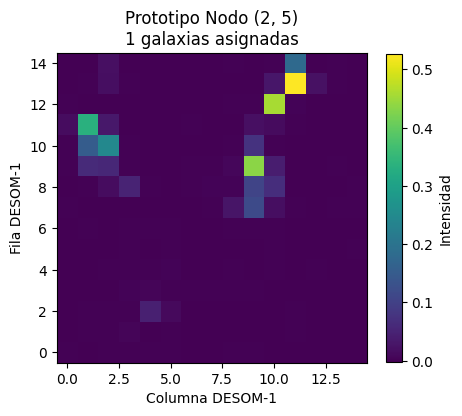


Galaxias asignadas a este nodo (Total: 1):


mangaID,split_desom2,n_spectra
1-422911,train,113


In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

print("=" * 70)
print("CELDA 5.3 — EXPLORADOR INTERACTIVO DESOM-2")
print("=" * 70)

# --- Rutas de los resultados de la Etapa 4 ---
assign_path = CTX.desom2_dir / 'galaxy_assignments.csv'
proto_path = CTX.desom2_dir / 'decoded_prototypes.npz'

if not assign_path.exists() or not proto_path.exists():
    print("⚠️ Faltan datos de la Etapa 4. Asegúrate de que el pipeline haya concluido.")
else:
    # 1. Cargar datos
    df_assign = pd.read_csv(assign_path)
    with np.load(proto_path, allow_pickle=False) as z:
        prototypes = z['fingerprints']  # Shape: (n_nodes, H_d1, W_d1, 1)
        map_size = z['map_size']

    n_rows, n_cols = map_size
    n_nodes = n_rows * n_cols

    # 2. Crear Widgets
    style = {'description_width': 'initial'}
    row_slider = widgets.IntSlider(
        min=0, max=n_rows-1, step=1, value=n_rows//2,
        description='Fila (Row):', style=style
    )
    col_slider = widgets.IntSlider(
        min=0, max=n_cols-1, step=1, value=n_cols//2,
        description='Columna (Col):', style=style
    )

    # Output donde se dibujarán los gráficos y tablas
    out = widgets.Output()

    # 3. Función de actualización
    def update_explorer(change):
        with out:
            clear_output(wait=True)
            r = row_slider.value
            c = col_slider.value
            node_idx = r * n_cols + c

            # Filtrar galaxias en este nodo
            node_gals = df_assign[(df_assign['row'] == r) & (df_assign['col'] == c)]

            # Renderizar gráfico
            fig, ax = plt.subplots(figsize=(5, 5))
            # Extraer el fingerprint base (quitamos la dimensión del canal extra si existe)
            fp = prototypes[node_idx, :, :, 0]

            im = ax.imshow(fp, cmap='viridis', origin='lower')
            ax.set_title(f'Prototipo Nodo ({r}, {c})\n{len(node_gals)} galaxias asignadas', fontsize=12)
            ax.set_xlabel('Columna DESOM-1')
            ax.set_ylabel('Fila DESOM-1')
            fig.colorbar(im, ax=ax, shrink=0.8, label='Intensidad')
            plt.show()

            # Mostrar tabla de galaxias
            if len(node_gals) > 0:
                print(f"\nGalaxias asignadas a este nodo (Total: {len(node_gals)}):")
                display_df = node_gals[['mangaID', 'split_desom2', 'n_spectra']].sort_values('split_desom2')
                display(display_df.head(15).style.hide(axis='index'))

                if len(node_gals) > 15:
                    print(f"... y {len(node_gals) - 15} galaxias más.")
            else:
                print("\n(Nodo vacío: No hay galaxias agrupadas aquí)")

    # 4. Conectar observadores
    row_slider.observe(update_explorer, names='value')
    col_slider.observe(update_explorer, names='value')

    # 5. Desplegar UI
    controls = widgets.HBox([row_slider, col_slider])
    display(controls)
    display(out)

    # Inicializar la primera vista
    update_explorer(None)

```markdown
# ============================================================================
# CELDA 5.4 — EXPLORADOR INTERACTIVO DESOM-1 Y FINGERPRINTS
# ============================================================================
# Esta celda proporciona dos pestañas interactivas:
#  1. Prototipos DESOM-1: Permite navegar por la cuadrícula (ej. 15x15) y ver
#     el espectro decodificado que aprendió el modelo en cada nodo.
#  2. Fingerprints: Permite seleccionar una galaxia por su mangaID para ver
#     su "huella dactilar" (cómo se distribuyen sus espectros en DESOM-1).
```

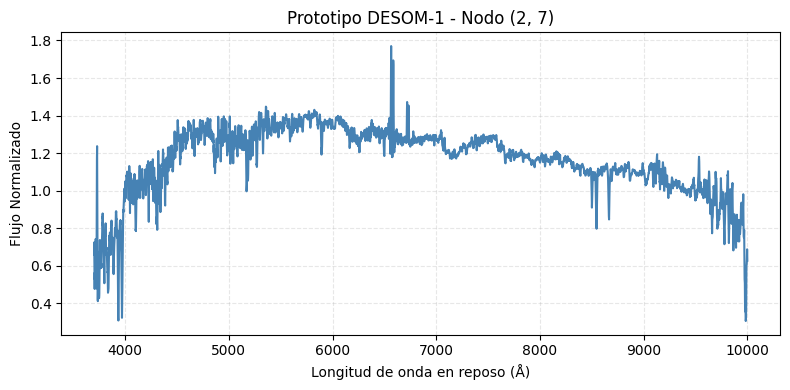

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import matplotlib.pyplot as plt
import numpy as np

print("=" * 70)
print("CELDA 5.4 — EXPLORADOR INTERACTIVO DESOM-1 Y FINGERPRINTS")
print("=" * 70)

desom1_proto_path = CTX.desom1_dir / 'decoded_prototypes.npz'
fp_path = CTX.fingerprints_dir / 'fingerprints.npz'

if not desom1_proto_path.exists() or not fp_path.exists():
    print("⚠️ Faltan datos de la Etapa 3. Asegúrate de que haya concluido correctamente.")
else:
    # 1. Cargar prototipos DESOM-1
    with np.load(desom1_proto_path, allow_pickle=False) as z:
        d1_protos = z['spectra']
        wave_rest = z['wave_rest']
        d1_map_size = z['map_size']
    n_rows_d1, n_cols_d1 = d1_map_size

    # 2. Cargar Fingerprints
    with np.load(fp_path, allow_pickle=False) as z:
        mangaIDs = z['mangaID']
        fingerprints = z['counts']
        n_spectra_fp = z['n_spectra']

    # ==========================================
    # INTERFAZ 1: PROTOTIPOS DESOM-1
    # ==========================================
    out_proto = widgets.Output()
    style = {'description_width': 'initial'}
    row_slider_d1 = widgets.IntSlider(min=0, max=n_rows_d1-1, step=1, value=n_rows_d1//2, description='Fila:', style=style)
    col_slider_d1 = widgets.IntSlider(min=0, max=n_cols_d1-1, step=1, value=n_cols_d1//2, description='Columna:', style=style)

    def update_proto(change):
        with out_proto:
            clear_output(wait=True)
            r = row_slider_d1.value
            c = col_slider_d1.value
            idx = r * n_cols_d1 + c

            fig, ax = plt.subplots(figsize=(8, 4))
            ax.plot(wave_rest, d1_protos[idx], color='steelblue', lw=1.5)
            ax.set_title(f'Prototipo DESOM-1 - Nodo ({r}, {c})', fontsize=12)
            ax.set_xlabel('Longitud de onda en reposo (Å)')
            ax.set_ylabel('Flujo Normalizado')
            ax.grid(alpha=0.3, linestyle='--')
            plt.tight_layout()
            plt.show()

    row_slider_d1.observe(update_proto, names='value')
    col_slider_d1.observe(update_proto, names='value')

    # ==========================================
    # INTERFAZ 2: FINGERPRINTS
    # ==========================================
    out_fp = widgets.Output()
    gal_dropdown = widgets.Dropdown(options=list(mangaIDs), description='Galaxia (mangaID):', style=style)

    def update_fp(change):
        with out_fp:
            clear_output(wait=True)
            gal = gal_dropdown.value
            idx = np.where(mangaIDs == gal)[0][0]
            fp = fingerprints[idx].reshape(d1_map_size)

            fig, ax = plt.subplots(figsize=(5, 5))
            im = ax.imshow(fp, cmap='Blues', origin='lower')
            ax.set_title(f'Fingerprint de {gal}\n({n_spectra_fp[idx]} espectros candidatos)', fontsize=12)
            ax.set_xlabel('Columna DESOM-1')
            ax.set_ylabel('Fila DESOM-1')
            fig.colorbar(im, ax=ax, label='Cantidad de espectros', shrink=0.8)
            plt.tight_layout()
            plt.show()

    gal_dropdown.observe(update_fp, names='value')

    # ==========================================
    # ENSAMBLAR Y DESPLEGAR
    # ==========================================
    tab = widgets.Tab(children=[
        widgets.VBox([widgets.HBox([row_slider_d1, col_slider_d1]), out_proto]),
        widgets.VBox([gal_dropdown, out_fp])
    ])
    tab.set_title(0, 'Prototipos DESOM-1 (Espectros)')
    tab.set_title(1, 'Fingerprints (Galaxias)')

    display(tab)

    # Render inicial
    update_proto(None)
    update_fp(None)

```markdown
# ============================================================================
# CELDA 5.5 — GRÁFICOS ADICIONALES: U-MATRIX Y DISTANCIAS TOPOLÓGICAS
# ============================================================================
# La Matriz Unificada de Distancias (U-Matrix) es una técnica estándar en SOM
# para visualizar la topología del mapa. Representa la distancia media de
# cada nodo respecto a sus vecinos directos, permitiendo identificar
# visualmente las fronteras de los clústeres (valores altos) y las
# agrupaciones densas (valores bajos).
```

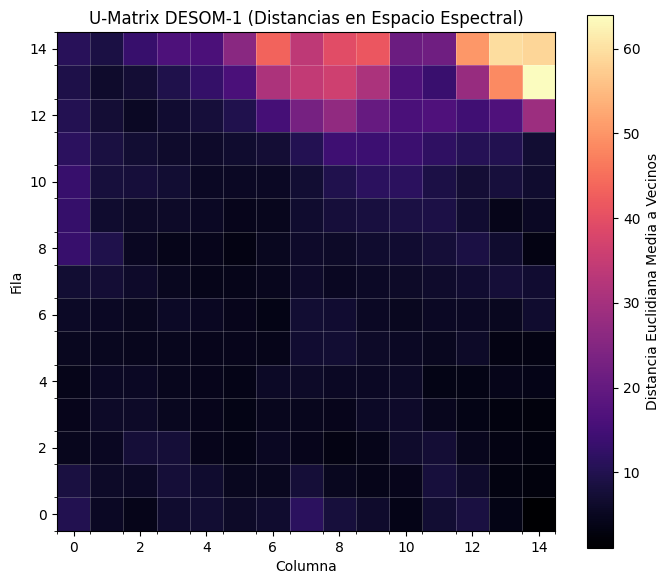

💡 TIP: Los valores ALTOS (colores claros) indican fronteras entre clústeres.
        Los valores BAJOS (colores oscuros) indican regiones muy similares.


In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import matplotlib.pyplot as plt
import numpy as np

print("=" * 70)
print("CELDA 5.5 — EXPLORADOR DE U-MATRIX (TOPOLOGÍA)")
print("=" * 70)

def calc_umatrix(prototypes, map_size):
    """Calcula la U-Matrix (distancia media a los vecinos) para un SOM 2D."""
    h, w = map_size
    u_matrix = np.zeros((h, w))
    # Aplanar las dimensiones adicionales (canales/espectros)
    flat_protos = prototypes.reshape(h, w, -1)

    for r in range(h):
        for c in range(w):
            dists = []
            p = flat_protos[r, c]
            if r > 0: dists.append(np.linalg.norm(p - flat_protos[r-1, c]))
            if r < h-1: dists.append(np.linalg.norm(p - flat_protos[r+1, c]))
            if c > 0: dists.append(np.linalg.norm(p - flat_protos[r, c-1]))
            if c < w-1: dists.append(np.linalg.norm(p - flat_protos[r, c+1]))
            u_matrix[r, c] = np.mean(dists)

    return u_matrix

desom1_proto_path = CTX.desom1_dir / 'decoded_prototypes.npz'
desom2_proto_path = CTX.desom2_dir / 'decoded_prototypes.npz'

if not desom1_proto_path.exists() or not desom2_proto_path.exists():
    print("⚠️ Faltan datos de los prototipos. Ejecuta primero Etapa 3 y Etapa 4.")
else:
    # Interfaz
    plot_dropdown = widgets.Dropdown(
        options=['U-Matrix DESOM-1 (Espectros)', 'U-Matrix DESOM-2 (Galaxias)'],
        description='Ver Mapa:',
        style={'description_width': 'initial'}
    )
    out_umatrix = widgets.Output()

    def update_umatrix(change):
        with out_umatrix:
            clear_output(wait=True)
            fig, ax = plt.subplots(figsize=(7, 6))

            if 'DESOM-1' in plot_dropdown.value:
                with np.load(desom1_proto_path, allow_pickle=False) as z:
                    protos = z['spectra']
                    msize = z['map_size']
                title = 'U-Matrix DESOM-1 (Distancias en Espacio Espectral)'
                cmap = 'magma'
            else:
                with np.load(desom2_proto_path, allow_pickle=False) as z:
                    protos = z['fingerprints']
                    msize = z['map_size']
                title = 'U-Matrix DESOM-2 (Distancias en Espacio de Fingerprints)'
                cmap = 'inferno'

            umat = calc_umatrix(protos, msize)

            im = ax.imshow(umat, cmap=cmap, origin='lower')
            ax.set_title(title, fontsize=12)
            ax.set_xlabel('Columna')
            ax.set_ylabel('Fila')

            # Añadir grid sutil para delimitar nodos
            ax.set_xticks(np.arange(-.5, msize[1], 1), minor=True)
            ax.set_yticks(np.arange(-.5, msize[0], 1), minor=True)
            ax.grid(which='minor', color='w', linestyle='-', linewidth=0.5, alpha=0.3)

            fig.colorbar(im, ax=ax, label='Distancia Euclidiana Media a Vecinos')
            plt.tight_layout()
            plt.show()

            print("💡 TIP: Los valores ALTOS (colores claros) indican fronteras entre clústeres.")
            print("        Los valores BAJOS (colores oscuros) indican regiones muy similares.")

    plot_dropdown.observe(update_umatrix, names='value')
    display(plot_dropdown, out_umatrix)
    update_umatrix(None)

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

print("=" * 70)
print("CELDA 5.6 — MAPAS DE PROPIEDADES SOM (HIT MAPS Y S/N)")
print("=" * 70)

# --- Rutas de datos ---
bmu_d1_path = CTX.fingerprints_dir / 'spectra_bmu.csv'
assign_d2_path = CTX.desom2_dir / 'galaxy_assignments.csv'
selection_path = CTX.run_dir / 'selection.csv'

if not bmu_d1_path.exists() or not assign_d2_path.exists():
    print("⚠️ Faltan datos (spectra_bmu.csv o galaxy_assignments.csv). Ejecuta las Etapas 3 y 4.")
else:
    # Cargar datos
    df_bmu1 = pd.read_csv(bmu_d1_path)
    df_bmu2 = pd.read_csv(assign_d2_path)
    df_sel = pd.read_csv(selection_path)

    # Unir Redshift a DESOM-2
    df_bmu2 = df_bmu2.merge(df_sel[['mangaID', 'z']], on='mangaID', how='left')

    # Extraer map_sizes de la config actual (o usar estáticos como fallback)
    try:
        msize_d1 = tuple(CTX.cfg['desom1']['map_size'])
        msize_d2 = tuple(CTX.cfg['desom2']['map_size'])
    except:
        msize_d1 = (15, 15)
        msize_d2 = (10, 10)

    # --- Interfaz ---
    prop_dropdown = widgets.Dropdown(
        options=[
            'DESOM-1: Hit Map (Conteo de Espectros)',
            'DESOM-1: Promedio de S/N',
            'DESOM-2: Hit Map (Conteo de Galaxias)',
            'DESOM-2: Redshift Promedio (z)'
        ],
        description='Propiedad:',
        style={'description_width': 'initial'},
        layout={'width': '400px'}
    )
    out_props = widgets.Output()

    def update_property_map(change):
        with out_props:
            clear_output(wait=True)
            fig, ax = plt.subplots(figsize=(6, 5))

            opt = prop_dropdown.value
            if 'DESOM-1' in opt:
                msize = msize_d1
                n_nodes = msize[0] * msize[1]
                grid = np.zeros(n_nodes)
                cmap = 'Blues' if 'Hit' in opt else 'viridis'
                title = opt

                if 'Hit' in opt:
                    counts = df_bmu1['bmu'].value_counts()
                    grid[counts.index] = counts.values
                    label = 'Cantidad de Espectros'
                elif 'S/N' in opt:
                    means = df_bmu1.groupby('bmu')['sn_cont_corrected'].mean()
                    grid[means.index] = means.values
                    label = 'S/N Promedio'
            else:
                msize = msize_d2
                n_nodes = msize[0] * msize[1]
                grid = np.zeros(n_nodes)
                cmap = 'Oranges' if 'Hit' in opt else 'plasma'
                title = opt

                if 'Hit' in opt:
                    counts = df_bmu2['bmu'].value_counts()
                    grid[counts.index] = counts.values
                    label = 'Cantidad de Galaxias'
                elif 'Redshift' in opt:
                    means = df_bmu2.groupby('bmu')['z'].mean()
                    grid[means.index] = means.values
                    label = 'Redshift Promedio'

            # Reshape a cuadrícula
            grid_2d = grid.reshape(msize)

            # Maskeros para no colorear fuertemente los nodos vacíos en mapas de promedios
            if 'Promedio' in opt:
                grid_2d = np.ma.masked_where(grid_2d == 0, grid_2d)
                cmap = plt.cm.get_cmap(cmap).copy()
                cmap.set_bad(color='lightgray')

            im = ax.imshow(grid_2d, cmap=cmap, origin='lower')
            ax.set_title(title, fontsize=12)
            ax.set_xlabel('Columna')
            ax.set_ylabel('Fila')

            ax.set_xticks(np.arange(-.5, msize[1], 1), minor=True)
            ax.set_yticks(np.arange(-.5, msize[0], 1), minor=True)
            ax.grid(which='minor', color='w', linestyle='-', linewidth=0.5, alpha=0.3)

            fig.colorbar(im, ax=ax, label=label)
            plt.tight_layout()
            plt.show()

            if 'Promedio' in opt:
                print("💡 TIP: Los nodos en color gris claro no tienen datos asignados (están vacíos).")

    prop_dropdown.observe(update_property_map, names='value')
    display(prop_dropdown, out_props)
    update_property_map(None)


CELDA 5.6 — MAPAS DE PROPIEDADES SOM (HIT MAPS Y S/N)


Dropdown(description='Propiedad:', layout=Layout(width='400px'), options=('DESOM-1: Hit Map (Conteo de Espectr…

Output()